# BIL545 · Proje 1 · Vizeye kadarki konular (2.–7. haftalar)
**Veri Madenciliğinde İleri Konular · 2026–2027 Güz** · **Vize notu** · Teslim ve sunum: **8. hafta**

Bu defter proje çalışmamız için hazırladığımız dosyadır. Grubumuz defteri kendi Drive'ına kopyalar (**Dosya → Drive'a kopya kaydet**), doldurur ve **iki yere** yükler: GitHub deposundaki `proje1/` klasörüne ve STIX'teki ödev alanına. Bütün yazılı cevaplar bu defterin metin hücrelerindedir; ayrı bir rapor yoktur.

**Kapsam grup tipine göre:** 1–3 kişilik gruplar Bölüm 1–3'ü, 4 kişilik gruplar ek olarak Ek paket 1'i, 5 kişilik gruplar Ek paket 1 ve 2'yi yapar. Grubunuzun yapmadığı ek paket bölümlerini silin. Defterin sonundaki **katkı beyanı puanlanır**; sunumda her üye en az bir alt başlığı anlatır.

**Teslimden önce:** Çalışma zamanını sıfırlayıp **Çalışma Zamanı → Tümünü çalıştır** ile defteri baştan sona hatasız çalıştırın.

**Puanlama:** Başarım puanlanmaz. Her bölüm kurulumun doğruluğu (%30), kararların gerekçesi (%25), dürüst raporlama (%25), yorum (%15) ve teknik düzene (%5) göre puanlanır. Ayrıntılar: *Proje 1 ve Proje 2 Yönergesi*.

## Grup bilgisi
|Ad Soyad | Öğrenci no |
|---|---|
|Melike Duygu YILDIRIM| 264312005|
|Vildan ÇAP  |264329001 |
|Melisa LOTFIAZAR| 264312902 |
|WAIL ABDULRAQEB MOHAMMED NOMAN | 264312901 |


**Grup adı:**  Atmaca

**GitHub deposu:**  https://github.com/atmaca-team/atmaca-hotel-booking-cancellation

**Seçilen konu:** 9.6 Otel rezervasyonlarında iptal  
**Grup tipi:** 4 kişi: + Ek paket 1

**Veri kümesi ve sorumuz (tek cümle):** Hotel Booking Demand -İptal riski rezervasyon anında öngörülebilir mi?

## Hazırlık

In [1]:
# Sonuçları etkilemeyen uyarıları gizliyoruz:
# - Colab'ın altyapısından (jupyter_client) gelen utcnow uyarısı,
# - kütüphane sürümleri arasındaki uyumsuzluktan gelen kullanımdan kaldırma (DeprecationWarning) uyarıları
#   (ör. scikit-learn → SciPy L-BFGS-B, matplotlib → pyparsing).
# Önemli olabilecek uyarılar (ör. ConvergenceWarning, UserWarning) görünmeye devam ediyor.
import os, warnings, datetime as _dt

# Colab her hücreyi kendi uyarı ayarlarıyla çalıştırdığı için bu filtreler sonraki hücrelere taşınmayabiliyor.
# Bu yüzden filtreleri bir fonksiyona koyuyoruz; uyarı üreten hücrelerin başında uyarilari_sustur() ile yeniden uyguluyoruz.
def uyarilari_sustur():
    os.environ["PYTHONWARNINGS"] = "ignore::DeprecationWarning"   # n_jobs=-1 ile açılan paralel işçiler için
    warnings.filterwarnings("ignore", category=DeprecationWarning)
    warnings.filterwarnings("ignore", message=r".*deprecated - use.*")           # matplotlib/pyparsing
    warnings.filterwarnings("ignore", message=r".*datetime\.datetime\.utcnow\(\) is deprecated.*")
uyarilari_sustur()
try:                                                       # her hücreden önce de otomatik uygula
    get_ipython().events.register("pre_run_cell", lambda *_: uyarilari_sustur())
except Exception:
    pass

# utcnow uyarısını üreten fonksiyonu aynı değeri veren güncel sürümle değiştiriyoruz.
try:
    import jupyter_client.session as _js
    _js.utcnow = lambda: _dt.datetime.now(_dt.timezone.utc)   # eskisiyle aynı: UTC saat, saat dilimi bilgisiyle
except Exception:
    pass

# Uyarı yine de basılmak istenirse yalnızca utcnow uyarısını ekrana yazdırmadan geçiyoruz.
_uyari_goster = warnings.showwarning
def _utcnow_haric(message, category, filename, lineno, file=None, line=None):
    if "utcnow" in str(message):
        return
    _uyari_goster(message, category, filename, lineno, file, line)
warnings.showwarning = _utcnow_haric

In [2]:
!pip -q install --no-deps mlxtend==0.25.0

import json, os, re, shutil, subprocess, sys, time, urllib.request, warnings
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from scipy.stats import binomtest, chi2, t as t_dagilimi

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, make_scorer, precision_score
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_score, cross_validate)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeClassifier, export_text

from mlxtend.frequent_patterns import apriori
from google.colab import files

SEED = 42                      # tek tohum: bütün bölmeleri ve modelleri bu sayıdan türetiyoruz
np.random.seed(SEED)
print("Python      ", sys.version.split()[0]); print("numpy       ", np.__version__)
print("pandas      ", pd.__version__);          print("scikit-learn", sklearn.__version__)
print("matplotlib  ", matplotlib.__version__)

# Defterdeki bütün çapraz doğrulamalarda aynı düzeni kullanıyoruz: katmanlı 5 kat × 5 tekrar = 25 bölme.
# Aynı tohumla her çağrıda aynı bölmeleri elde ediyoruz; böylece bölümler arasındaki sonuçları karşılaştırabiliyoruz.

def cv_olustur():

    return RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)




Python       3.13.18
numpy        2.4.6
pandas       2.2.3
scikit-learn 1.6.1
matplotlib   3.10.0


### Veriyi yükleme
**Kaynak makale:** Antonio, N., de Almeida, A. ve Nunes, L. (2019). Hotel booking demand datasets. *Data in Brief*, 22, 41–49. https://doi.org/10.1016/j.dib.2018.11.126

**Veri dosyası:** Makaledeki iki otel dosyasını (H1 ve H2) birleştiren TidyTuesday kopyasını okuyoruz: https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv. Yönerge gereği veriyi grubumuzun deposuna koymadık; defter her çalıştığında bu adresten indiriyor.

In [3]:
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"

df = pd.read_csv(url)

print("Veri boyutu:", df.shape)
df.head()

Veri boyutu: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


# Bölüm 1 · Veri, ön işleme ve sızıntı *(ağırlık 30)*
**Makale:** Kaufman vd. (2012). *Leakage in data mining: Formulation, detection, and avoidance.*

**Makale okuma notumuz:**

Kaufman vd. (2012), modelin tahmin anında erişemeyeceği bir bilginin eğitim verisine karışmasını veri sızıntısı olarak tanımlıyor ve iki kaynağını ayırıyor: özniteliklerden gelen sızıntı (sonucu sonradan taşıyan sütunlar) ve eğitim örneklerinden gelen sızıntı (test bilgisinin eğitime karışması; örneğin aynı kaydın kopyasının iki tarafta bulunması). Önerdikleri yol, her sütunun ne zaman oluştuğunu baştan belirlemek ve yalnızca tahmin anında bilinen bilgiyi kullanmak; çünkü sızıntıyı sonradan yakalamak zordur. Bu yüzden tahmin anını rezervasyonun ilk oluşturulduğu an olarak kabul ettik ve öznitelikleri bu ana göre seçtik. Test bölümünden bilgi öğrenilmesin diye ön işleme adımlarını Pipeline içinde tuttuk, yinelenen satırların etkisini de ayrıca ölçtük.

### 1.1 Veri künyesi
| Soru | Cevap |
|---|---|
| Kim, hangi amaçla topladı? |Veriler, Portekiz’deki iki otelin rezervasyon sistemlerinden alınmış. Araştırmacılar Nuno Antonio, Ana de Almeida ve Luis Nunes bu verileri hazırlayıp paylaşmış. Yazarlar, bilimsel ve eğitim amaçlı gerçek işletme verisinin az bulunduğunu belirtiyor ve veriyi gelir yönetimi, makine öğrenmesi ve veri madenciliği alanlarında araştırma ve eğitimde kullanılsın diye paylaşıyor. Rezervasyon iptalinin tahmini bu kullanımlardan yalnızca biri. Gerçek otel verisi olduğu için otel ve müşteri kimliğine ait bütün alanlar silinmiş.|
| Hangi dönemi kapsıyor? |Varış tarihi 1 Temmuz 2015–31 Ağustos 2017 arasında olan rezervasyonları kapsıyor. Buradaki tarihler, rezervasyonun yapıldığı tarih değil, otele planlanan geliş tarihi. Resort Hotel’de 40.060, City Hotel’de 79.330 olmak üzere toplam 119.390 kayıt var. |
| Hedef gerçek olgu mu, vekil mi? |Hedef değişkenimiz is_canceled. 1 değeri yalnızca iptal edilen rezervasyonları (43.017) değil, gelmeyen misafirleri (No-Show, 1.207) de kapsıyor (aşağıdaki kod). Yani hedef "rezervasyonun gerçekleşmemesi" için kayıtlı bir vekildir: iki farklı olayı birleştirir ve müşterinin niyetini veya iptal nedenini göstermez.|
| Kimler eksik temsil ediliyor olabilir? |Veriler sadece Portekiz’deki iki otelden geliyor. Bu yüzden farklı ülkeler, otel türleri ve dönemler hakkında aynı sonuçları bekleyemeyiz. Ayrıca kişisel kimlik bilgileri kaldırıldığı için hangi kayıtların aynı müşteriye ait olduğunu kesin olarak bilemiyoruz.|
| Lisans |Orijinal makale ve veri CC BY 4.0 lisansıyla paylaşılmış (Antonio vd., 2019, https://doi.org/10.1016/j.dib.2018.11.126).|

In [4]:
# 1.1'deki künye bilgilerini kendi dosyamızla karşılaştıralım.


# a) Otel başına kayıt sayısı.
print("Otel başına kayıt sayısı:")
print(df["hotel"].value_counts().to_string())

# b) Varış tarihi aralığı
# Ay adı metin olarak saklandığı için önce ay numarasına çeviriyoruz.

ay_no = pd.to_datetime(df["arrival_date_month"], format="%B").dt.month
varis_tarihi = pd.to_datetime(pd.DataFrame({
    "year": df["arrival_date_year"],
    "month": ay_no,
    "day": df["arrival_date_day_of_month"],
}))
print("\nİlk varış tarihi:", varis_tarihi.min().date(), "  Son varış tarihi:", varis_tarihi.max().date())

# c) Hedefin tanımı: is_canceled = 1 hangi rezervasyon durumlarını kapsıyor?
# Gelmeyen müşteriler (No-Show) hangi sınıfta? Bu, "iptal" kavramımızı belirler.

print("\nreservation_status × is_canceled:")
display(pd.crosstab(df["reservation_status"], df["is_canceled"]))

Otel başına kayıt sayısı:
hotel
City Hotel      79330
Resort Hotel    40060

İlk varış tarihi: 2015-07-01   Son varış tarihi: 2017-08-31

reservation_status × is_canceled:


is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


Veri setini rezervasyonların iptal edilip edilmeyeceğini tahmin etmek için seçtik. Kayıtlar gerçek otel rezervasyonlarından geliyor, fakat yalnızca Portekiz'deki iki oteli kapsadığı için bulguları bütün otellere genelleyemeyiz.

Makaledeki H1 ve H2 dosyalarında 31'er değişken bulunuyor. Kullandığımız birleşik dosyada otel türünü gösteren `hotel` sütunuyla birlikte toplam 32 sütun var. Kayıt sayılarını ve tarih aralığını kontrol ederek kullandığımız dosyanın kaynak makaleyle uyumlu olduğunu gördük.

Verilerin zamanını özellikle dikkate aldık. Makalede bazı alanların varıştan bir gün önceki durumunun yer alabildiği belirtiliyor. Biz ise rezervasyon oluşturulduğu andaki iptali öngörmek istediğimizden, bütün sütunların o tarihte bilindiğini varsaymadık. `reservation_status` ve `reservation_status_date` alanlarını bu nedenle modele almadık.

Hedef değişken `is_canceled`, yalnızca müşterinin bildirdiği iptalleri değil, sistemde **No-Show** olarak kaydedilen gerçekleşmeyen rezervasyonları da kapsıyor. Dolayısıyla burada müşterinin iptal gerekçesini değil, sistemde kaydedilmiş rezervasyon sonucunu tahmin ediyoruz. Makale No-Show'u, müşterinin otele giriş yapmadığı ve nedenini otele bildirdiği rezervasyonlar olarak tanımlıyor. `reservation_status` rezervasyonun son durumunu gösterdiği için geç gelip giriş yapan müşteriler Check-Out sınıfında yer alıyor; No-Show yalnızca o rezervasyonla hiç giriş yapılmadığını gösteriyor. Otelin bir rezervasyonu hangi koşulda No-Show olarak kapattığı makalede açıklanmıyor. Hocanın örnek sorusundaki "iptal" kavramını bu yüzden "rezervasyonun gerçekleşmemesi" olarak ele aldık. Rezervasyon anında bir müşterinin ileride iptal mi edeceğini, yoksa hiç gelmeyecek mi olduğunu ayırt edemiyoruz; otel açısından her ikisi de oda kullanımının ve beklenen gelirin gerçekleşmemesi riskini oluşturabilir. No-Show kayıtları 1 sınıfının yaklaşık %2,7'sini oluşturuyor. Bu oran sınıfın küçük bir kısmı olsa da No-Show ile iptalin nedenleri farklı olabileceğinden ikisini tek hedefte birleştirmeyi çalışmamızın sınırlılığı olarak görüyoruz.

**Kaynak:** Antonio, N., de Almeida, A. ve Nunes, L. (2019). *Hotel booking demand datasets*. *Data in Brief*, 22, 41–49. https://doi.org/10.1016/j.dib.2018.11.126

**Kullandığımız birleşik veri:** H1 ve H2 dosyalarını `hotel` sütunuyla birleştiren TidyTuesday kopyası, https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv. Yukarıdaki kayıt sayıları ve tarih aralığı bu dosyanın makalede açıklanan veriyle kayıt sayısı ve dönem bakımından uyumlu olduğunu gösteriyor; her hücrenin birebir aynı olduğunu bu karşılaştırmayla doğrulamıyoruz.

### 1.2 Keşifsel analiz
Boyut; saklama ve ölçek tipleri; hedef dağılımı; yinelenen satırlar; künye tablosu (tip, eksik oranı, farklı değer sayısı, sıfır oranı); şüpheli öznitelik listesi.

In [5]:

# 1. Veri boyutu ve hedef dağılımı

print("Veri boyutu (satır, sütun):", df.shape)

hedef_dagilimi = pd.DataFrame({
    "kayit_sayisi": df["is_canceled"].value_counts().sort_index(),
    "oran_yuzde": (df["is_canceled"].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("\nHedef değişken dağılımı (0: gerçekleşti, 1: iptal veya no-show):")
display(hedef_dagilimi)

# Otel türüne göre iptal oranı
# 1 Temmuz 2015 - 31 Ağustos 2017 arasında varış yapması planlanan rezervasyonlar.
otel_ozeti = df.groupby("hotel")["is_canceled"].agg(
    kayit_sayisi="size", iptal_sayisi="sum", iptal_orani="mean"
)
otel_ozeti["iptal_orani_yuzde"] = (otel_ozeti["iptal_orani"] * 100).round(2)
otel_ozeti = otel_ozeti.drop(columns="iptal_orani")
print("\nOtel türüne göre iptal dağılımı:")
display(otel_ozeti)
if len(otel_ozeti) > 1:
    fark = otel_ozeti["iptal_orani_yuzde"].max() - otel_ozeti["iptal_orani_yuzde"].min()
    print(f"İptal oranları arasındaki fark: {fark:.2f} yüzde puan")


# 2. Yinelenen kayıt kontrolü
# Aynı görünen satırlar gerçek mükerrer olmayabilir. Bu aşamada silmiyoruz.

yinelenen = int(df.duplicated().sum())
print(f"\nAynı görünen satır sayısı: {yinelenen} (%{yinelenen / len(df) * 100:.2f})")

# 3. Saklama ve ölçüm ölçekleri - öznitelik künyesi
# agent/company sayı olarak saklansa da nominal kategori kimlikleridir.

sayisal = df.select_dtypes(include="number")
sifir_oran_yuzde = (sayisal.eq(0).mean() * 100).round(2)
sifir_anlamsiz = [s for s in ["is_canceled", "agent", "company"] if s in sifir_oran_yuzde.index]
sifir_oran_yuzde.loc[sifir_anlamsiz] = np.nan

olcek_tipleri = {
    "hotel": "Nominal", "is_canceled": "Nominal (ikili)",
    "lead_time": "Oran", "arrival_date_year": "Aralık",
    "arrival_date_month": "Sıralı (döngüsel takvim)",
    "arrival_date_week_number": "Sıralı (döngüsel takvim)",
    "arrival_date_day_of_month": "Sıralı (döngüsel takvim)",
    "stays_in_weekend_nights": "Oran", "stays_in_week_nights": "Oran",
    "adults": "Oran", "children": "Oran", "babies": "Oran",
    "meal": "Nominal", "country": "Nominal", "market_segment": "Nominal",
    "distribution_channel": "Nominal", "is_repeated_guest": "Nominal (ikili)",
    "previous_cancellations": "Oran", "previous_bookings_not_canceled": "Oran",
    "reserved_room_type": "Nominal", "assigned_room_type": "Nominal",
    "booking_changes": "Oran", "deposit_type": "Nominal",
    "agent": "Nominal (kimlik)", "company": "Nominal (kimlik)",
    "days_in_waiting_list": "Oran", "customer_type": "Nominal",
    "adr": "Oran", "required_car_parking_spaces": "Oran",
    "total_of_special_requests": "Oran", "reservation_status": "Nominal",
    "reservation_status_date": "Aralık (tarih)"
}


kunye = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "olcek_tipi": pd.Series(olcek_tipleri),
    "eksik_sayi": df.isna().sum(),
    "eksik_oran_yuzde": (df.isna().mean() * 100).round(4),
    "farkli": df.nunique(dropna=True),
    "sifir_oran_yuzde": sifir_oran_yuzde
})
print("\nÖznitelik künye tablosu:")
display(kunye)
olceksiz = kunye.index[kunye["olcek_tipi"].isna()].tolist()
if olceksiz:
    print("Ölçüm ölçeği atanmayan sütunlar:", olceksiz)


# 4. Şüpheli öznitelikler
# 4.1 Kimlik niteliğinde sütun kontrolü
farkli = df.nunique(dropna=False)
kimlik_adaylari = farkli[farkli == len(df)].index.tolist()
print("\nHer satırda benzersiz değer taşıyan sütunlar:", kimlik_adaylari or "Yok")
print("Kategori kimliklerinin farklı değer sayıları:")
print(farkli[["agent", "company"]].to_string())

# agent/company acente ve şirket kimliğidir; rezervasyonların benzersiz ID'si değildir.

# 4.2 Hedef sızıntısı açısından ön değerlendirme

supheli = {
    "reservation_status": ("Kesin sızıntı",
                           "Nihai durumdur; Canceled + No-Show = IsCanceled=1 (H1: 10 831 + 291 = 11 122)."),
    "reservation_status_date": ("Kesin sızıntı",
                                "Rezervasyonun son durumunun belirlendiği tarihtir; iptal, check-out "
                                "veya no-show durumuyla ilişkilidir ve rezervasyon anında mevcut değildir."),
    "booking_changes": ("Yüksek zamansal risk", "PMS girişinden check-in/iptale kadarki değişiklik sayısıdır."),
    "assigned_room_type": ("Yüksek zamansal risk", "Atanan oda operasyon (ör. overbooking) veya müşteri talebiyle değişebilir."),
    "days_in_waiting_list": ("Yüksek zamansal risk", "Onay tarihi - PMS'ye giriş tarihi olarak hesaplanır; değer onay anında kesinleşir."),
    "deposit_type": ("Yüksek zamansal risk", "Varış/iptal tarihine kadar tespit edilen ödemelerden hesaplanır."),
    "country": ("Koşullu risk", "Ülke/uyruk bilgisi check-in sırasında netleşebilir; düzeltme yalnızca gelen misafirlerde yapılıyorsa değer hedefe bağlı hâle gelir."),
}
supheli_df = pd.DataFrame(
    [(sutun, grup, neden) for sutun, (grup, neden) in supheli.items() if sutun in df.columns],
    columns=["Öznitelik", "Grup", "Şüphe nedeni"]
)
print("\nVeri sızıntısı açısından incelenecek sütunlar:")
display(supheli_df)


# 4.3 Eksik değer ve kodlanmış eksik kontrolü

eksik_df = kunye.loc[kunye["eksik_sayi"] > 0, ["eksik_sayi", "eksik_oran_yuzde"]].copy()
eksik_df["anlami"] = np.where(
    eksik_df.index.isin(["agent", "company"]),
    "Uygulanamaz (NULL) [Antonio, s. 45]",
    "NaN; eksiklik nedeni 1.3'te incelenecek"
)
print("\nEksik değer içeren sütunlar:")
display(eksik_df.sort_values("eksik_sayi", ascending=False))

# meal: Undefined ve SC aynı anlama geliyor (yemek paketi yok).
print("\nmeal kodları: SC =", int(df["meal"].eq("SC").sum()),
      ", Undefined =", int(df["meal"].eq("Undefined").sum()))
for sutun in ["market_segment", "distribution_channel"]:
    print(f"{sutun} / Undefined: {int(df[sutun].eq('Undefined').sum())}")


# Aynı anlamdaki kodun otele göre değişip değişmediğini çapraz tabloyla sınıyoruz.
print("\nmeal kategorilerinin otel türüne göre dağılımı:")
display(pd.crosstab(df["meal"], df["hotel"]))

# 4.4 Olağan dışı değerler (veriyi değiştirmeden)

negatif_adr = int(df["adr"].lt(0).sum())
misafir_toplam = df[["adults", "children", "babies"]].sum(axis=1, min_count=3)
sifir_misafir = int(misafir_toplam.eq(0).sum())
print(f"\nNegatif ADR kayıt sayısı: {negatif_adr}")
print(f"Misafir toplamı sıfır olan kayıt sayısı: {sifir_misafir}")

# 4.5 Temel sayısal özet

print("\nSayısal değişkenlerin özeti:")
display(sayisal.drop(columns=sifir_anlamsiz, errors="ignore")
        .describe(percentiles=[0.25, 0.50, 0.75, 0.99]).T.round(2))

# Dağılımın uç kısmını görmek için ortalama/medyan ve %99/maksimum farkına bakıyoruz.

# 4.6 Yüksek sıfır oranlı sayısal sütunlar
print("\nSıfır oranı %90'ın üzerinde olan sütunlar:")
display(kunye.loc[kunye["sifir_oran_yuzde"] > 90,
                  ["dtype", "olcek_tipi", "sifir_oran_yuzde"]])



Veri boyutu (satır, sütun): (119390, 32)

Hedef değişken dağılımı (0: gerçekleşti, 1: iptal veya no-show):


,kayit_sayisi,oran_yuzde
is_canceled,,
0,75166,62.96
1,44224,37.04



Otel türüne göre iptal dağılımı:


,kayit_sayisi,iptal_sayisi,iptal_orani_yuzde
hotel,,,
City Hotel,79330,33102,41.73
Resort Hotel,40060,11122,27.76


İptal oranları arasındaki fark: 13.97 yüzde puan

Aynı görünen satır sayısı: 31994 (%26.80)

Öznitelik künye tablosu:


,dtype,olcek_tipi,eksik_sayi,eksik_oran_yuzde,farkli,sifir_oran_yuzde
adr,float64,Oran,0,0.0000,8879,1.64
adults,int64,Oran,0,0.0000,14,0.34
agent,float64,Nominal (kimlik),16340,13.6862,333,NaN
arrival_date_day_of_month,int64,Sıralı (döngüsel takvim),0,0.0000,31,0.00
arrival_date_month,object,Sıralı (döngüsel takvim),0,0.0000,12,NaN
arrival_date_week_number,int64,Sıralı (döngüsel takvim),0,0.0000,53,0.00
arrival_date_year,int64,Aralık,0,0.0000,3,0.00
assigned_room_type,object,Nominal,0,0.0000,12,NaN
babies,int64,Oran,0,0.0000,5,99.23
booking_changes,int64,Oran,0,0.0000,21,84.86


... (6 outputs left out)


Negatif ADR kayıt sayısı: 1
Misafir toplamı sıfır olan kayıt sayısı: 180

Sayısal değişkenlerin özeti:


,count,mean,std,min,25%,50%,75%,99%,max
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,444.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,4.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,10.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,3.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,2.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,0.0,10.0
is_repeated_guest,119390.0,0.03,0.18,0.00,0.00,0.00,0.0,1.0,1.0



Sıfır oranı %90'ın üzerinde olan sütunlar:


,dtype,olcek_tipi,sifir_oran_yuzde
babies,int64,Oran,99.23
children,float64,Oran,92.80
days_in_waiting_list,int64,Oran,96.90
is_repeated_guest,int64,Nominal (ikili),96.81
previous_bookings_not_canceled,int64,Oran,96.97
previous_cancellations,int64,Oran,94.57
required_car_parking_spaces,int64,Oran,93.79


### 1.2 Keşifsel Veri Analizi: Bulgular ve Yorumlarımız

Veri setimizde **119.390 satır ve 32 sütun** bulunuyor. Resort Hotel için 40.060, City Hotel için 79.330 kayıt saydık; bu sayılar kaynak makaledeki bilgilerle uyuşuyor.

Hedef değişkeni incelediğimizde 75.166 rezervasyonun (%62,96) gerçekleştiğini, 44.224 rezervasyonun (%37,04) ise iptal edildiğini ya da misafirin gelmediğini gördük. Sınıflar eşit sayıda değil. Her rezervasyona "iptal değil" diyen bir model yaklaşık %63 doğruluk alır ama hiçbir iptali yakalayamaz. Bu yüzden sonraki bölümlerde iptal sınıfının precision, recall ve F1 değerlerine bakmaya karar verdik.

Otel türlerine göre iptal oranları farklı çıktı: City Hotel'de **%41,73**, Resort Hotel'de **%27,76**. Bu farkın arkasında müşteri ve rezervasyon profillerinin farkı da olabilir; bu yüzden farkı otel türünün "etkisi" olarak yorumlamadık.

Tüm sütunlar birlikte karşılaştırıldığında **31.994 satır (%26,80) başka bir satırla tüm sütunlarda aynı değerleri taşıyor**. Kişisel tanımlayıcılar silindiği için bunların aynı rezervasyonun iki kaydı mı, yoksa aynı gün aynı acenteden yapılmış ayrı rezervasyonlar mı olduğunu bilemiyoruz; bu yüzden silmedik. Ancak kopyalar çapraz doğrulamada hem eğitim hem test katına düşebilir ve skorları iyimser gösterebilir.

`agent` ve `company` sayı olarak saklansa da birer **kimlik kodudur** (nominal); büyüklük sıraları anlamsız olduğu için kategorik olarak ele aldık. Ay, hafta numarası ve ayın günü **sıralı ve döngüsel** takvim değişkenleri; `arrival_date_month` modelde kategorik olarak kullanılıyor.

Boş görünen değerler en çok `company` (%94,31) ve `agent` (%13,69) sütunlarında. Kaynak makaleye göre buradaki `NULL` "acente/şirket yok" anlamına geliyor; bu yüzden 1.3'te bunları ayrı kategorilere çevirdik. Ancak yalnızca veriye bakarak tüm boşlukların yapısal olduğunu kesinleştiremiyoruz. `country` sütununda 488, `children` sütununda 4 gerçek eksik var. `meal` sütunundaki `Undefined` ile `SC` makalede aynı anlamda ("yemek paketi yok"); modelde bu iki kategoriyi birleştirdik (1.4'ten itibaren). `market_segment` ve `distribution_channel`'daki az sayıdaki `Undefined`'ın anlamı açıklanmadığı için eksik değer adayı olarak ele aldık.

**Veri sızıntısı kararı:** Tahmin anımız rezervasyonun oluşturulduğu an. Kararımızın kuralı şu: bir sütun ancak değeri rezervasyon anında **giriliyorsa** modele girer.
- `reservation_status` ve `reservation_status_date` sonucu taşıyor: **hedef sonucunu doğrudan taşıdıkları için çıkardık.**
- `booking_changes`, `assigned_room_type`, `days_in_waiting_list` rezervasyondan sonra oluşuyor ya da değişiyor: **çıkardık.**
- `deposit_type` makaleye göre varış/iptal tarihine kadar yapılan ödemelerden hesaplanıyor; `country` çoğu zaman check-in'de netleşiyor ve iptal edenlerde varsayılan değerde kalabiliyor. İkisini **başlangıç modeline almadık**; etkilerini 2.1'deki ek kontrolde ölçtük.
- `adults`, `children`, `babies`, `stays_in_*` ve `meal` için makale de check-in sırasında düzeltilebileceklerini söylüyor. Bu sütunları yine de modelde tuttuk. Bu bilgileri müşteri **rezervasyon sırasında beyan ediyor**, yani tahmin anında zaten bir değerleri var. Makaleye göre değerler varıştan bir gün önceki kayıttan alınıyor; check-in'de yapılan düzeltmelerin bu sütunlara yansımaması beklenir. `country`'den farkları da burada: ülke rezervasyonda çoğu zaman hiç girilmeden varsayılan bir değerle kalabiliyor, kişi ve gece sayısı ise baştan biliniyor ve yalnızca sonradan güncellenebiliyor. Varıştan önceki bir güncellemenin bu değerleri hedefe bağlı hâle getirme riskini tamamen dışlayamıyoruz; bunu bir sınırlılık olarak not ettik.
- `total_of_special_requests`, `required_car_parking_spaces` ve `adr` için makale kayıt zamanını açıkça belirtmiyor; temkinli olmak için başlangıç modeline almadık.
- `arrival_date_year`, `arrival_date_week_number` ve `arrival_date_day_of_month` rezervasyon anında biliniyor, sızıntı riski yok; yine de modele almadık. Yıl yalnızca 2015–2017 değerlerini alıyor, yeni bir yıl için bir şey söylemiyor; hafta numarası ayla neredeyse aynı bilgiyi taşıyor; ayın gününün iptali etkilemesi için bir neden göremedik. Mevsim bilgisini `arrival_date_month` ile verdik.

**Olağan dışı değerler.** Negatif `adr`'li **1 kayıt** ve yetişkin, çocuk ve bebek toplamı sıfır olan **180 kayıt** var. Nedenlerini bilmediğimiz ve oranları çok küçük olduğu (%0,15) için silmedik ya da değiştirmedik. Sıfır oranı %90'ın üzerinde olan sütunlarda (`babies`, `previous_cancellations` gibi) sıfır geçerli bir değerdir ("bebek yok", "önceki iptal yok"); eksik sayılmaz.

### 1.3 Eksiklik analizi
Eksik kodlarını `NaN`'a çevirin; deseni görselleştirin; en çok eksiği olan iki sütun için MCAR / MAR / MNAR tahmini; `add_indicator` etkisi.

Ham dosyadaki eksik / belirsiz kodlar:


,NULL,NA,Undefined
children,0,4,0
meal,0,0,1169
country,488,0,0
market_segment,0,0,2
distribution_channel,0,0,5
agent,16340,0,0
company,112593,0,0


Misafir toplamı sıfır olan kayıt (değiştirilmedi): 180

Eksik değer tablosu (yapısal eksiklikler henüz ayrılmadı):


,eksik_sayi,eksik_oran_yuzde
company,112593,94.3069
agent,16340,13.6862
country,488,0.4087
distribution_channel,5,0.0042
children,4,0.0034
market_segment,2,0.0017



En çok NaN içeren iki sütun: ['company', 'agent']
Ek inceleme sütunları: country, children


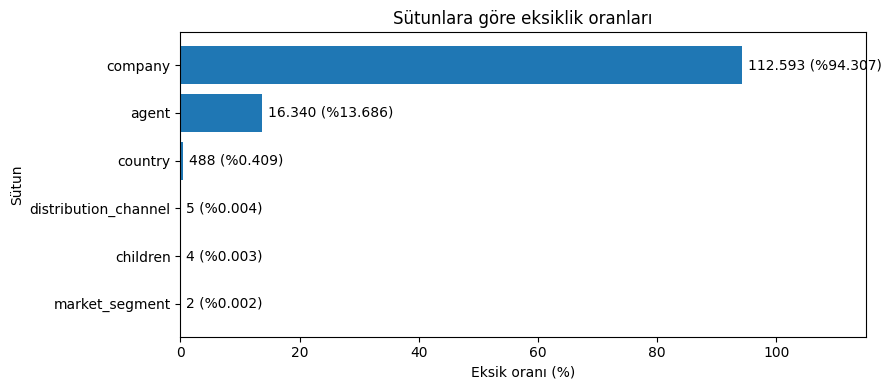

Grafik: Sütunlara göre eksik değer oranları (%); company ve agent için boşluklar çoğunlukla acente/şirket yok anlamına geliyor.

company / agent eksiklik deseni (True = NaN):


agent_eksik,False,True
company_eksik,,
False,217,6580
True,102833,9760



country / children eksiklik deseni:


,kayit_sayisi
Yalnız country eksik,488
Yalnız children eksik,4
İkisi birlikte eksik,0


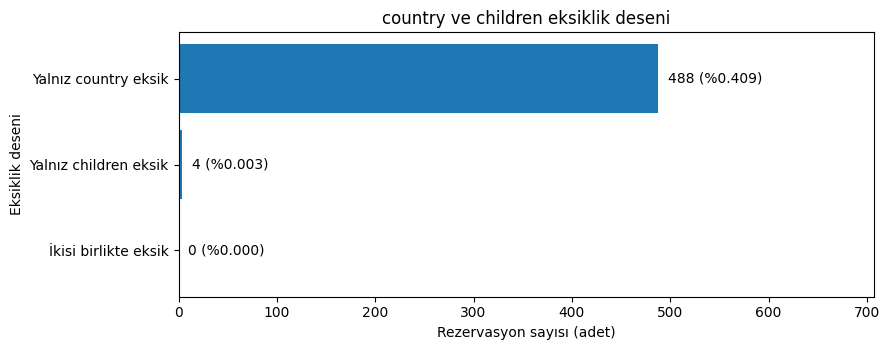

Grafik: country ve children eksiklik desenleri (kayıt sayısı); iki alanın birlikte eksik olduğu kayıt sayısı 0.

--- company: 112593 eksik kayıt ---

company: hotel gruplarına göre eksiklik:


,eksik_sayi,toplam,eksik_orani_yuzde
grup,,,
City Hotel,75641,79330,95.3498
Resort Hotel,36952,40060,92.2416



company: distribution_channel gruplarına göre eksiklik:


,eksik_sayi,toplam,eksik_orani_yuzde
grup,,,
Corporate,1594,6677,23.8730
Direct,13841,14645,94.5101
GDS,192,193,99.4819
TA/TO,96961,97870,99.0712
NaN,5,5,100.0000



company: market_segment gruplarına göre eksiklik:


,eksik_sayi,toplam,eksik_orani_yuzde
grup,,,
Aviation,25,237,10.5485
Complementary,430,743,57.8735
Corporate,824,5295,15.5619
Direct,12398,12606,98.3500
Groups,18420,19811,92.9786
Offline TA/TO,24113,24219,99.5623
Online TA,56381,56477,99.8300
NaN,2,2,100.0000


... (35 outputs left out)

,eksik_sayi
country,488
distribution_channel,5
children,4
market_segment,2


Deney tamamlandı: add_indicator = False
Deney tamamlandı: add_indicator = True

Eksiklik göstergesinin sınıflandırmaya etkisi:


,f1,precision,recall
add_indicator,,,
False,0.6299 ± 0.0039,0.7168 ± 0.0040,0.5619 ± 0.0056
True,0.6300 ± 0.0039,0.7166 ± 0.0039,0.5622 ± 0.0056


Eşli F1 farkı (göstergeli − göstergesiz): +0.00008 ± 0.00041; göstergenin daha iyi olduğu kat: 15/25


In [6]:

ham_metin = pd.read_csv(url, dtype=str, keep_default_na=False)
kod_sayimi = pd.DataFrame({kod: ham_metin.eq(kod).sum() for kod in ["NULL", "NA", "Undefined"]})
print("Ham dosyadaki eksik / belirsiz kodlar:")
display(kod_sayimi.loc[kod_sayimi.sum(axis=1) > 0])

# 1. Eksik değerlerin belirlenmesi ve kodlanmış eksikler

df_eksik = df.copy()

for sutun in ["market_segment", "distribution_channel"]:
    df_eksik[sutun] = df_eksik[sutun].replace("Undefined", np.nan)

# Sıfır misafirli rezervasyonlar olası tutarsızlıktır.
# Hangi alanın hatalı olduğunu bilmediğimiz için hiçbirini NaN yapmıyoruz.

misafir_toplam = df_eksik[["adults", "children", "babies"]].sum(axis=1, min_count=3)
sifir_misafir = misafir_toplam.eq(0)
print("Misafir toplamı sıfır olan kayıt (değiştirilmedi):", int(sifir_misafir.sum()))

# Yapısal eksiklikleri ayırmadan önce bütün NaN sayılarını hesaplıyoruz.

eksik_tablosu = pd.DataFrame({
    "eksik_sayi": df_eksik.isna().sum(),
    "eksik_oran_yuzde": (df_eksik.isna().mean() * 100).round(4)
})
eksik_tablosu = (eksik_tablosu.loc[eksik_tablosu["eksik_sayi"] > 0]
                 .sort_values("eksik_sayi", ascending=False))
print("\nEksik değer tablosu (yapısal eksiklikler henüz ayrılmadı):")
display(eksik_tablosu)

en_cok_iki = eksik_tablosu.index[:2].tolist()  # Beklediğimiz sonuç: company ve agent
inceleme_alanlari = list(dict.fromkeys(en_cok_iki + ["country", "children"]))
print("\nEn çok NaN içeren iki sütun:", en_cok_iki)
print("Ek inceleme sütunları: country, children")
if set(en_cok_iki) != {"company", "agent"}:
    print("Uyarı: En çok NaN içeren sütunlar beklenenden farklı. Veri yükleme ve dönüşümleri kontrol edin.")

# 2. Eksiklik desenlerinin görselleştirilmesi

# 2.1 Sütunlara göre eksik oranı
siralı = eksik_tablosu.sort_values("eksik_oran_yuzde")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(siralı.index, siralı["eksik_oran_yuzde"])
for i, (adet, oran) in enumerate(zip(siralı["eksik_sayi"], siralı["eksik_oran_yuzde"])):
    ax.text(oran + 1, i, f"{adet:,} (%{oran:.3f})".replace(",", "."), va="center")
ax.set_xlim(0, 115)
ax.set_xlabel("Eksik oranı (%)")
ax.set_ylabel("Sütun")
ax.set_title("Sütunlara göre eksiklik oranları")
plt.tight_layout()
plt.show()
print("Grafik: Sütunlara göre eksik değer oranları (%); company ve agent için boşluklar çoğunlukla acente/şirket yok anlamına geliyor.")

# 2.2 company ve agent eksikliklerinin birlikte görülmesi
print("\ncompany / agent eksiklik deseni (True = NaN):")
display(pd.crosstab(
    df_eksik["company"].isna().rename("company_eksik"),
    df_eksik["agent"].isna().rename("agent_eksik")
))

# 2.3 country ve children eksikliklerinin birlikte görülmesi
country_yok = df_eksik["country"].isna()
children_yok = df_eksik["children"].isna()
desen_sayilari = {
    "Yalnız country eksik": int((country_yok & ~children_yok).sum()),
    "Yalnız children eksik": int((~country_yok & children_yok).sum()),
    "İkisi birlikte eksik": int((country_yok & children_yok).sum())
}
print("\ncountry / children eksiklik deseni:")
display(pd.Series(desen_sayilari, name="kayit_sayisi").to_frame())

fig, ax = plt.subplots(figsize=(9, 3.6))
etiketler = list(desen_sayilari.keys())
degerler = list(desen_sayilari.values())
ax.barh(etiketler, degerler)
ax.invert_yaxis()
ust = max(degerler + [1])
for i, adet in enumerate(degerler):
    ax.text(adet + ust * 0.02, i,
            f"{adet} (%{adet / len(df_eksik) * 100:.3f})", va="center")
ax.set_xlim(0, ust * 1.45)
ax.set_xlabel("Rezervasyon sayısı (adet)")
ax.set_ylabel("Eksiklik deseni")
ax.set_title("country ve children eksiklik deseni")
plt.tight_layout()
plt.show()
print(f"Grafik: country ve children eksiklik desenleri (kayıt sayısı); iki alanın birlikte eksik olduğu kayıt sayısı {desen_sayilari['İkisi birlikte eksik']}.")

# 3. MCAR / MAR / MNAR için betimsel karşılaştırma

for eksik_sutun in inceleme_alanlari:
    eksik_gosterge = df_eksik[eksik_sutun].isna()
    print(f"\n--- {eksik_sutun}: {int(eksik_gosterge.sum())} eksik kayıt ---")

    for grup_sutunu in ["hotel", "distribution_channel", "market_segment", "is_canceled"]:
        if grup_sutunu == eksik_sutun:
            continue
        ozet = (pd.DataFrame({"grup": df_eksik[grup_sutunu], "eksik": eksik_gosterge})
                .groupby("grup", dropna=False)["eksik"]
                .agg(eksik_sayi="sum", toplam="size", eksik_orani="mean"))
        ozet["eksik_orani_yuzde"] = (ozet["eksik_orani"] * 100).round(4)
        print(f"\n{eksik_sutun}: {grup_sutunu} gruplarına göre eksiklik:")
        display(ozet[["eksik_sayi", "toplam", "eksik_orani_yuzde"]])

    print(f"\n{eksik_sutun}: eksik/dolu grupların sayısal medyanları:")
    display(df_eksik.groupby(eksik_gosterge.rename("eksik"))[
        ["lead_time", "adr"]
    ].median().round(2))

# 4. Yapısal eksiklikleri anlamlı kategorilere dönüştürme

for sutun, yok_etiketi in {"agent": "Acente_yok", "company": "Sirket_yok"}.items():
    df_eksik[sutun] = df_eksik[sutun].map(
        lambda v: yok_etiketi if pd.isna(v)
        else str(int(v)) if isinstance(v, (int, float, np.integer, np.floating))
        and float(v).is_integer() else str(v)
    )

print("\nYapısal eksiklikler ayrıldıktan sonra kalan NaN sayıları:")
kalan = df_eksik.isna().sum()
display(kalan[kalan > 0].sort_values(ascending=False).to_frame("eksik_sayi"))

# 5. add_indicator'ın etkisi

kategorik_model = ["country", "hotel", "market_segment", "distribution_channel"]
sayisal_model = ["children", "adults", "lead_time", "previous_cancellations"]
X = df_eksik[kategorik_model + sayisal_model].copy()
y = df_eksik["is_canceled"]
cv = cv_olustur()      # defterin ortak düzeni: 5 kat × 5 tekrar

sonuclar, f1_katlar = [], {}
for indicator in [False, True]:
    kategorik_isleme = Pipeline([
        ("doldurma", SimpleImputer(strategy="most_frequent", add_indicator=indicator)),
        ("kodlama", OneHotEncoder(handle_unknown="ignore"))
    ])
    sayisal_isleme = Pipeline([
        ("doldurma", SimpleImputer(strategy="median", add_indicator=indicator)),
        ("olcekleme", StandardScaler())
    ])
    on_isleme = ColumnTransformer([
        ("kategorik", kategorik_isleme, kategorik_model),
        ("sayisal", sayisal_isleme, sayisal_model)
    ])
    model = Pipeline([
        ("on_isleme", on_isleme),
        ("siniflandirici", LogisticRegression(solver="liblinear", max_iter=1000, random_state=SEED))
    ])
    cv_sonuc = cross_validate(model, X, y, cv=cv, n_jobs=1, error_score="raise",
                              scoring={"f1": "f1", "precision": "precision", "recall": "recall"})
    f1_katlar[indicator] = cv_sonuc["test_f1"]
    sonuc = {"add_indicator": indicator}
    for olcut in ["f1", "precision", "recall"]:
        degerler = cv_sonuc[f"test_{olcut}"]
        sonuc[olcut] = f"{degerler.mean():.4f} ± {degerler.std():.4f}"
    sonuclar.append(sonuc)
    print("Deney tamamlandı: add_indicator =", indicator)

print("\nEksiklik göstergesinin sınıflandırmaya etkisi:")
display(pd.DataFrame(sonuclar).set_index("add_indicator"))

# İki kurulum aynı 25 bölmede koştuğu için farkı kat kat (eşli) inceliyoruz.
fark = f1_katlar[True] - f1_katlar[False]
print(f"Eşli F1 farkı (göstergeli − göstergesiz): {fark.mean():+.5f} ± {fark.std():.5f}; "
      f"göstergenin daha iyi olduğu kat: {(fark > 0).sum()}/{len(fark)}")


### 1.3 Eksiklik Analizi: Bulgular ve Yorumlarımız

Önce dosyayı hiçbir dönüşüm yapmadan metin olarak okuyup eksik kodlarını saydık: `company` sütununda **112.593**, `agent` sütununda **16.340** ve `country` sütununda **488** hücrede `NULL`; `children` sütununda **4** hücrede `NA` yazıyor. pandas bu kodları kendiliğinden `NaN` olarak okuyor. Ayrıca `meal` (1.169), `distribution_channel` (5) ve `market_segment` (2) sütunlarında `Undefined` değeri var.

**Hangi boşluk gerçekten eksik?** Kaynak makaleye göre `agent` ve `company` sütunlarındaki `NULL` "uygulanamaz" anlamına geliyor: rezervasyon bir acente ya da şirket üzerinden yapılmamış. Yani bu hücrelerde bilinmeyen bir değer yok; **eksik veri değil, bir kategori.** Bu yüzden bunları `Acente_yok` ve `Sirket_yok` kategorilerine çevirdik. `meal`'daki `Undefined` da makaleye göre "yemek paketi yok" (SC ile aynı) anlamında; eksik saymadık. Anlamı açıklanmayan `market_segment` (2) ve `distribution_channel` (5) `Undefined` değerlerini `NaN` kabul ettik.

**MCAR / MAR / MNAR (en çok boşluğu olan iki sütun: `company` ve `agent`).** Bu iki sütunda boşluk "yok" anlamına geldiği için klasik eksiklik mekanizması sorusu buraya tam uymuyor: ortada kayıp bir değer yok. Yine de boşlukların rastgele dağılıp dağılmadığına baktık. `company` boşluk oranı Corporate kanalında %23,87, TA/TO kanalında %99,07; `agent` boşluk oranı TA/TO'da %3,24, Corporate'ta %83,02. Boşluk gözlenen bir sütuna (dağıtım kanalına) güçlü biçimde bağlı, yani boşluklar **MCAR varsayımıyla uyumlu değil**; bu desen, rezervasyonun nasıl yapıldığını yansıtan yapısal bir durumla tutarlı. Bir istisna dikkat çekiyor: **TA/TO (seyahat acentesi) kanalından gelip acente kodu olmayan 3.167 rezervasyon.** Acente kanalından gelen bir rezervasyonda "acente yok" demek çelişkili; bu kayıtlar **gerçek eksik ya da veri kodlama tutarsızlığı** içerebilir. Hangilerinin gerçek eksik olduğunu ayıramadığımız için ayrı bir kod açmadık ve bunu sınırlılık olarak yazıyoruz.

**Gerçek eksikler: `country` ve `children`.** Yapısal boşlukları ayırınca kalan eksikler `country` (488), `distribution_channel` (5), `children` (4) ve `market_segment` (2). `country` eksiklerinin **464'ü Resort Hotel**, **24'ü City Hotel** kayıtlarında (oranlar %1,16 ve %0,03). Ülkesi eksik olanlarda medyan `lead_time` **4 gün**, dolu olanlarda **69 gün**. Eksiklik gözlenen sütunlarla ilişkili olduğu için MCAR varsayımı güçlü değil; desen MAR ile uyumlu. Ancak yalnızca grup karşılaştırmalarıyla MAR'ı kanıtlayamayız; eksikliğin ülkenin kendisine bağlı olduğu MNAR olasılığını da veriden dışlayamayız. `children` sütununda yalnızca **4 eksik** var: dördü de City Hotel'de, dördü de iptal edilmiş ve dördünde `distribution_channel` da eksik. Bu, ortak bir veri giriş sorununu düşündürüyor; dört gözlemle kesin karar vermedik.

**Eksiklik göstergesi deneyi.** Aynı lojistik regresyonu `SimpleImputer(add_indicator=False)` ve `add_indicator=True` ile, defterin ortak düzeninde (**5 kat × 5 tekrar**, aynı 25 bölme) karşılaştırdık.

| Ölçüt | Gösterge yok | Gösterge var |
|---|---:|---:|
| F1 | 0,6299 ± 0,0039 | 0,6300 ± 0,0039 |
| Precision | 0,7168 ± 0,0040 | 0,7166 ± 0,0039 |
| Recall | 0,5619 ± 0,0056 | 0,5622 ± 0,0056 |

İki kurulum aynı bölmelerde koştuğu için farkı kat kat da inceledik: eşli F1 farkı **+0,00008 ± 0,00041** ve gösterge 25 katın **15'inde** daha iyi. Ortalama fark, katlar arasındaki oynamanın (std 0,00041) çok altında kaldığı için göstergenin bu kurulumda kayda değer bir performans katkısı gösterdiğini söyleyemiyoruz. Bu beklenen bir sonuç: gerçek eksikler verinin yalnızca %0,4'ü kadar, "eksikti" bilgisi çok az kaydı etkileyebilir. Bu sonuç başka modellerde ya da eksik oranı yüksek verilerde aynı çıkacağını göstermez. Doldurmayı kalıcı olarak tabloya yazmadık; yalnızca model hattının içinde, her katta eğitim verisinden öğrenilecek şekilde uyguladık.

### 1.4 Kategorik kodlama
Yüksek kardinaliteli bir sütunda bire-bir, nadir kategorileri birleştiren bire-bir ve kat dışı hedef kodlama; hedef kodlamanın bir kez yanlış uygulanması.

Veri boyutu: (119390, 18)
agent kategori sayısı: 334 | Acente_yok kayıt: 16340
Tek kayıtlı agent kategorisi: 50

agent için nadir kategori eşik analizi:


,esik,nadir_kategori,nadir_kayit,nadir_kayit_yuzde
0,5,95,170,0.14
1,10,121,350,0.29
2,20,152,825,0.69
3,50,215,2846,2.38
4,100,249,5230,4.38


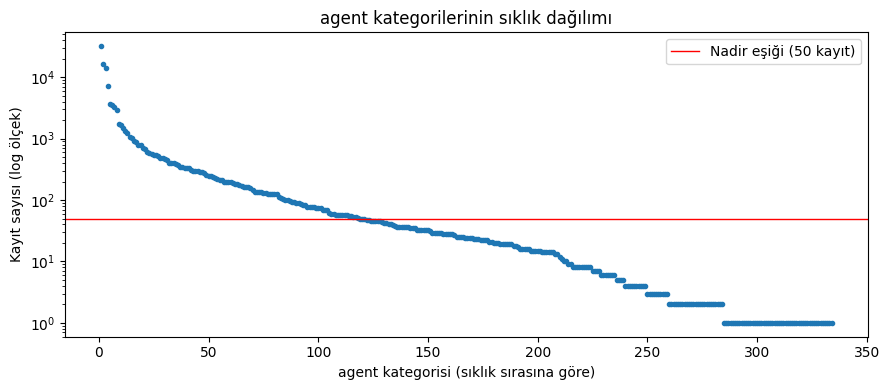

Grafik: agent kategorilerinin sıklık sırasına göre kayıt sayısı (log ölçek); kırmızı çizgi 50 kayıtlık nadir kategori eşiğini gösteriyor.
Tamamlandı: Standart One-Hot
Tamamlandı: Nadir One-Hot (<50)
Tamamlandı: OOF Target Encoding
Tamamlandı: Yanlış Target Encoding

Kodlama yöntemlerinin karşılaştırılması (25 değerlendirme):


,F1 ortalama,F1 std,F1 min,F1 max,agent sütun sayısı (ort.)
Standart One-Hot,0.6275,0.0046,0.6178,0.6369,322.92
Nadir One-Hot (<50),0.6243,0.0045,0.6158,0.6331,106.36
OOF Target Encoding,0.6068,0.0043,0.5991,0.6145,1.00
Yanlış Target Encoding,0.6073,0.0044,0.5990,0.6150,1.00



Eşleştirilmiş F1 farkları (referans: Nadir One-Hot (<50)):


,ort. fark (yöntem − referans),fark std,yöntemin daha iyi olduğu kat
Standart One-Hot,0.003221,0.001441,25/25
OOF Target Encoding,-0.017461,0.002497,0/25
Yanlış Target Encoding,-0.017042,0.002584,0/25



Yanlış − OOF Target Encoding F1 farkı: +0.0004 (yanlışın daha yüksek olduğu kat: 20/25)


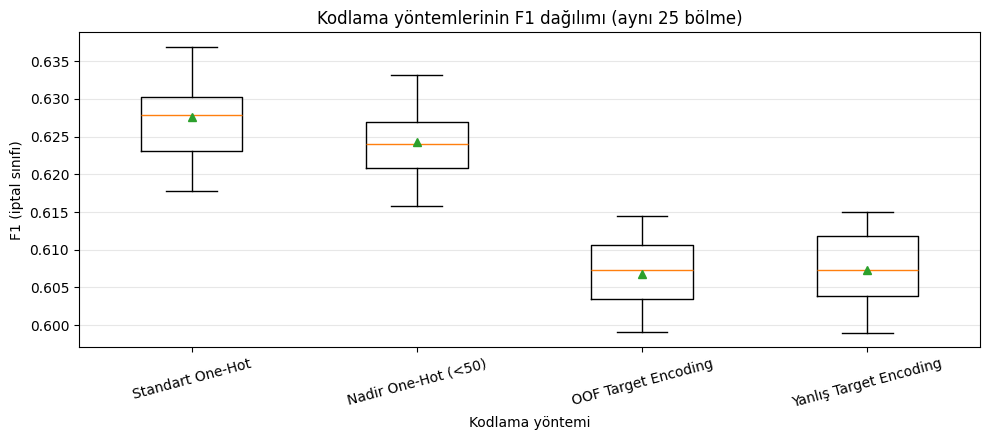

Grafik: Dört kodlama yönteminin aynı 25 bölmedeki F1 dağılımı; üçgen ortalamayı, yatay çizgi medyanı gösteriyor.

En yüksek ortalama F1 (doğru yöntemler): Standart One-Hot → 0.6275 ± 0.0046
agent sütun sayıları: {'Standart One-Hot': 322.92, 'Nadir One-Hot (<50)': 106.36, 'OOF Target Encoding': 1.0}


In [7]:
uyarilari_sustur()   # sürüm uyumsuzluğundan gelen, sonuçları etkilemeyen uyarıları gizle (3. hücre)
# Yüksek kardinaliteli 'agent' için dört kodlamayı karşılaştırıyoruz:
#   1) Standart One-Hot
#   2) Nadir kategorileri birleştiren One-Hot
#   3) Out-of-Fold Target Encoding
#   4) Yanlış Target Encoding (bilerek sızıntılı)

# Değerlendirme:
# 5 kat × 5 tekrar, aynı bölmeler,
# F1 (iptal = 1), lojistik regresyon.


N_SPLITS, N_REPEATS = 5, 5

# ============================================================
# 1. VERİ HAZIRLIĞI
# ============================================================

# Ana tabloları koruyup bir kopyasıyla çalışıyoruz.
df_kodlama = df_eksik.copy()


# meal için Undefined ve SC aynı anlama gelir.
df_kodlama["meal"] = df_kodlama["meal"].replace(
    "Undefined", "SC"
)

# Kodlamasını karşılaştırdığımız sütun
hedef_kategorik = "agent"

# Bütün modellerde aynı kalan kategorik değişkenler
sabit_kategorik = [
    "hotel",
    "market_segment",
    "distribution_channel",
    "customer_type",
    "meal",
    "reserved_room_type",
    "arrival_date_month"
]

# company için bütün modellerde aynı nadir One-Hot'u uyguluyoruz.
sabit_nadir = ["company"]

# Sayısal değişkenler
sayisal = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled"
]

X = df_kodlama[
    [hedef_kategorik]
    + sabit_kategorik
    + sabit_nadir
    + sayisal
].copy()

y = df_kodlama["is_canceled"].astype(int).copy()

# 1.3'teki Undefined -> NaN dönüşümünden kalan kategorik NaN değerlerini 'Eksik' kategorisi olarak koruyoruz.
for sutun in sabit_kategorik + sabit_nadir + [hedef_kategorik]:
    X[sutun] = X[sutun].fillna("Eksik").astype(str)


for sutun in sayisal:
    X[sutun] = pd.to_numeric(
        X[sutun], errors="coerce"
    )

assert y.notna().all() and set(y.unique()).issubset({0, 1}), (
    "is_canceled yalnızca 0 ve 1 içermelidir."
)

print("Veri boyutu:", X.shape)

print(
    "agent kategori sayısı:", X["agent"].nunique(),
    "| Acente_yok kayıt:",
    int(X["agent"].eq("Acente_yok").sum())
)


# ============================================================
# 2. YÜKSEK KARDİNALİTE VE NADİR KATEGORİ ANALİZİ
# ============================================================

agent_frekans = X["agent"].value_counts()

# Tek kayıtlı agent kategorisi sayısı
print("Tek kayıtlı agent kategorisi:", int((agent_frekans == 1).sum()))

# Farklı nadir kategori eşiklerini inceliyoruz.
esik_analizi = pd.DataFrame([
    {
        "esik": e,
        "nadir_kategori": int(
            (agent_frekans < e).sum()
        ),
        "nadir_kayit": int(
            agent_frekans[agent_frekans < e].sum()
        ),
        "nadir_kayit_yuzde": round(
            agent_frekans[agent_frekans < e].sum()
            / len(X) * 100,
            2
        )
    }
    for e in [5, 10, 20, 50, 100]
])

print("\nagent için nadir kategori eşik analizi:")
display(esik_analizi)

# Agent kategorilerinin sıklık dağılımı
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    range(1, len(agent_frekans) + 1),
    agent_frekans.values,
    marker=".",
    linestyle="none"
)

ax.axhline(
    50,
    color="red",
    linewidth=1,
    label="Nadir eşiği (50 kayıt)"
)

ax.set_yscale("log")
ax.set_xlabel("agent kategorisi (sıklık sırasına göre)")
ax.set_ylabel("Kayıt sayısı (log ölçek)")
ax.set_title("agent kategorilerinin sıklık dağılımı")
ax.legend()

plt.tight_layout()
plt.show()
print("Grafik: agent kategorilerinin sıklık sırasına göre kayıt sayısı (log ölçek); kırmızı çizgi 50 kayıtlık nadir kategori eşiğini gösteriyor.")


# ============================================================
# 3. ORTAK ÖN İŞLEME VE MODEL
# ============================================================

# Modeller arasında yalnızca agent kodlayıcısını değiştiriyoruz;
# diğer ön işleme adımlarını bütün modellerde aynı tutuyoruz.

def model_olustur(agent_kodlayici, agent_sutunu="agent"):

    on_isleme = ColumnTransformer([
        (
            "agent",
            agent_kodlayici,
            [agent_sutunu]
        ),
        (
            "kategorik",
            OneHotEncoder(handle_unknown="ignore"),
            sabit_kategorik
        ),
        (
            "company",
            OneHotEncoder(
                min_frequency=50,
                handle_unknown="infrequent_if_exist"
            ),
            sabit_nadir
        ),
        (
            "sayisal",
            Pipeline([
                (
                    "doldurma",
                    SimpleImputer(strategy="median")
                ),
                (
                    "olcekleme",
                    StandardScaler()
                )
            ]),
            sayisal
        )
    ])

    return Pipeline([
        (
            "on_isleme",
            on_isleme
        ),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                random_state=SEED
            )
        )
    ])


# Üç doğru kodlama yöntemi
modeller = {

    # 1. Standart One-Hot Encoding
    "Standart One-Hot": model_olustur(
        OneHotEncoder(
            handle_unknown="ignore"
        )
    ),

    # 2. Nadir kategorileri birleştiren One-Hot
    # min_frequency yalnızca eğitim katında hesaplanır.
    "Nadir One-Hot (<50)": model_olustur(
        OneHotEncoder(
            min_frequency=50,
            handle_unknown="infrequent_if_exist"
        )
    ),

    # 3. Out-of-Fold Target Encoding

    "OOF Target Encoding": model_olustur(
        TargetEncoder(
            target_type="binary",
            smooth="auto",
            cv=5,
            shuffle=True,
            random_state=SEED
        )
    )
}


# ============================================================
# 4. ÇAPRAZ DOĞRULAMA
# ============================================================

cv = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=SEED
)

# Üç doğru yöntemi ve sızıntılı deneyi aynı 25 bölmede değerlendiriyoruz.
bolmeler = list(cv.split(X, y))


def degerlendir(model, X_girdi):

    skorlar = []
    sutun_sayilari = []

    for egitim, test in bolmeler:

        # Her bölmede modeli sıfırdan eğitiyoruz.
        m = clone(model).fit(
            X_girdi.iloc[egitim],
            y.iloc[egitim]
        )

        tahmin = m.predict(X_girdi.iloc[test])

        skorlar.append(
            f1_score(
                y.iloc[test],
                tahmin,
                pos_label=1
            )
        )

        # agent kodlaması sonrası oluşan sütun sayısı
        agent_adimi = (
            m.named_steps["on_isleme"]
            .named_transformers_["agent"]
        )

        if hasattr(agent_adimi, "get_feature_names_out"):
            sutun_sayisi = len(
                agent_adimi.get_feature_names_out()
            )
        else:
            # Yanlış hedef kodlama deneyinde
            # agent zaten tek sayısal sütundur.
            sutun_sayisi = 1

        sutun_sayilari.append(sutun_sayisi)

    return (
        np.array(skorlar),
        np.array(sutun_sayilari)
    )


# Üç doğru yöntemi değerlendiriyoruz.
tum_skorlar = {}
sutun_ozeti = {}

for ad, model in modeller.items():

    tum_skorlar[ad], sutun_ozeti[ad] = degerlendir(
        model, X
    )

    print("Tamamlandı:", ad)


# ============================================================
# 5. YANLIŞ TARGET ENCODING — VERİ SIZINTISI
# ============================================================

# TargetEncoder'ı bilerek bütün veri üzerinde eğitiyoruz.
# Böylece test katlarının hedef bilgisi de agent kategorilerinin ortalamasına sızıyor.


yanlis_kodlayici = TargetEncoder(
    target_type="binary",
    smooth="auto",
    random_state=SEED
)

# Bilerek yanlış: bütün verinin hedefini kullanıyoruz.

yanlis_kodlayici.fit(
    X[["agent"]],
    y
)

# agent kodlamasını çapraz doğrulamadan önce yapıyoruz.
X_yanlis = X.drop(columns="agent").assign(
    agent_te=yanlis_kodlayici.transform(
        X[["agent"]]
    ).ravel()
)

# Yanlış yöntemi de aynı 25 bölmede değerlendiriyoruz.
tum_skorlar["Yanlış Target Encoding"], sutun_ozeti[
    "Yanlış Target Encoding"
] = degerlendir(
    model_olustur(
        "passthrough",
        agent_sutunu="agent_te"
    ),
    X_yanlis
)

print("Tamamlandı: Yanlış Target Encoding")


# ============================================================
# 6. DÖRT YÖNTEMİN KARŞILAŞTIRILMASI
# ============================================================


sonuc_tablosu = pd.DataFrame({
    ad: {
        "F1 ortalama": s.mean(),
        "F1 std": s.std(),
        "F1 min": s.min(),
        "F1 max": s.max(),
        "agent sütun sayısı (ort.)": (
            sutun_ozeti[ad].mean()
        )
    }
    for ad, s in tum_skorlar.items()
}).T

print(
    "\nKodlama yöntemlerinin karşılaştırılması "
    "(25 değerlendirme):"
)

display(sonuc_tablosu.round(4))


# ============================================================
# 7. EŞLEŞTİRİLMİŞ F1 FARKLARI
# ============================================================

referans = "Nadir One-Hot (<50)"

eslesmis = pd.DataFrame({
    ad: {
        "ort. fark (yöntem − referans)": (
            s - tum_skorlar[referans]
        ).mean(),

        "fark std": (
            s - tum_skorlar[referans]
        ).std(),

        "yöntemin daha iyi olduğu kat": (
            f"{int((s > tum_skorlar[referans]).sum())}"
            f"/{len(s)}"
        )
    }
    for ad, s in tum_skorlar.items()
    if ad != referans
}).T

print(
    f"\nEşleştirilmiş F1 farkları "
    f"(referans: {referans}):"
)

display(eslesmis)


# ============================================================
# 8. VERİ SIZINTISI FARKI
# ============================================================

sizinti_farki = (
    tum_skorlar["Yanlış Target Encoding"]
    - tum_skorlar["OOF Target Encoding"]
)

print(
    "\nYanlış − OOF Target Encoding F1 farkı: "
    f"{sizinti_farki.mean():+.4f} "
    "(yanlışın daha yüksek olduğu kat: "
    f"{int((sizinti_farki > 0).sum())}"
    f"/{len(sizinti_farki)})"
)


# ============================================================
# 9. F1 SKORLARININ GÖRSEL KARŞILAŞTIRMASI
# ============================================================

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.boxplot(
    list(tum_skorlar.values()),
    showmeans=True
)

ax.set_xticks(
    range(1, len(tum_skorlar) + 1),
    list(tum_skorlar.keys()),
    rotation=15
)

ax.set_xlabel("Kodlama yöntemi")
ax.set_ylabel("F1 (iptal sınıfı)")
ax.set_title(
    "Kodlama yöntemlerinin F1 dağılımı "
    "(aynı 25 bölme)"
)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
print("Grafik: Dört kodlama yönteminin aynı 25 bölmedeki F1 dağılımı; üçgen ortalamayı, yatay çizgi medyanı gösteriyor.")


# ============================================================
# 10. EN İYİ DOĞRU YÖNTEMİN BELİRLENMESİ
# ============================================================


dogru = sonuc_tablosu.drop(
    index="Yanlış Target Encoding"
)

en_iyi = dogru["F1 ortalama"].idxmax()

print(
    "\nEn yüksek ortalama F1 (doğru yöntemler):",
    en_iyi,
    f"→ {dogru.loc[en_iyi, 'F1 ortalama']:.4f} "
    f"± {dogru.loc[en_iyi, 'F1 std']:.4f}"
)

print(
    "agent sütun sayıları:",
    dogru[
        "agent sütun sayısı (ort.)"
    ].round(2).to_dict()
)

# Yöntem seçimini karşılaştırma tablosundaki sonuçlara göre yaptık.

### 1.4 Kategorik Kodlama: Bulgular ve Yorumlarımız

Kodlama yöntemlerini karşılaştırmak için çok sayıda farklı değeri olan `agent` sütununu seçtik. `Acente_yok` dahil **334 kategori** var; bunların **50'si yalnızca birer kayıtta** görülüyor. 50'den az kaydı olan 215 kategori bütün kayıtların yalnızca %2,38'ini oluşturuyor.

Üç doğru yöntemi aynı **18 başlangıç özniteliği**, aynı lojistik regresyon ve aynı **5 kat × 5 tekrar** bölmeleriyle karşılaştırdık; yalnızca `agent`'ın kodlaması değişiyor. Hedef kodlamayı `Pipeline` içinde uyguladık. Sızıntının etkisini görmek için hedef kodlamayı bir kez de bilerek bütün veride yaptık.

| Yöntem | F1 (ortalama ± std) | `agent` kaynaklı sütun sayısı |
|---|---:|---:|
| Standart One-Hot | **0,6275 ± 0,0046** | 322,92 |
| Nadir One-Hot (eşik 50) | 0,6243 ± 0,0045 | 106,36 |
| Kat dışı (OOF) Target Encoding | 0,6068 ± 0,0043 | 1 |
| Yanlış, bütün-veri Target Encoding | 0,6073 ± 0,0044 | 1 |

En yüksek ortalama F1'i **standart One-Hot** verdi. Nadir kategorileri birleştirmek sütun sayısını yaklaşık üçte bire indirdi; F1 ise yaklaşık **0,0032** düştü. Aynı katlarda eşli karşılaştırmada standart yöntem 25 katın 25'inde daha yüksekti. Bu yüzden 1.6'daki ilk modelde standart One-Hot'u kullandık. Bölüm 2'de ise k-NN ve gradyan artırma gibi yoğun tablo isteyen modeller olduğu için daha küçük öznitelik uzayı veren nadir One-Hot'u seçtik; bedeli küçük (yaklaşık 0,003 F1).

OOF Target Encoding iki One-Hot yönteminin gerisinde kaldı (25 katın hiçbirinde nadir One-Hot'u geçmedi). Her acenteyi tek bir sayıyla (iptal oranıyla) temsil etmek bilgi kaybettiriyor olabilir: lojistik regresyon logit ölçeğinde doğrusal çalışır, iptal oranı ise olasılık ölçeğindedir; %60 ile %95 arasındaki fark logit ölçeğinde çok daha büyüktür.

**Yanlış hedef kodlama** sklearn'de `TargetEncoder.fit_transform`, eğitim verisini kodlarken cross-fitting yapar; `fit` ardından `transform` ise yapmaz ve her satırı kendi hedefini de içeren ortalamayla kodlar. Yanlış kurulumda kodlayıcıyı bütün veride bu ikinci yolla kullandık. F1 doğru OOF kurulumundan yalnızca **0,0004** yüksek çıktı (25 katın 20'sinde yüksek). Farkın küçük kalmasının olası nedenlerinden biri, kayıtların çoğunun büyük acentelerde olmasıdır: binlerce kaydı olan bir acentenin oranını tek bir kaydın etiketi pek değiştirmez. Nadir kategorilerde kendi hedef değerinin kodlamaya katkısı daha yüksek olabilir; `smooth="auto"` uygulanan yumuşatma bu etkiyi sınırlayabilir. Ancak deneyimiz bu açıklamayı tek neden olarak doğrulamıyor. Fark küçük olsa da test bilgisi kodlamaya karıştığı için bu yöntemi geçerli kabul etmedik.

### 1.5 Sızıntı deneyi
Ön işlemenin bütün veride yapıldığı kurulum (yanlış) ile `Pipeline` içinde yapıldığı kurulum (doğru); hata çubuklarıyla.

Veri boyutu: (119390, 6)
Acente_yok kayıt sayısı: 16340
Kullanılan sütunlar: ['agent', 'hotel', 'distribution_channel', 'lead_time', 'adults', 'previous_cancellations']
Not: Bu kontrollü 6 sütunlu deneyin F1 sonucu 1.4'teki 18 sütunlu modelle doğrudan karşılaştırılmaz.
Çapraz doğrulama değerlendirmesi: 25

Doğru Pipeline değerlendiriliyor...
Yanlış bütün-veri kurulumu değerlendiriliyor...

1.5 Sızıntı deneyi - F1 sonuçları:


,Kurulum,F1 Ortalama,F1 Std,F1 Ortalama ± Std
0,Doğru - Pipeline içinde,0.467606,0.005615,0.4676 ± 0.0056
1,Yanlış - bütün veride,0.466400,0.005279,0.4664 ± 0.0053


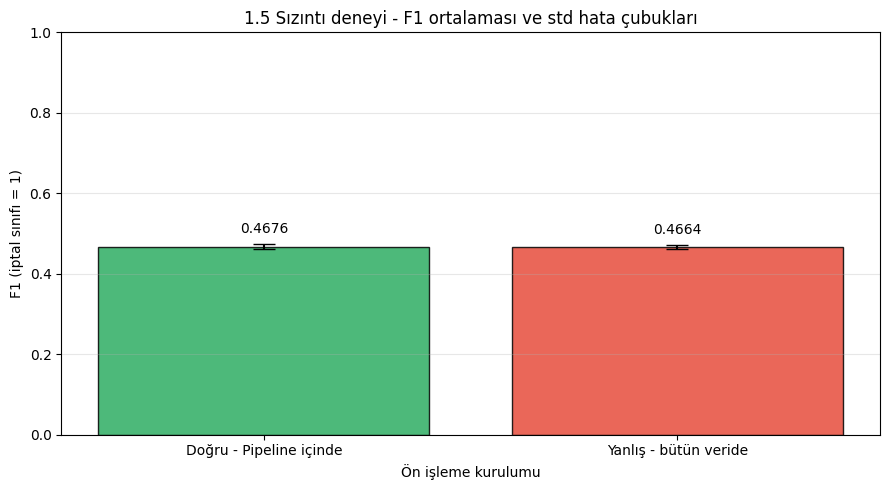

Grafik: Doğru ve yanlış ön işleme kurulumlarının 25 bölmedeki ortalama F1 değerleri; hata çubukları standart sapmayı gösteriyor.

Doğru F1: 0.467606
Yanlış F1: 0.466400
Yanlış - doğru ortalama fark: -0.001206
Farkların std değeri: 0.001464
Yanlışın daha yüksek olduğu bölme: 5/25

Bütün veri ile eğitim katında seçilen ortak öznitelik sayısı (/20): [19, 19, 20, 19, 19]
Bütün veride seçilen öznitelikler: ['kategorik__agent_1', 'kategorik__agent_14', 'kategorik__agent_19', 'kategorik__agent_236', 'kategorik__agent_241', 'kategorik__agent_250', 'kategorik__agent_28', 'kategorik__agent_29', 'kategorik__agent_40', 'kategorik__agent_58', 'kategorik__agent_7', 'kategorik__agent_Acente_yok', 'kategorik__distribution_channel_Corporate', 'kategorik__distribution_channel_Direct', 'kategorik__distribution_channel_TA/TO', 'kategorik__hotel_City Hotel', 'kategorik__hotel_Resort Hotel', 'sayisal__adults', 'sayisal__lead_time', 'sayisal__previous_cancellations']


In [8]:
uyarilari_sustur()   # sürüm uyumsuzluğundan gelen, sonuçları etkilemeyen uyarıları gizle (3. hücre)
# Yanlış kurulum: ön işleme ve öznitelik seçimini ÇD'den önce bütün veride yapıyoruz.
# Doğru kurulum: ön işleme ve öznitelik seçimini ÇD'nin içinde (Pipeline) yapıyoruz.
# İkisinde de aynı veriyi, modeli, 25 bölmeyi ve seçilecek 20 özniteliği kullanıyoruz.
# Ölçüt: F1 (iptal = 1), ortalama ± standart sapma.


K_15 = 20

# 1. Veri hazırlığı
# df_eksik tablosunu değiştirmiyoruz; agent için 1.3'teki Acente_yok kategorisini koruyoruz.
df_sizinti = df_eksik.copy()

kategorik_15 = ["agent", "hotel", "distribution_channel"]
sayisal_15 = ["lead_time", "adults", "previous_cancellations"]

X_15 = df_sizinti[kategorik_15 + sayisal_15].copy()
y_15 = df_sizinti["is_canceled"].astype(int).copy()

# agent bir kimlik kodu; onu sayısal değil, nominal değişken olarak ele alıyoruz.
# Burada yalnızca sabit bir tür dönüşümü yapıyoruz; veriden hiçbir parametre öğrenmiyoruz.

X_15["agent"] = X_15["agent"].map(
    lambda v: "Acente_yok" if pd.isna(v) else str(v)
)

for sutun in ["hotel", "distribution_channel"]:
    X_15[sutun] = X_15[sutun].astype("object")

for sutun in sayisal_15:
    X_15[sutun] = pd.to_numeric(X_15[sutun], errors="coerce")

assert y_15.notna().all() and set(y_15.unique()).issubset({0, 1}), (
    "is_canceled yalnızca 0 ve 1 içermeli."
)

print("Veri boyutu:", X_15.shape)
print("Acente_yok kayıt sayısı:", int(X_15["agent"].eq("Acente_yok").sum()))
print("Kullanılan sütunlar:", kategorik_15 + sayisal_15)
print("Not: Bu kontrollü 6 sütunlu deneyin F1 sonucu 1.4'teki 18 sütunlu modelle doğrudan karşılaştırılmaz.")

# 2. Aynı çapraz doğrulama bölmeleri
cv_15 = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=SEED
)
bolmeler_15 = list(cv_15.split(X_15, y_15))
print("Çapraz doğrulama değerlendirmesi:", len(bolmeler_15))

# 3. İki deneyde de aynı ön işleme tanımını kullanıyoruz.
# Kategorik doldurma, One-Hot, sayısal doldurma ve ölçeklemeyi doğru kurulumda yalnızca eğitim katından öğreniyoruz.
def on_isleme_hazirla_15():
    return ColumnTransformer([
        (
            "kategorik",
            Pipeline([
                ("doldurma", SimpleImputer(
                    strategy="constant", fill_value="Eksik"
                )),
                ("kodlama", OneHotEncoder(handle_unknown="ignore"))
            ]),
            kategorik_15
        ),
        (
            "sayisal",
            Pipeline([
                ("doldurma", SimpleImputer(strategy="median")),
                ("olcekleme", StandardScaler())
            ]),
            sayisal_15
        )
    ])


def lojistik_model_15():
    return LogisticRegression(
        solver="lbfgs",
        max_iter=2000,
        random_state=SEED
    )

# 4. Doğru kurulum: öğrenilen bütün adımları Pipeline içinde tutuyoruz.

dogru_hat_15 = Pipeline([
    ("on_isleme", on_isleme_hazirla_15()),
    ("ozellik_secimi", SelectKBest(score_func=f_classif, k=K_15)),
    ("model", lojistik_model_15())
])

print("\nDoğru Pipeline değerlendiriliyor...")
dogru_skorlar_15 = cross_val_score(
    dogru_hat_15, X_15, y_15,
    cv=bolmeler_15,
    scoring="f1",
    n_jobs=1,
    error_score="raise"
)

# 5. Yanlış kurulum: ön işlemeyi ve hedefe bakan öznitelik seçimini bütün veriyle yapıyor, ÇD'yi sonra uyguluyoruz.
# Bu kurulumu yalnızca sızıntı farkını görmek için kullanıyoruz.

print("Yanlış bütün-veri kurulumu değerlendiriliyor...")
yanlis_on_isleme_15 = on_isleme_hazirla_15()
X_yanlis_islenmis_15 = yanlis_on_isleme_15.fit_transform(X_15, y_15)

yanlis_secici_15 = SelectKBest(score_func=f_classif, k=K_15)
X_yanlis_secili_15 = yanlis_secici_15.fit_transform(
    X_yanlis_islenmis_15, y_15
)

yanlis_skorlar_15 = cross_val_score(
    lojistik_model_15(), X_yanlis_secili_15, y_15,
    cv=bolmeler_15,
    scoring="f1",
    n_jobs=1,
    error_score="raise"
)

# 6. Sonuç tablosu
sizinti_sonuclari_15 = pd.DataFrame({
    "Kurulum": ["Doğru - Pipeline içinde", "Yanlış - bütün veride"],
    "F1 Ortalama": [dogru_skorlar_15.mean(), yanlis_skorlar_15.mean()],
    "F1 Std": [dogru_skorlar_15.std(), yanlis_skorlar_15.std()]
})
sizinti_sonuclari_15["F1 Ortalama ± Std"] = [
    f"{ort:.4f} ± {std:.4f}"
    for ort, std in zip(sizinti_sonuclari_15["F1 Ortalama"],
                        sizinti_sonuclari_15["F1 Std"])
]
print("\n1.5 Sızıntı deneyi - F1 sonuçları:")
display(sizinti_sonuclari_15)

# 7. Hata çubuklu grafik
fig, ax = plt.subplots(figsize=(9, 5))
x_eksen_15 = np.arange(len(sizinti_sonuclari_15))

ax.bar(
    x_eksen_15,
    sizinti_sonuclari_15["F1 Ortalama"],
    yerr=sizinti_sonuclari_15["F1 Std"],
    capsize=8,
    color=["#2EAD63", "#E74C3C"],
    edgecolor="black",
    alpha=0.85
)

ax.set_xticks(x_eksen_15)
ax.set_xticklabels(["Doğru - Pipeline içinde", "Yanlış - bütün veride"])
ax.set_ylabel("F1 (iptal sınıfı = 1)")
ax.set_xlabel("Ön işleme kurulumu")
ax.set_title("1.5 Sızıntı deneyi - F1 ortalaması ve std hata çubukları")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

for i, ort in enumerate(sizinti_sonuclari_15["F1 Ortalama"]):
    ax.text(i, ort + sizinti_sonuclari_15.loc[i, "F1 Std"] + 0.02,
            f"{ort:.4f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()
print("Grafik: Doğru ve yanlış ön işleme kurulumlarının 25 bölmedeki ortalama F1 değerleri; hata çubukları standart sapmayı gösteriyor.")

# 8. Aynı katlardaki eşli farklar
farklar_15 = yanlis_skorlar_15 - dogru_skorlar_15
print("\nDoğru F1:", f"{dogru_skorlar_15.mean():.6f}")
print("Yanlış F1:", f"{yanlis_skorlar_15.mean():.6f}")
print("Yanlış - doğru ortalama fark:", f"{farklar_15.mean():+.6f}")
print("Farkların std değeri:", f"{farklar_15.std():.6f}")
print("Yanlışın daha yüksek olduğu bölme:",
      f"{int((farklar_15 > 0).sum())}/{len(farklar_15)}")


# 9. Farkın neden küçük kaldığını anlamak için seçilen öznitelikleri karşılaştırıyoruz.

secilen_tum_15 = set(
    yanlis_on_isleme_15.get_feature_names_out()[yanlis_secici_15.get_support()]
)

ortak_sayilar_15 = []
for egitim, _ in bolmeler_15[:5]:
    hat = clone(dogru_hat_15).fit(X_15.iloc[egitim], y_15.iloc[egitim])
    adlar = hat.named_steps["on_isleme"].get_feature_names_out()
    secilen_kat = set(adlar[hat.named_steps["ozellik_secimi"].get_support()])
    ortak_sayilar_15.append(len(secilen_tum_15 & secilen_kat))

print(f"\nBütün veri ile eğitim katında seçilen ortak öznitelik sayısı (/{K_15}):", ortak_sayilar_15)
print("Bütün veride seçilen öznitelikler:", sorted(secilen_tum_15))

### 1.5 Sızıntı Deneyi: Bulgular ve Yorumlarımız

Aynı modeli iki şekilde kurduk: **doğru yöntemde** eksik doldurma, kodlama, ölçekleme ve öznitelik seçimi `Pipeline` içinde, yani her katta yalnız eğitim verisinden öğrenildi; **bilerek yanlış yöntemde** aynı adımları çapraz doğrulamadan önce bütün veride yaptık. Bu adımlardan hedefe bakan tek adım `SelectKBest(f_classif)`; ötekiler hedefe bakmaz ama test katlarının dağılım bilgisini taşır.

Bu deneyde 1.4'ten ayrı olarak **6 başlangıç özniteliği** kullandık ve kodlamadan sonra **20 öznitelik** seçtik; aynı lojistik regresyon ve **5 kat × 5 tekrar = 25** değerlendirme.

| Kurulum | F1 (ortalama ± std) |
|---|---:|
| Doğru – `Pipeline` içinde | **0,4676 ± 0,0056** |
| Yanlış – bütün veri üzerinde | 0,4664 ± 0,0053 |

Beklediğimizin aksine yanlış yöntem daha yüksek F1 vermedi; fark yaklaşık **−0,0012** ve yanlış yöntem 25 değerlendirmenin yalnızca 5'inde önde. Nedenini görmek için bütün veride seçilen 20 öznitelikle ilk beş eğitim katında seçilenleri karşılaştırdık: ortak sayılar **19, 19, 20, 19 ve 19**, yani yaklaşık **%96 örtüşme**. Bu deneyde seçilen özniteliklerin büyük ölçüde örtüştüğünü görüyoruz. Kayıt sayısının (119.390) kullanılan öznitelik sayısından çok daha fazla olması ve seçimin kararlı görünmesi, küçük F1 farkının olası açıklamaları arasında. Bununla birlikte, yalnızca bu karşılaştırmadan sızıntının neden küçük kaldığını kesin olarak belirleyemiyoruz.

**Sonuç:** Yanlış yöntemin F1'inin düşük çıkması yöntemi doğru yapmaz. Test bölümünün bilgisi seçime karıştığı için bu skor güvenilir bir genelleme tahmini değildir; veri küçüldüğünde veya öznitelik sayısı arttığında aynı hata daha büyük bir iyimserliğe yol açabilir. Bu yüzden sonraki bütün deneylerde öğrenilen her adımı `Pipeline` içinde tuttuk. Grafikteki hata çubukları kat sonuçlarının standart sapmasıdır; güven aralığı değildir.

### 1.6 Baseline ve ilk model
`DummyClassifier` ve tek bir basit model, sızıntısız hat içinde.

1.6 BASELINE VE İLK MODEL
Veri boyutu: (119390, 18)
Hedef sınıf dağılımı:


,Kayıt sayısı
is_canceled,
0,75166
1,44224


Dummy (hep 0) değerlendiriliyor...
Dummy (hep 1) değerlendiriliyor...
LogisticRegression değerlendiriliyor...

25 DEĞERLENDİRME - MODEL KARŞILAŞTIRMA TABLOSU (ortalama ± std)


,F1,Accuracy,Precision,Recall
Dummy (hep 0),0.0000 ± 0.0000,0.6296 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000
Dummy (hep 1),0.5406 ± 0.0000,0.3704 ± 0.0000,0.3704 ± 0.0000,1.0000 ± 0.0000
LogisticRegression,0.6275 ± 0.0046,0.7694 ± 0.0021,0.7811 ± 0.0044,0.5245 ± 0.0060


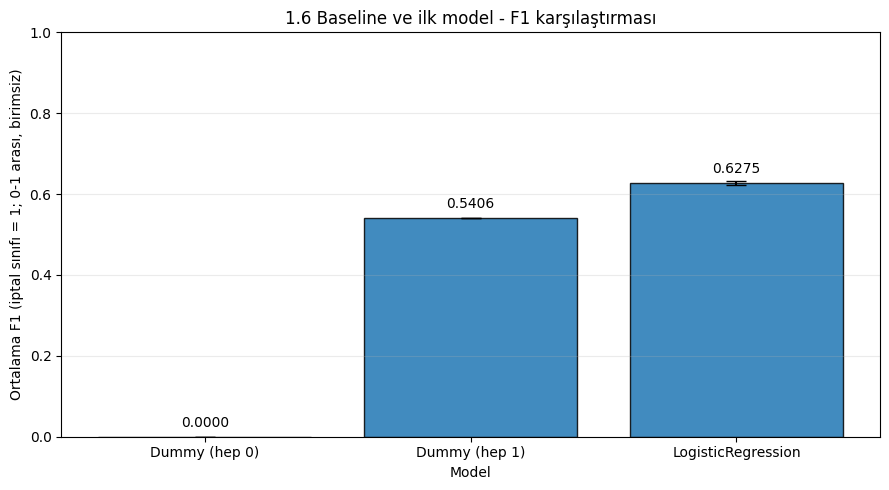

F1 farkı (Lojistik - Dummy (hep 0)): +0.6275 (lojistiğin daha iyi olduğu bölme: 25/25)
F1 farkı (Lojistik - Dummy (hep 1)): +0.0869 (lojistiğin daha iyi olduğu bölme: 25/25)
Grafik: Üç modelin aynı 25 bölmedeki ortalama F1 değeri; hata çubukları standart sapmayı gösteriyor.

Tekilleştirilmiş veri: 87,396 kayıt, iptal oranı %27.49
  F1       : tüm veri 0.6275 ± 0.0046 | tekil veri 0.3592 ± 0.0064
  Accuracy : tüm veri 0.7694 ± 0.0021 | tekil veri 0.7532 ± 0.0022
  Precision: tüm veri 0.7811 ± 0.0044 | tekil veri 0.6274 ± 0.0110
  Recall   : tüm veri 0.5245 ± 0.0060 | tekil veri 0.2517 ± 0.0055


In [9]:
uyarilari_sustur()   # sürüm uyumsuzluğundan gelen, sonuçları etkilemeyen uyarıları gizle (3. hücre)
# Hedef: is_canceled (1 = iptal veya no-show, 0 = iptal değil)
# 5 kat × 5 tekrar = 25 değerlendirme
# Raporladığımız sonuçlar: F1, Accuracy, Precision, Recall ve tek bir F1 grafiği


# 1.4 ve 1.2'de belirlediğimiz 18 sütunu kullandık.
# İlk modelimiz, önceki bölümlerde aldığımız bütün kararları içeriyor.
kategorik_sutunlar = ["agent", "hotel", "market_segment", "distribution_channel",
                      "customer_type", "meal", "reserved_room_type", "arrival_date_month"]
nadir_kategorik_sutunlar = ["company"]
sayisal_sutunlar = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
                    "adults", "children", "babies", "is_repeated_guest",
                    "previous_cancellations", "previous_bookings_not_canceled"]
kullanilan_sutunlar = kategorik_sutunlar + nadir_kategorik_sutunlar + sayisal_sutunlar

# 1. Veri hazırlığı: df_eksik tablosunun kopyasıyla çalışıyoruz.
girdi_verileri = df_eksik[kullanilan_sutunlar].copy()
hedef_iptal = df_eksik["is_canceled"].astype(int).copy()

girdi_verileri["meal"] = girdi_verileri["meal"].replace("Undefined", "SC")


for sutun_adi, yok_etiketi in {"agent": "Acente_yok", "company": "Sirket_yok"}.items():
    girdi_verileri[sutun_adi] = girdi_verileri[sutun_adi].map(
        lambda v: yok_etiketi if pd.isna(v)
        else str(int(v)) if isinstance(v, (int, float, np.integer, np.floating))
        else str(v)
    )

# Diğer kategorik sütunlarda NaN'ı koruyoruz (Pipeline'da "Eksik" ile dolduruluyor);
# bütün dolu değerlerin metin olduğunu kontrol ediyoruz.
for sutun_adi in kategorik_sutunlar + nadir_kategorik_sutunlar:
    tipler = girdi_verileri[sutun_adi].dropna().map(type).unique()
    assert all(t is str for t in tipler), f"{sutun_adi} sütununda metin dışı değer var: {tipler}"

for sutun_adi in sayisal_sutunlar:
    girdi_verileri[sutun_adi] = pd.to_numeric(girdi_verileri[sutun_adi], errors="coerce")

assert set(hedef_iptal.unique()).issubset({0, 1}), "Hedef yalnızca 0 ve 1 olmalı."
print("1.6 BASELINE VE İLK MODEL")
print("Veri boyutu:", girdi_verileri.shape)
print("Hedef sınıf dağılımı:")
display(hedef_iptal.value_counts().sort_index().to_frame("Kayıt sayısı"))

# 2. Lojistik regresyonun ön işlemesini her eğitim katında yeniden öğreniyoruz.

on_isleme = ColumnTransformer([
    ("kategorik", Pipeline([
        ("eksik_doldurma", SimpleImputer(strategy="constant", fill_value="Eksik")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore"))
    ]), kategorik_sutunlar),
    ("company", Pipeline([
        ("eksik_doldurma", SimpleImputer(strategy="constant", fill_value="Eksik")),
        ("one_hot", OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist"))
    ]), nadir_kategorik_sutunlar),
    ("sayisal", Pipeline([
        ("eksik_doldurma", SimpleImputer(strategy="median")),
        ("olcekleme", StandardScaler())
    ]), sayisal_sutunlar)
])

# 3. Modeller

modeller = {
    "Dummy (hep 0)": DummyClassifier(strategy="constant", constant=0),
    "Dummy (hep 1)": DummyClassifier(strategy="constant", constant=1),
    "LogisticRegression": Pipeline([
        ("on_isleme", on_isleme),
        ("model", LogisticRegression(max_iter=2000, solver="lbfgs",
                                     random_state=SEED))
    ])
}

# 4. Üç model için aynı 25 eğitim/test bölmesi
capraz_dogrulama = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=5, random_state=SEED
)
capraz_dogrulama_bolmeleri = list(capraz_dogrulama.split(girdi_verileri, hedef_iptal))

degerlendirme_olcutleri = {
    "F1": make_scorer(f1_score, zero_division=0),
    "Accuracy": "accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": "recall"
}

# 5. Model değerlendirme ve sonuç tablosu
tum_skorlar = {}
for model_adi, model in modeller.items():
    print(f"{model_adi} değerlendiriliyor...")
    tum_skorlar[model_adi] = cross_validate(
        estimator=model, X=girdi_verileri, y=hedef_iptal,
        cv=capraz_dogrulama_bolmeleri, scoring=degerlendirme_olcutleri,
        n_jobs=1, error_score="raise"
    )

model_karsilastirma_tablosu = pd.DataFrame({
    model_adi: {f"{olcut} {istatistik}": getattr(np, fonksiyon)(skor[f"test_{olcut}"])
                for olcut in degerlendirme_olcutleri
                for istatistik, fonksiyon in [("Ortalama", "mean"), ("Std", "std")]}
    for model_adi, skor in tum_skorlar.items()
}).T

gosterilecek_tablo = pd.DataFrame({
    olcut: [f"{o:.4f} ± {s:.4f}" for o, s in zip(model_karsilastirma_tablosu[f"{olcut} Ortalama"],
                                                 model_karsilastirma_tablosu[f"{olcut} Std"])]
    for olcut in degerlendirme_olcutleri
}, index=model_karsilastirma_tablosu.index)

print("\n25 DEĞERLENDİRME - MODEL KARŞILAŞTIRMA TABLOSU (ortalama ± std)")
display(gosterilecek_tablo)

# 6. Tek grafik: F1 ortalaması ve standart sapması
grafik_figuru, eksen = plt.subplots(figsize=(9, 5))
eksen.bar(
    model_karsilastirma_tablosu.index,
    model_karsilastirma_tablosu["F1 Ortalama"],
    yerr=model_karsilastirma_tablosu["F1 Std"],
    capsize=7, edgecolor="black", alpha=0.85
)
eksen.set_title("1.6 Baseline ve ilk model - F1 karşılaştırması")
eksen.set_xlabel("Model")
eksen.set_ylabel("Ortalama F1 (iptal sınıfı = 1; 0-1 arası, birimsiz)")
eksen.set_ylim(0, 1)
eksen.grid(axis="y", alpha=0.25)
for konum, ortalama in enumerate(model_karsilastirma_tablosu["F1 Ortalama"]):
    eksen.text(konum, ortalama + 0.025, f"{ortalama:.4f}", ha="center")
plt.tight_layout()
plt.show()

# 7. Baseline'lara göre farklar
lojistik_f1 = tum_skorlar["LogisticRegression"]["test_F1"]
for baseline_adi in ["Dummy (hep 0)", "Dummy (hep 1)"]:
    fark = lojistik_f1 - tum_skorlar[baseline_adi]["test_F1"]
    print(f"F1 farkı (Lojistik - {baseline_adi}): {fark.mean():+.4f} "
          f"(lojistiğin daha iyi olduğu bölme: {int((fark > 0).sum())}/{len(fark)})")
print("Grafik: Üç modelin aynı 25 bölmedeki ortalama F1 değeri; hata çubukları standart sapmayı gösteriyor.")

# 8. Kontrol: tam kopya satırlar (1.2) skoru iyimser gösteriyor mu?
tekil = (~df.duplicated()).to_numpy()
tekil_skor = cross_validate(modeller["LogisticRegression"], girdi_verileri[tekil], hedef_iptal[tekil],
                            cv=cv_olustur(), scoring=degerlendirme_olcutleri, n_jobs=1)
print(f"\nTekilleştirilmiş veri: {tekil.sum():,} kayıt, iptal oranı %{100 * hedef_iptal[tekil].mean():.2f}")
for olcut in ["F1", "Accuracy", "Precision", "Recall"]:
    tum, tek = tum_skorlar["LogisticRegression"][f"test_{olcut}"], tekil_skor[f"test_{olcut}"]
    print(f"  {olcut:<9}: tüm veri {tum.mean():.4f} ± {tum.std():.4f} | tekil veri {tek.mean():.4f} ± {tek.std():.4f}")


### 1.6 Baseline ve İlk Model: Bulgular ve Yorumlarımız

1.4'te belirlediğimiz **18 başlangıç özniteliğini** kullandık. İki `DummyClassifier` ve bir `LogisticRegression` modelini **5 kat × 5 tekrar** ile aynı 25 bölmede değerlendirdik. Kodlama, eksik doldurma ve ölçekleme lojistik regresyonun `Pipeline`'ı içinde.

| Model | F1 | Accuracy | Precision | Recall |
|---|---:|---:|---:|---:|
| Dummy (hep 0) | 0,0000 ± 0,0000 | 0,6296 ± 0,0000 | 0,0000 ± 0,0000 | 0,0000 ± 0,0000 |
| Dummy (hep 1) | 0,5406 ± 0,0000 | 0,3704 ± 0,0000 | 0,3704 ± 0,0000 | 1,0000 ± 0,0000 |
| Lojistik regresyon | **0,6275 ± 0,0046** | 0,7694 ± 0,0021 | 0,7811 ± 0,0044 | 0,5245 ± 0,0060 |

Hep "iptal değil" diyen baseline **%62,96 accuracy** aldı ama hiçbir iptali yakalayamadığı için **F1 = 0**. Hep "iptal" diyen baseline ise bütün iptalleri yakaladığı için **0,5406 F1** aldı. Böylece accuracy ve F1 için hangi basit tahminin referans olduğunu ayrı ayrı gördük.

Lojistik regresyon iki baseline'ı da F1'de geçti (hep 1'e göre fark **+0,0869**, 25 bölmenin 25'inde). "İptal" dediği rezervasyonların yaklaşık **%78'inde** haklı (precision), gerçek iptallerin ise ancak yaklaşık **%52'sini** yakalıyor (recall). Bu değerler varsayılan 0,5 karar eşiğine ait. Modelin F1'i 1.4'teki standart One-Hot sonucuyla birebir aynı; iki bölümün kurulumu tutarlı.

**Kopya satır kontrolü:** 1.2'de bulduğumuz kopyaların sonucu ne kadar etkilediğini görmek için 32 sütunun hepsi aynı olan satırları çıkardık ve aynı modeli aynı düzende yeniden değerlendirdik. Geriye **87.396** kayıt kaldı ve iptal oranı **%37,04'ten %27,49'a** düştü; yani çıkardığımız 31.994 satırın yaklaşık %63'ü iptal sınıfındaydı. Bu veride F1 **0,3592 ± 0,0064**, recall **0,2517 ± 0,0055** çıktı; accuracy ise 0,7694 ± 0,0021'den yalnızca 0,7532 ± 0,0022'ye indi.

Bu düşüşün iki kaynağını bu karşılaştırmayla birbirinden ayıramıyoruz. Birincisi, tüm girdileri aynı olan kayıtlar eğitim ve test katlarına birlikte düştüğünde model testteki girdilerle aynı bir örneği eğitimde görmüş olabilir; bu da skoru iyimser gösteriyor. İkincisi, tekilleştirme problemin kendisini değiştiriyor: aynı görünen satırlar gerçek tekrarlar olabileceği gibi aynı özelliklere sahip farklı rezervasyonlar da olabilir ve bunlar çıkınca iptal sınıfı %37'den %27,5'e küçülüyor. Bu yüzden F1'in yarıya inmesini tek başına sızıntının büyüklüğü olarak okumuyoruz; ne tekilleştirilmiş verideki ne de asıl verideki F1'i gerçek kullanım performansı olarak kabul ediyoruz. Ana sonuçların, benzer kayıtların eğitim ve testte birlikte bulunmasından etkilenebileceğini bir sınırlılık olarak raporluyoruz. Aynı kontrolü 2.1'de en iyi iki model için de yaptık.

### 1.7 Weka ile bağımsız kontrol
ZeroR ve J48, 10 kat çapraz doğrulama; çıktıyı yapıştırın ve Python ile tutarlılığını yorumlayın.

In [10]:

# Burada yapmak istediğimiz 1.6'da kullanılan 18 özniteliği Weka'ya aktarmak.
# Weka'daki sonuçları Python sonuçlarıyla karşılaştırmak.

# ------------------------------------------------------------
# 1. VERİ HAZIRLIĞI
# ------------------------------------------------------------

kategorik_sutunlar = [
    "agent",
    "hotel",
    "market_segment",
    "distribution_channel",
    "customer_type",
    "meal",
    "reserved_room_type",
    "arrival_date_month"
]

nadir_kategorik_sutunlar = ["company"]

sayisal_sutunlar = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "is_repeated_guest",
    "previous_cancellations",
    "previous_bookings_not_canceled"
]

kullanilan_sutunlar = (
    kategorik_sutunlar
    + nadir_kategorik_sutunlar
    + sayisal_sutunlar
)

# df_eksik tablosunun bir kopyasıyla çalışıyoruz.
weka_verileri = df_eksik[
    kullanilan_sutunlar + ["is_canceled"]
].copy()

# 1.4 ve 1.6 ile aynı yemek paketi kararı.
weka_verileri["meal"] = weka_verileri["meal"].replace(
    "Undefined", "SC"
)

# Acente ve şirket kimliklerini kategorik metin olarak tutuyoruz.
for sutun_adi, yok_etiketi in {
    "agent": "Acente_yok",
    "company": "Sirket_yok"
}.items():

    weka_verileri[sutun_adi] = weka_verileri[sutun_adi].map(
        lambda deger: (
            yok_etiketi if pd.isna(deger)
            else str(int(deger))
            if isinstance(
                deger,
                (int, float, np.integer, np.floating)
            )
            else str(deger)
        )
    )

# Sayısal alanları sayıya çeviriyoruz; eksikleri doldurmuyoruz (J48 eksikleri kendisi işliyor).
for sutun_adi in sayisal_sutunlar:
    weka_verileri[sutun_adi] = pd.to_numeric(
        weka_verileri[sutun_adi],
        errors="coerce"
    )

# Hedef değişkenin yalnızca 0/1 olduğunu kontrol ediyoruz.
assert weka_verileri["is_canceled"].notna().all()
assert set(
    weka_verileri["is_canceled"].unique()
).issubset({0, 1})

# ------------------------------------------------------------
# 2. ARFF DOSYASINI OLUŞTURMA
# ------------------------------------------------------------

def arff_degeri(deger):
    """Kategorik değerleri ARFF biçimine dönüştürür."""
    if pd.isna(deger):
        return "?"

    metin = str(deger)
    metin = metin.replace("\\", "\\\\")
    metin = metin.replace("'", "\\'")

    return "'" + metin + "'"


dosya_adi = "HotelBooking_Weka.arff"

with open(dosya_adi, "w", encoding="utf-8") as dosya:

    dosya.write("@relation HotelBooking_Weka\n\n")

    # Sütun tipleri
    for sutun_adi in weka_verileri.columns:

        if sutun_adi == "is_canceled":
            dosya.write(
                "@attribute is_canceled {'0','1'}\n"
            )

        elif sutun_adi in sayisal_sutunlar:
            dosya.write(
                f"@attribute {sutun_adi} numeric\n"
            )

        else:
            kategoriler = sorted(
                weka_verileri[sutun_adi]
                .dropna()
                .astype(str)
                .unique()
            )

            kategori_metni = ",".join(
                arff_degeri(deger)
                for deger in kategoriler
            )

            dosya.write(
                f"@attribute {sutun_adi} "
                f"{{{kategori_metni}}}\n"
            )

    dosya.write("\n@data\n")

    # Veri satırları
    for kayit in weka_verileri.itertuples(
        index=False, name=None
    ):

        satir = []

        for sutun_adi, deger in zip(
            weka_verileri.columns, kayit
        ):

            if pd.isna(deger):
                satir.append("?")

            elif sutun_adi in sayisal_sutunlar:
                satir.append(str(float(deger)))

            else:
                satir.append(arff_degeri(deger))

        dosya.write(",".join(satir) + "\n")

# ------------------------------------------------------------
# 3. KONTROL VE DOSYAYI İNDİRME
# ------------------------------------------------------------

print("WEKA VERİ HAZIRLAMA TAMAMLANDI")
print("Veri boyutu:", weka_verileri.shape)
print("Öznitelik sayısı:", len(kullanilan_sutunlar))
print("Hedef değişken:", "is_canceled")
print("Oluşturulan dosya:", dosya_adi)

print("\nHedef sınıf dağılımı:")
display(
    weka_verileri["is_canceled"]
    .value_counts()
    .sort_index()
    .to_frame("Kayıt Sayısı")
)

print("\nEksik değer sayıları:")
display(
    weka_verileri
    .isna()
    .sum()
    .loc[lambda tablo: tablo > 0]
    .to_frame("Eksik Sayısı")
)

# ARFF dosyasını sıkıştırıyoruz (yaklaşık 15 MB → 0,6 MB). Otomatik indirme (files.download) tarayıcı izin
# vermezse hücreyi sonsuza kadar bekletebildiği için kullanmıyoruz; zip'i Dosyalar bölümünden indiriyoruz.
import zipfile
zip_adi = "HotelBooking_Weka.zip"
with zipfile.ZipFile(zip_adi, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(dosya_adi)
print(f"{dosya_adi}: {os.path.getsize(dosya_adi) / 1e6:.1f} MB → {zip_adi}: {os.path.getsize(zip_adi) / 1e6:.1f} MB")
print(f"Weka dosyası hazır: sol paneldeki Dosyalar bölümünden {zip_adi} dosyasını indirip açın.")

WEKA VERİ HAZIRLAMA TAMAMLANDI
Veri boyutu: (119390, 19)
Öznitelik sayısı: 18
Hedef değişken: is_canceled
Oluşturulan dosya: HotelBooking_Weka.arff

Hedef sınıf dağılımı:


,Kayıt Sayısı
is_canceled,
0,75166
1,44224



Eksik değer sayıları:


,Eksik Sayısı
market_segment,2
distribution_channel,5
children,4


HotelBooking_Weka.arff: 14.9 MB → HotelBooking_Weka.zip: 0.6 MB
Weka dosyası hazır: sol paneldeki Dosyalar bölümünden HotelBooking_Weka.zip dosyasını indirip açın.


#### ZeroR – Weka çıktısı

```text
=== Run information ===

Scheme:       weka.classifiers.rules.ZeroR
Relation:     HotelBooking_Weka
Instances:    119390
Attributes:   19
              agent
              hotel
              market_segment
              distribution_channel
              customer_type
              meal
              reserved_room_type
              arrival_date_month
              company
              lead_time
              stays_in_weekend_nights
              stays_in_week_nights
              adults
              children
              babies
              is_repeated_guest
              previous_cancellations
              previous_bookings_not_canceled
              is_canceled
Test mode:    10-fold cross-validation

=== Classifier model (full training set) ===

ZeroR predicts class value: 0

Time taken to build model: 0.03 seconds

=== Stratified cross-validation ===
=== Summary ===

Correctly Classified Instances       75166               62.9584 %
Incorrectly Classified Instances     44224               37.0416 %
Kappa statistic                          0     
Mean absolute error                      0.4664
Root mean squared error                  0.4829
Relative absolute error                100      %
Root relative squared error            100      %
Total Number of Instances           119390     

=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 1.000    1.000    0.630      1.000    0.773      ?        0.500     0.630     0
                 0.000    0.000    ?          0.000    ?          ?        0.500     0.370     1
Weighted Avg.    0.630    0.630    ?          0.630    ?          ?        0.500     0.534     

=== Confusion Matrix ===

     a     b   <-- classified as
 75166     0 |     a = 0
 44224     0 |     b = 1

```

#### J48 – Weka çıktısı

```text
=== Run information ===

Scheme:       weka.classifiers.trees.J48 -C 0.25 -M 2
Relation:     HotelBooking_Weka
Instances:    119390
Attributes:   19
              agent
              hotel
              market_segment
              distribution_channel
              customer_type
              meal
              reserved_room_type
              arrival_date_month
              company
              lead_time
              stays_in_weekend_nights
              stays_in_week_nights
              adults
              children
              babies
              is_repeated_guest
              previous_cancellations
              previous_bookings_not_canceled
              is_canceled
Test mode:    10-fold cross-validation
Number of Leaves  : 	8428

Size of the tree : 	10327


Time taken to build model: 19.78 seconds

=== Stratified cross-validation ===
=== Summary ===

Correctly Classified Instances       95782               80.2261 %
Incorrectly Classified Instances     23608               19.7739 %
Kappa statistic                          0.5581
Mean absolute error                      0.257
Root mean squared error                  0.3762
Relative absolute error                 55.1016 %
Root relative squared error             77.9097 %
Total Number of Instances           119390     

=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 0.901    0.365    0.807      0.901    0.852      0.566    0.847     0.868     0
                 0.635    0.099    0.790      0.635    0.704      0.566    0.847     0.794     1
Weighted Avg.    0.802    0.267    0.801      0.802    0.797      0.566    0.847     0.840     

=== Confusion Matrix ===

     a     b   <-- classified as
 67714  7452 |     a = 0
 16156 28068 |     b = 1



```

In [11]:

cv_10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
cart = Pipeline([("on_isleme", on_isleme),
                 ("model", DecisionTreeClassifier(min_samples_leaf=2, random_state=SEED))])
cart_skor = cross_validate(cart, girdi_verileri, hedef_iptal, cv=cv_10,
                           scoring=degerlendirme_olcutleri, n_jobs=-1)

# Weka değerlerini yukarıdaki çıktılardan (iptal sınıfı = 1 satırı) aldık.
weka = {"Weka ZeroR": {"Accuracy": 0.6296, "Precision": np.nan, "Recall": 0.000, "F1": np.nan},
        "Weka J48":   {"Accuracy": 0.8023, "Precision": 0.790, "Recall": 0.635, "F1": 0.704}}
karsilastirma = pd.DataFrame(weka).T
karsilastirma.loc["Python Dummy (hep 0), 5x5"] = [tum_skorlar["Dummy (hep 0)"][f"test_{o}"].mean()
                                                  for o in ["Accuracy", "Precision", "Recall", "F1"]]
karsilastirma.loc["Python CART, 10 kat"] = [cart_skor[f"test_{o}"].mean()
                                            for o in ["Accuracy", "Precision", "Recall", "F1"]]
display(karsilastirma.round(4))
print(f"CART 10 kat: doğruluk {cart_skor['test_Accuracy'].mean():.4f} ± {cart_skor['test_Accuracy'].std():.4f}, "
      f"F1 {cart_skor['test_F1'].mean():.4f} ± {cart_skor['test_F1'].std():.4f}")
for o in ["Precision", "Recall"]:
    print(f"CART 10 kat {o}: {cart_skor['test_' + o].mean():.4f} ± {cart_skor['test_' + o].std():.4f}")

,Accuracy,Precision,Recall,F1
Weka ZeroR,0.6296,NaN,0.000,NaN
Weka J48,0.8023,0.7900,0.635,0.7040
"Python Dummy (hep 0), 5x5",0.6296,0.0000,0.000,0.0000
"Python CART, 10 kat",0.7991,0.7587,0.671,0.7121


CART 10 kat: doğruluk 0.7991 ± 0.0041, F1 0.7121 ± 0.0072
CART 10 kat Precision: 0.7587 ± 0.0061
CART 10 kat Recall: 0.6710 ± 0.0114


In [12]:
# Weka'nın raporladığı karışıklık matrisinden ölçütleri yeniden hesaplıyoruz.
# Bu kontrol modeli yeniden eğitmez; yalnızca yukarıya yapıştırdığımız Weka çıktısının aritmetiğini denetler.

# Satırlar: gerçek 0 / gerçek 1; sütunlar: tahmin 0 / tahmin 1.
weka_j48_cm = np.array([[67714, 7452], [16156, 28068]])
weka_zeror_cm = np.array([[75166, 0], [44224, 0]])

def weka_cm_kontrol(cm):
    tn, fp, fn, tp = cm.ravel()
    n = cm.sum()
    accuracy = (tn + tp) / n
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if np.isfinite(precision) and precision + recall else np.nan
    return {"Kayıt": int(n), "Accuracy": accuracy, "Precision (1)": precision, "Recall (1)": recall, "F1 (1)": f1}

weka_dogrulama = pd.DataFrame({
    "ZeroR": weka_cm_kontrol(weka_zeror_cm),
    "J48": weka_cm_kontrol(weka_j48_cm),
}).T
weka_dogrulama["Kayıt"] = weka_dogrulama["Kayıt"].astype(int)
display(weka_dogrulama.round(4))
assert (weka_dogrulama["Kayıt"] == 119390).all(), "Weka kayıt sayısı beklenenden farklı."
assert abs(weka_dogrulama.loc["J48", "Accuracy"] - 0.8023) < 0.0001
assert abs(weka_dogrulama.loc["J48", "F1 (1)"] - 0.704) < 0.001
print("Weka confusion matrix aritmetik kontrolleri başarılı.")


,Kayıt,Accuracy,Precision (1),Recall (1),F1 (1)
ZeroR,119390,0.6296,NaN,0.0000,NaN
J48,119390,0.8023,0.7902,0.6347,0.704


Weka confusion matrix aritmetik kontrolleri başarılı.


### 1.7 Weka ile Bağımsız Kontrol: Bulgular ve Yorumlarımız

1.6'daki 18 girdiyi ve `is_canceled` hedefini ARFF dosyasına aktardık; dosya Weka'da **19 attribute** (18 girdi + hedef) olarak görünüyor. Weka Explorer'da ZeroR ve J48'i **10 katlı çapraz doğrulama** ile çalıştırdık. J48 ile aynı aileden bir modelle karşılaştırmak için Python'da da aynı 18 girdiyle **sklearn karar ağacı (CART)** kurduk ve 10 katlı katmanlı ÇD ile değerlendirdik.

| Model | Ortam | Accuracy | Precision (iptal) | Recall (iptal) | F1 (iptal) |
|---|---|---:|---:|---:|---:|
| ZeroR | Weka, 10 kat | 0,6296 | `?` | 0 | `?` |
| Dummy (hep 0) | Python, 5×5 | 0,6296 ± 0,0000 | 0,0000 ± 0,0000 | 0,0000 ± 0,0000 | 0,0000 ± 0,0000 |
| J48 (`-C 0.25 -M 2`) | Weka, 10 kat | 0,8023 | 0,790 | 0,635 | 0,704 |
| CART (`min_samples_leaf=2`) | Python, 10 kat | 0,7991 ± 0,0041 | 0,7587 ± 0,0061 | 0,6710 ± 0,0114 | 0,7121 ± 0,0072 |

Weka 10 katın sonuçlarını tek bir karışıklık matrisinde topladığı için Weka satırları tek sayı; Python satırları 10 katın ortalaması ± standart sapması.

**Karşılaştırmanın sınırları:** J48 (C4.5) ile CART aynı karar ağacı algoritması değil. Ayrıca Weka ve Python için katmanlı 10 katlı çapraz doğrulama kullansak da örneklerin aynı katlara dağıtıldığını doğrulamadık. Weka'da eksik değerlerin işlenmesi ile Python `Pipeline` içindeki doldurma işlemi de farklı. Bu yüzden sayıları birebir eş koşullu deney sonucu olarak değil, iki ortamda yapılan bağımsız bir tutarlılık kontrolü olarak karşılaştırıyoruz.

**ZeroR kontrolü:** Weka'da ZeroR her kaydı `0` olarak tahmin etti; 75.166 ve 44.224 kayıt sayıları 1.2'deki hedef dağılımıyla aynı. ARFF dışa aktarımında kayıt sayısının korunduğunu gördük ve ZeroR, Python'daki "hep 0" baseline'ıyla aynı doğruluğu veriyor. Weka iptal sınıfının precision ve F1 değerini `?` gösteriyor, çünkü hiç `1` tahmini yapılmadığı için precision tanımsız; Python'da `zero_division=0` ile 0 yazılıyor.

**J48 ve CART:** İki ağacın doğruluğu çok yakın (0,8023 ve 0,7991); Weka sonucu ile Python ortalaması arasındaki doğruluk farkı 0,0032; ancak farklı algoritmalar ve kat bölmeleri nedeniyle bunu istatistiksel eşdeğerlik kanıtı olarak görmüyoruz. F1'de CART biraz yüksek (0,712'ye karşı 0,704), recall'da CART önde, precision'da J48 önde. Birebir eşleşme beklemiyorduk: J48 (C4.5) `agent` gibi nominal sütunlarda tek düğümde çok yollu bölme yapar ve budar; CART ikili bölme yapar ve kategorileri One-Hot sütunları olarak görür. Eksik değerleri de farklı ele alıyorlar (Weka'da `?`, Python'da hat içinde doldurma). J48 çıktısında **8.428 yaprak** yer alıyor. Bu kadar karmaşık bir ağacın tekrar eden örüntülerden yararlanması mümkün; ancak bu çıktıyla kopyaları ezberlediğini kanıtlayamıyoruz (1.6).

İki ortamda da karar ağaçlarının F1 sonuçlarının, çoğunluk tahmininden ve 1.6'daki lojistik regresyonun (F1 0,6275) sonucundan yüksek olduğunu görüyoruz. Bu bulgu doğrusal olmayan örüntüleri modellemenin yararlı olabileceğini düşündürüyor; ancak farkların yalnızca ilişki biçiminden kaynaklandığını iddia etmiyoruz; Bölüm 2'de ağaç tabanlı modelleri bu yüzden ayrıca karşılaştırdık.

**Ek doğrulama kontrolümüz:** Yukarıdaki ek kodda Weka confusion matrix değerlerinden accuracy, precision, recall ve F1 değerlerini yeniden hesaplayarak rapordaki sayıları aritmetik olarak sınadık. Bu kontrol Weka modelini yeniden eğitmez ve farklı veri bölmelerini eşitlemez.


# Bölüm 2 · Sınıflandırma ve dürüst model değerlendirme *(ağırlık 30)*
**Makale:** Dietterich (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7).

**Okuma notu (3–4 cümle):**
Dietterich, sınıflandırma algoritmalarını karşılaştıran beş testi incelemiş ve bazı yaygın testlerin (örneğin üst üste binen katlarda eşli t-testi) gerçekte fark yokken fazla sık "anlamlı" sonuç verdiğini göstermiş. Modeller yalnızca bir kez eğitilebiliyorsa aynı test kayıtlarındaki doğru/yanlış tahmin çiftlerine dayanan **McNemar** testini öneriyor. Eğitim verisinin değişmesinden gelen oynaklığı da hesaba katmak için, modeller on kez eğitilebiliyorsa **5×2 çapraz doğrulama t-testini** öneriyor.

### 2.1 Model karşılaştırması
Baseline, karar ağacı, k-NN, rastgele orman, gradyan artırma; tekrarlı katmanlı ÇD; ortalama ± std tablosu ve kutu grafiği; ölçüt seçiminin gerekçesi.

Baseline (hep 0)  tamamlandı (39 sn)
Karar ağacı       tamamlandı (79 sn)
k-NN              tamamlandı (1687 sn)
Rastgele orman    tamamlandı (512 sn)
Gradyan artırma   tamamlandı (320 sn)


,F1,Precision,Recall,ROC-AUC,Eğitim süresi (sn)
Rastgele orman,0.7166 ± 0.0043,0.8208 ± 0.0051,0.6358 ± 0.0066,0.8890 ± 0.0020,37.8
k-NN,0.6780 ± 0.0043,0.7523 ± 0.0046,0.6171 ± 0.0060,0.8483 ± 0.0025,2.5
Gradyan artırma,0.6710 ± 0.0054,0.8078 ± 0.0063,0.5739 ± 0.0084,0.8645 ± 0.0024,21.2
Karar ağacı,0.6158 ± 0.0444,0.7588 ± 0.0813,0.5325 ± 0.0800,0.8206 ± 0.0041,5.6
Baseline (hep 0),0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,2.5


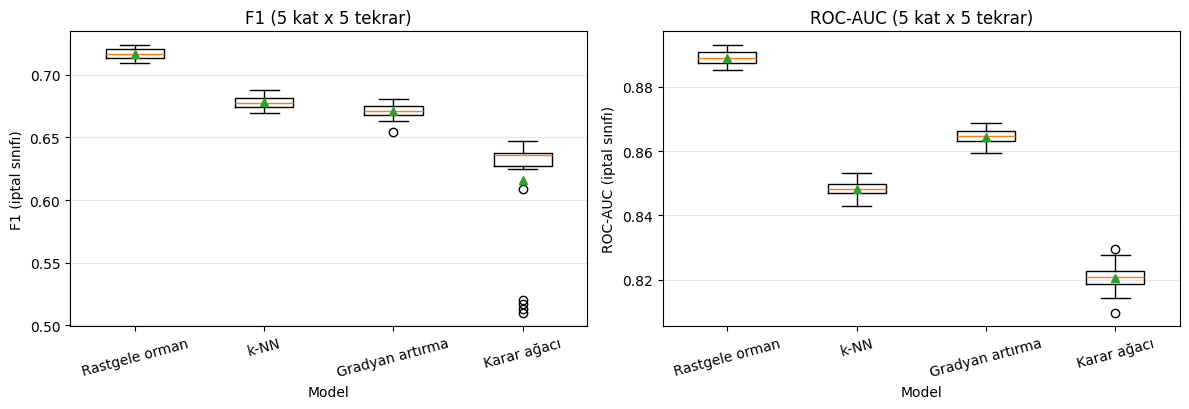

Grafik: Modellerin aynı 25 bölmedeki F1 (sol) ve ROC-AUC (sağ) dağılımı; üçgen ortalama, çizgi medyan.


In [13]:
#Girdi ve hedef: 1.6'daki 18 sütun (meal'da Undefined -> SC birleştirilmiş hâli).
X2, y2 = girdi_verileri.copy(), hedef_iptal.copy()
kategorik_2 = kategorik_sutunlar + nadir_kategorik_sutunlar      # 9 kategorik sütun
sayisal_2 = sayisal_sutunlar                                      # 9 sayısal sütun


def on_isleme_2():
    return ColumnTransformer([
        ("kategorik", Pipeline([
            ("doldur", SimpleImputer(strategy="constant", fill_value="Eksik")),
            ("kodla", OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist",
                                    sparse_output=False))]), kategorik_2),
        ("sayisal", Pipeline([
            ("doldur", SimpleImputer(strategy="median")),
            ("olcekle", StandardScaler())]), sayisal_2),   # k-NN için şart; ağaçları etkilemez
    ])

#Modelleri ve ayarlarını karşılaştırmadan önce sabitledik; ayar aramasını 2.3'te yapıyoruz.
modeller_2 = {
    "Baseline (hep 0)": DummyClassifier(strategy="most_frequent"),
    "Karar ağacı":      DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, random_state=SEED),
    "k-NN":             KNeighborsClassifier(n_neighbors=15),
    "Rastgele orman":   RandomForestClassifier(n_estimators=100, min_samples_leaf=2, random_state=SEED),
    "Gradyan artırma":  HistGradientBoostingClassifier(random_state=SEED),
}
hatlar_2 = {ad: Pipeline([("on_isleme", on_isleme_2()), ("model", m)]) for ad, m in modeller_2.items()}

#Ölçütler: iptal sınıfı F1 (ana ölçüt), precision, recall ve eşikten bağımsız ROC-AUC.
olcutler_2 = {"F1": make_scorer(f1_score, zero_division=0),
              "Precision": make_scorer(precision_score, zero_division=0),
              "Recall": "recall", "ROC-AUC": "roc_auc"}
bolmeler_2 = list(cv_olustur().split(X2, y2))                    # bütün modeller aynı 25 bölmede

skorlar_2 = {}
for ad, hat in hatlar_2.items():
    baslangic = time.time()
    skorlar_2[ad] = cross_validate(hat, X2, y2, cv=bolmeler_2, scoring=olcutler_2, n_jobs=-1)
    print(f"{ad:<17} tamamlandı ({time.time() - baslangic:.0f} sn)")

#Tablo: her ölçüt için 25 skorun ortalaması ± standart sapması, F1'e göre sıralı.
tablo_2 = pd.DataFrame({
    ad: {o: f"{s['test_' + o].mean():.4f} ± {s['test_' + o].std():.4f}" for o in olcutler_2}
    for ad, s in skorlar_2.items()}).T
tablo_2["Eğitim süresi (sn)"] = [round(s["fit_time"].mean(), 1) for s in skorlar_2.values()]
sira_2 = sorted(skorlar_2, key=lambda ad: skorlar_2[ad]["test_F1"].mean(), reverse=True)
display(tablo_2.loc[sira_2])

#Kutu grafiği: her kutu bir modelin 25 skoru
adlar = [ad for ad in sira_2 if not ad.startswith("Baseline")]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, olcut in zip(ax, ["F1", "ROC-AUC"]):
    a.boxplot([skorlar_2[ad]["test_" + olcut] for ad in adlar], tick_labels=adlar, showmeans=True)
    a.set(title=f"{olcut} (5 kat x 5 tekrar)", xlabel="Model", ylabel=f"{olcut} (iptal sınıfı)")
    a.tick_params(axis="x", rotation=15); a.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()
print("Grafik: Modellerin aynı 25 bölmedeki F1 (sol) ve ROC-AUC (sağ) dağılımı; üçgen ortalama, çizgi medyan.")


In [14]:
# 2.1 ek kontroller (sonuçlarını model seçimini değiştirmek için kullanmadık):
#  (a) Tam kopya satırlar çıkarılınca ilk iki model ne kadar değişiyor?  (1.2 ve 1.6'daki risk)
#  (b) 1.2'de dışarıda bıraktığımız deposit_type ve country eklenince en iyi model ne kadar değişiyor?
# Süre için tek tekrarlı 5 katlı ÇD kullanıyoruz; karşılaştırılan iki tarafı aynıbölmelerle ölçüyoruz.

ilk_iki = [ad for ad in sira_2 if not ad.startswith("Baseline")][:2]
cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def ozet(hat, X, y):
    s = cross_validate(hat, X, y, cv=cv_5, scoring=olcutler_2, n_jobs=-1)
    return {o: f"{s['test_' + o].mean():.4f} ± {s['test_' + o].std():.4f}" for o in ["F1", "ROC-AUC"]}

# (a) tekilleştirme
tekil = (~df.duplicated()).to_numpy()
satirlar = []
for ad in ilk_iki:
    satirlar.append({"Model": ad, "Veri": "Tüm veri", **ozet(hatlar_2[ad], X2, y2)})
    satirlar.append({"Model": ad, "Veri": "Tekil veri", **ozet(hatlar_2[ad], X2[tekil], y2[tekil])})
print(f"(a) Tekil veri: {tekil.sum():,} kayıt (iptal oranı %{100 * y2[tekil].mean():.2f})")
display(pd.DataFrame(satirlar).set_index(["Model", "Veri"]).round(4))

# (b) şüpheli sütunlar
X2_ek = X2.join(df_eksik[["deposit_type", "country"]])
hat_ek = Pipeline([("on_isleme", ColumnTransformer([
            ("kategorik", Pipeline([
                ("doldur", SimpleImputer(strategy="constant", fill_value="Eksik")),
                ("kodla", OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist",
                                        sparse_output=False))]), kategorik_2 + ["deposit_type", "country"]),
            ("sayisal", Pipeline([("doldur", SimpleImputer(strategy="median")),
                                  ("olcekle", StandardScaler())]), sayisal_2)])),
                   ("model", modeller_2[ilk_iki[0]])])
b = pd.DataFrame({"18 girdi": ozet(hatlar_2[ilk_iki[0]], X2, y2),
                  "18 girdi + deposit_type + country": ozet(hat_ek, X2_ek, y2)}).T
print(f"(b) {ilk_iki[0]}: şüpheli sütunlar eklenince")
display(b.round(4))


(a) Tekil veri: 87,396 kayıt (iptal oranı %27.49)


F1          ROC-AUC
Model          Veri                                        
Rastgele orman Tüm veri    0.7163 ± 0.0055  0.8893 ± 0.0015
               Tekil veri  0.4571 ± 0.0036  0.7939 ± 0.0010
k-NN           Tüm veri    0.6776 ± 0.0027  0.8483 ± 0.0024
               Tekil veri  0.4434 ± 0.0037  0.7514 ± 0.0015

(b) Rastgele orman: şüpheli sütunlar eklenince


,F1,ROC-AUC
18 girdi,0.7163 ± 0.0055,0.8893 ± 0.0015
18 girdi + deposit_type + country,0.7769 ± 0.0050,0.9307 ± 0.0015


**Yorum**

**Kurulum:** Bütün modeller 1.6'daki **18 girdiyi**, aynı ön işleme hattını ve aynı **25 bölmeyi** (katmanlı 5 kat × 5 tekrar) kullandı. Ön işlemede 1.4'teki nadir One-Hot'u seçtik (eğitim katında 50'den az görülen kategoriler tek sütunda): k-NN ve gradyan artırma yoğun tablo istiyor ve sütun sayısı üçte bire iniyor; bedeli 1.4'te yaklaşık 0,003 F1'di. Model ayarları karşılaştırmadan önce sabitlendi; ayar araması 2.3'te.

**Ölçüt seçimi:** Pozitif sınıf `is_canceled = 1` (iptal veya No-Show). Sınıflar dengesiz (%37 iptal) olduğu için doğruluk ana ölçüt olamaz: hiçbir şey öğrenmeyen Baseline %63 doğruluk alır. Otel için asıl soru "iptalleri ne kadar yakalıyoruz ve iptal dediğimizde ne kadar haklıyız?" olduğu için iki hatayı birlikte tartan **iptal sınıfı F1**'i ana ölçüt seçtik. F1 varsayılan 0,5 eşiğine bağlı olduğu için eşikten bağımsız **ROC-AUC**'yi de raporladık.

| Model | F1 | Precision | Recall | ROC-AUC |
|---|---|---|---|---|
| Rastgele orman | **0,7166 ± 0,0043** | 0,8208 ± 0,0051 | 0,6358 ± 0,0066 | **0,8890 ± 0,0020** |
| k-NN (k = 15) | 0,6780 ± 0,0043 | 0,7523 ± 0,0046 | 0,6171 ± 0,0060 | 0,8483 ± 0,0025 |
| Gradyan artırma | 0,6710 ± 0,0054 | 0,8078 ± 0,0063 | 0,5739 ± 0,0084 | 0,8645 ± 0,0024 |
| Karar ağacı (derinlik 10) | 0,6158 ± 0,0444 | 0,7588 ± 0,0813 | 0,5325 ± 0,0800 | 0,8206 ± 0,0041 |
| Baseline (hep 0) | 0,0000 ± 0,0000 | 0,0000 ± 0,0000 | 0,0000 ± 0,0000 | 0,5000 ± 0,0000 |

**Ne bulduk?** Rastgele orman hem F1'de hem ROC-AUC'de birinci; kutuları öteki modellerle örtüşmüyor. Bütün modeller 1.6'daki lojistik regresyonu (F1 0,6275) geçiyor, karar ağacı hariç. Karar ağacının F1 standart sapması (0,044) ötekilerin yaklaşık on katı; recall'un standart sapması da yüksek (0,080), yani bazı katlarda ağaç iptallerin çok daha azını yakalıyor. Tek bir ağaç, eğitim verisindeki küçük değişikliklere karşı kararsız bir model. F1'de k-NN ikinci, ROC-AUC'de ise gradyan artırma ikinci: k-NN 0,5 eşiğinde daha çok iptal yakalıyor (recall yüksek), ama olasılıkları sıralamada gradyan artırma daha iyi. Ölçütümüz F1 olduğu için 2.4'te rastgele orman ile k-NN'yi karşılaştırdık.

**Ek kontroller.** Süre nedeniyle bu iki kontrolü 25 bölme yerine tek tekrarlı 5 katlı ÇD ile yaptık; bu yüzden "tüm veri" sonuçları tablodakilerden biraz farklı (rastgele orman 0,7163'e karşı 0,7166). Her karşılaştırmanın iki tarafını aynı bölmelerde ölçtük.
- **(a) Kopya satırlar:** 32 sütunun hepsi aynı olan kopyalar çıkarılınca rastgele ormanın F1'i **0,7163 ± 0,0055'ten 0,4571 ± 0,0036'ya**, ROC-AUC'si **0,8893 ± 0,0015'ten 0,7939 ± 0,0010'a** düşüyor; k-NN'de de düşüş benzer (F1 0,6776 ± 0,0027 → 0,4434 ± 0,0037; ROC-AUC 0,8483 ± 0,0024 → 0,7514 ± 0,0015). F1'in bir kısmı pozitif sınıfın azalmasından (%37 → %27,5) etkilenir, ama sınıf oranından bağımsız olan ROC-AUC'nin de yaklaşık 0,1 düşmesi, **kopyaların eğitim ve test katlarına birlikte düşmesinin skorları şişirdiğini** gösteriyor. En çok etkilenen modellerin, tek tek kayıtları "ezberleyebilen" rastgele orman ve k-NN olması da bununla tutarlı: test kaydının tıpatıp kopyası eğitimdeyse en yakın komşu odur. Bu yüzden tablodaki skorları yeni rezervasyonlar için **iyimser bir üst sınır** olarak okuyoruz. İlk iki modelin sırası tekil veride de değişmedi (0,4571'e karşı 0,4434).
- **(b) Şüpheli sütunlar:** 1.2'de dışarıda bıraktığımız `deposit_type` ve `country` eklenince ormanın F1'i **0,7163 ± 0,0055'ten 0,7769 ± 0,0050'ye**, ROC-AUC'si **0,8893 ± 0,0015'ten 0,9307 ± 0,0015'e** çıkıyor. Yani bu iki sütun çok bilgi taşıyor; ama 1.2'de gördüğümüz gibi değerleri rezervasyon anında bilinmeyebilir. Bu kazancı gerçek bir başarı olarak almak yerine, tahmin anını korumak için bu sütunları modelde **kullanmamaya** devam ettik. Güçlü bir ilişki tek başına sızıntı kanıtı değildir; bu sütunları zamanlamaları belirsiz olduğu için dışarıda tuttuk.

### 2.2 Karar ağacının yorumu
`export_text` ile kök ve ilk iki düzeyin alan bilgisiyle yorumu.

In [15]:
# Yorumlanacak ağaç: derinlik 3 (kök + iki düzey + yapraklar)
egitim, test = bolmeler_2[0]                     # 2.1'in ilk bölmesinin eğitim kısmı (%80)
on_olceksiz = ColumnTransformer([
    ("kategorik", Pipeline([
        ("doldur", SimpleImputer(strategy="constant", fill_value="Eksik")),
        ("kodla", OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist",
                                sparse_output=False))]), kategorik_2),
    ("sayisal", SimpleImputer(strategy="median"), sayisal_2)])
agac_hat = Pipeline([("on_isleme", on_olceksiz),
                     ("model", DecisionTreeClassifier(max_depth=3, random_state=SEED))])
agac_hat.fit(X2.iloc[egitim], y2.iloc[egitim])
adlar_22 = [a.split("__", 1)[1] for a in agac_hat.named_steps["on_isleme"].get_feature_names_out()]
agac = agac_hat.named_steps["model"]
print(export_text(agac, feature_names=adlar_22, decimals=1))

# Her düğümün kayıt sayısı ve iptal oranı
t = agac.tree_
def dugumler(i=0, konum="kök", derinlik=0):
    satir = [{"Düğüm": konum, "Bölme": f"{adlar_22[t.feature[i]]} <= {t.threshold[i]:.1f}" if t.feature[i] >= 0 else "yaprak",
              "Kayıt": int(t.n_node_samples[i]), "İptal oranı": round(t.value[i][0][1] / t.value[i][0].sum(), 3)}]
    if t.feature[i] >= 0 and derinlik < 3:
        satir += dugumler(t.children_left[i], konum + " → evet", derinlik + 1)
        satir += dugumler(t.children_right[i], konum + " → hayır", derinlik + 1)
    return satir
display(pd.DataFrame(dugumler()))


|--- lead_time <= 25.5
|   |--- lead_time <= 7.5
|   |   |--- agent_134 <= 0.5
|   |   |   |--- class: 0
|   |   |--- agent_134 >  0.5
|   |   |   |--- class: 1
|   |--- lead_time >  7.5
|   |   |--- previous_cancellations <= 0.5
|   |   |   |--- class: 0
|   |   |--- previous_cancellations >  0.5
|   |   |   |--- class: 1
|--- lead_time >  25.5
|   |--- previous_cancellations <= 0.5
|   |   |--- customer_type_Transient <= 0.5
|   |   |   |--- class: 0
|   |   |--- customer_type_Transient >  0.5
|   |   |   |--- class: 0
|   |--- previous_cancellations >  0.5
|   |   |--- previous_bookings_not_canceled <= 2.5
|   |   |   |--- class: 1
|   |   |--- previous_bookings_not_canceled >  2.5
|   |   |   |--- class: 0



,Düğüm,Bölme,Kayıt,İptal oranı
0,kök,lead_time <= 25.5,95512,0.370
1,kök → evet,lead_time <= 7.5,28083,0.167
2,kök → evet → evet,agent_134 <= 0.5,15779,0.095
3,kök → evet → evet → evet,yaprak,15718,0.092
4,kök → evet → evet → hayır,yaprak,61,0.869
5,kök → evet → hayır,previous_cancellations <= 0.5,12304,0.259
6,kök → evet → hayır → evet,yaprak,11903,0.241
7,kök → evet → hayır → hayır,yaprak,401,0.773
8,kök → hayır,previous_cancellations <= 0.5,67429,0.455
9,kök → hayır → evet,customer_type_Transient <= 0.5,63019,0.418


**Yorum**

Ağacı 2.1'in ilk bölmesinin eğitim kısmında (95.512 kayıt) derinlik 3 ile kurduk. Sayısal sütunları ölçeklemedik; böylece eşikler kendi biriminde (gün, adet) okunuyor. Tablodaki "evet" kolu koşulun sağlandığı, "hayır" kolu sağlanmadığı dal.

- **Kök: `lead_time ≤ 25,5` gün mü?** Ağacın ilk sorusu rezervasyonun varıştan ne kadar önce yapıldığı. Yaklaşık son 3,5 hafta içinde yapılan rezervasyonlarda iptal oranı **%16,7**; daha önce yapılanlarda **%45,5**. Alan bilgisiyle tutarlı: varışa ne kadar çok zaman varsa, planın değişmesi ve başka bir oteli seçme ihtimali o kadar yüksek.
- **Sol dal (yakın tarihli rezervasyonlar):** `lead_time ≤ 7,5` ile ikiye ayrılıyor. Son bir haftada yapılanlarda iptal **%9,5**'e iniyor. Bir haftadan eski olanlarda ağaç **`previous_cancellations`** sorusunu soruyor: geçmişte iptali olmayanlarda iptal %24,1, olanlarda **%77,3**.
- **Sağ dal (erken rezervasyonlar):** yine **`previous_cancellations`** soruluyor. Geçmiş iptali olmayanlarda iptal %41,8; geçmiş iptali olan **4.410 kayıtta %98,7**. Bu grubun neredeyse tamamı iptal edilmiş. Bu kadar keskin bir oran tek tek müşteri davranışından çok, aynı şekilde girilmiş toplu (grup) rezervasyonları ve kopya satırları düşündürüyor (3.3'teki kural da aynı grubu buluyor).
- Üçüncü düzeyde `customer_type = Transient` (bireysel müşteri) ayrımı erken rezervasyonlarda iptal oranını %19,8'den %49,6'ya çıkarıyor; sözleşmeli ya da grup müşterileri daha az iptal ediyor. Sol dalda tek bir acente (`agent_134`) 61 kayıtla %86,9 iptal oranına sahip; bu kadar küçük bir yaprak başka bir katta büyük olasılıkla tekrar etmez.

Bunlar tek bir eğitim kısmında öğrenilen örnek kurallar; değişkenlerin iptale **neden olduğunu** göstermez. Ağaç her düğümde o an en iyi olan tek bölmeyi seçiyor. Bu yüzden ilk iki düzeyde `lead_time` ve `previous_cancellations` görünmesi, bu eğitim kısmında en iyi ilk ayrımları bu iki sütunun yaptığını gösteriyor; sütunların genel önem sırası anlamına gelmiyor. Nitekim E1.3'teki permütasyon öneminde ilk iki sırada `agent` ve `market_segment` var.

### 2.3 Optimist yanlılık
`GridSearchCV.best_score_` ile iç içe  ÇD skorunun karşılaştırması.

In [16]:
# Karar ağacının iki ayarı için 4 x 3 = 12 aday.
izgara = {"model__max_depth": [4, 8, 12, None],        # None: sınırsız derinlik
          "model__min_samples_leaf": [1, 20, 50]}      # yaprakta en az kayıt
agac_arama = GridSearchCV(
    Pipeline([("on_isleme", on_isleme_2()), ("model", DecisionTreeClassifier(random_state=SEED))]),
    izgara, scoring="f1", cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), n_jobs=-1)

# Bütün veride arama: best_score_, ayarı seçtiğimiz katlardaki ortalamadır.
agac_arama.fit(X2, y2)
print("Bütün veride seçilen ayar:", agac_arama.best_params_)
print(f"best_score_ (F1): {agac_arama.best_score_:.4f} ± {agac_arama.cv_results_['std_test_score'][agac_arama.best_index_]:.4f}")

# İç içe CV: aramayı her dış eğitim parçasında ayrıca yapıyoruz; dış test katı aramaya hiç karışmıyor.
dis_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ic_s = cross_validate(agac_arama, X2, y2, cv=dis_cv, scoring="f1", return_estimator=True)
ic_ice = ic_s["test_score"]
print("Dış katlarda seçilen ayarlar:", [e.best_params_ for e in ic_s["estimator"]])
print(f"İç içe ÇD F1 (5 dış kat): {ic_ice.mean():.4f} ± {ic_ice.std():.4f}  ->  katlar: {np.round(ic_ice, 4)}")
print(f"Fark (best_score_ − iç içe): {agac_arama.best_score_ - ic_ice.mean():+.4f}")

# Izgaranın tamamı: ayarlar arasındaki farklar ne kadar büyük?
izgara_sonuc = pd.DataFrame(agac_arama.cv_results_)
izgara_sonuc["derinlik"] = izgara_sonuc["param_model__max_depth"].map(lambda d: "sınırsız" if d is None or d != d else str(int(d)))
izgara_sonuc = izgara_sonuc.pivot_table(index="derinlik", columns="param_model__min_samples_leaf",
                                        values="mean_test_score").reindex(["4", "8", "12", "sınırsız"])
print("Izgara: ortalama iç ÇD F1 (satır: max_depth, sütun: min_samples_leaf)")
display(izgara_sonuc.round(4))


Bütün veride seçilen ayar: {'model__max_depth': None, 'model__min_samples_leaf': 1}
best_score_ (F1): 0.7155 ± 0.0027
Dış katlarda seçilen ayarlar: [{'model__max_depth': None, 'model__min_samples_leaf': 1}, {'model__max_depth': None, 'model__min_samples_leaf': 1}, {'model__max_depth': None, 'model__min_samples_leaf': 1}, {'model__max_depth': None, 'model__min_samples_leaf': 1}, {'model__max_depth': None, 'model__min_samples_leaf': 1}]
İç içe ÇD F1 (5 dış kat): 0.7213 ± 0.0018  ->  katlar: [0.7208 0.7192 0.7196 0.7232 0.7238]
Fark (best_score_ − iç içe): -0.0059
Izgara: ortalama iç ÇD F1 (satır: max_depth, sütun: min_samples_leaf)


param_model__min_samples_leaf,1,20,50
derinlik,,,
4,0.4425,0.4427,0.443
8,0.5442,0.5440,0.541
12,0.6171,0.6134,0.607
sınırsız,0.7155,0.6844,0.670


**Yorum**

Karar ağacı için 12 ayarı (4 derinlik × 3 yaprak büyüklüğü) aradık. İç döngüde 3 katlı, dış döngüde 5 katlı katmanlı ÇD kullandık.

| | F1 |
|---|---|
| `best_score_` (ayarın seçildiği katlarda) | 0,7155 ± 0,0027 |
| İç içe ÇD (5 dış kat) | **0,7213 ± 0,0018** |
| Fark (best_score_ − iç içe) | −0,0059 |

**Ne bulduk?** Seçilen ayar **sınırsız derinlik ve yaprakta en az 1 kayıt**, yani hiç budanmamış ağaç. Beş dış katın beşinde de iç döngü aynı ayarı seçti; yani seçim kararlı. Beklenenin tersine iç içe skor `best_score_`'dan biraz **yüksek** çıktı. Bu, iyimser yanlılığın olmadığı anlamına gelmiyor; iki etki üst üste biniyor:
1. **Eğitim boyutu:** `best_score_` 3 katlı ÇD'den geliyor; modeller verinin 2/3'üyle (yaklaşık 79.600 kayıt) eğitiliyor. İç içe ÇD'de seçilen ağaç dış eğitim kısmının tamamıyla (yaklaşık 95.500 kayıt) yeniden eğitiliyor. Eğitim kümesi büyüdükçe test kayıtlarının kopyasını eğitimde görme ihtimali de artıyor ve budanmamış ağaç bunları ezberliyor (2.1 a).
2. **Seçim iyimserliği küçük:** Izgara tablosunda derinlik arttıkça F1 sürekli artıyor ve sınırsız derinlik açık ara önde; ayarlar arasındaki farklar katlar arası oynamadan çok büyük. "Şanslı ayarı seçme" etkisi bu yüzden ihmal edilebilir kalıyor.

En iyi ayarın budanmamış ağaç çıkması da kopya satırların bir işareti: normalde bu kadar büyük bir ağaç aşırı öğrenir; burada test kayıtlarının kopyası eğitimde olduğu için ezberlemek ödüllendiriliyor. Raporlanacak dürüst sayı iç içe ÇD skorudur: **0,7213 ± 0,0018**. Bu skor 2.1'deki rastgele ormanın 0,7166 ± 0,0043 değerine yakın; ancak iç içe ÇD (5 dış kat) ile 2.1'in 5 kat × 5 tekrar düzeni farklı olduğu için iki sayıyı doğrudan karşılaştırmadık.

### 2.4 İstatistiksel test
En iyi iki modelin farkı: McNemar ya da 5×2 ÇD t-testi. "Fark anlamlı çıkmadı" tam puanlık bir sonuçtur.

In [17]:
model_a,model_b = ilk_iki                     #2.1'de F1'e göre ilk iki model
print("Karşılaştırılan modeller:", model_a, "ve", model_b)

# McNemar: iki modeli aynı eğitim kümesinde bir kez eğitip aynı test kayıtlarında karşılaştırıyoruz.
egitim, test = bolmeler_2[0]                     # 2.1'in ilk bölmesi (%80 eğitim / %20 test)
gercek = y2.iloc[test].to_numpy()
tahmin_a = clone(hatlar_2[model_a]).fit(X2.iloc[egitim], y2.iloc[egitim]).predict(X2.iloc[test])
tahmin_b = clone(hatlar_2[model_b]).fit(X2.iloc[egitim], y2.iloc[egitim]).predict(X2.iloc[test])
b = int(((tahmin_a == gercek) & (tahmin_b != gercek)).sum())   # yalnız A doğru
c = int(((tahmin_a != gercek) & (tahmin_b == gercek)).sum())   # yalnız B doğru
ki_kare = (abs(b - c) - 1) ** 2 / (b + c)                       # süreklilik düzeltmeli McNemar istatistiği
print(f"Test kaydı: {len(test):,} | yalnız {model_a} doğru (b) = {b:,} | yalnız {model_b} doğru (c) = {c:,}")
print(f"McNemar χ² = {ki_kare:.2f}, p = {chi2.sf(ki_kare, df=1):.3g}  (kesin binom testi p = {binomtest(b, b + c).pvalue:.3g})")

# 5x2 ÇD eşli t-testi , seçim ölçütümüz F1 ile.
# Veriyi 5 kez ikiye bölüyoruz; her bölmede iki modeli bir yarıda eğitip öbüründe test ediyoruz (ve tersi) -> 10 fark.
farklar = np.zeros((5, 2))
for i in range(5):
    ikiye = StratifiedKFold(n_splits=2, shuffle=True, random_state=SEED + i)
    for j, (yari1, yari2) in enumerate(ikiye.split(X2, y2)):
        f1_a = f1_score(y2.iloc[yari2], clone(hatlar_2[model_a]).fit(X2.iloc[yari1], y2.iloc[yari1]).predict(X2.iloc[yari2]))
        f1_b = f1_score(y2.iloc[yari2], clone(hatlar_2[model_b]).fit(X2.iloc[yari1], y2.iloc[yari1]).predict(X2.iloc[yari2]))
        farklar[i, j] = f1_a - f1_b
s2 = ((farklar - farklar.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)   # her tekrarın varyansı
t_degeri = farklar[0, 0] / np.sqrt(s2.mean())
p_5x2 = 2 * t_dagilimi.sf(abs(t_degeri), df=5)
display(pd.DataFrame(farklar, columns=["1. yarı test", "2. yarı test"],
                     index=[f"tekrar {i + 1}" for i in range(5)]).round(4))
print(f"5x2 ÇD t-testi (F1): ortalama fark = {farklar.mean():+.4f}, t = {t_degeri:.3f}, p = {p_5x2:.3g}")


Karşılaştırılan modeller: Rastgele orman ve k-NN
Test kaydı: 23,878 | yalnız Rastgele orman doğru (b) = 1,625 | yalnız k-NN doğru (c) = 988
McNemar χ² = 154.80, p = 1.55e-35  (kesin binom testi p = 7.07e-36)


,1. yarı test,2. yarı test
tekrar 1,0.0403,0.0446
tekrar 2,0.0411,0.0431
tekrar 3,0.0397,0.0431
tekrar 4,0.0388,0.0444
tekrar 5,0.0419,0.0375


5x2 ÇD t-testi (F1): ortalama fark = +0.0415, t = 13.686, p = 3.74e-05


**Yorum**

2.1'de F1'e göre ilk iki model olan **rastgele orman** ve **k-NN**'yi iki testle karşılaştırdık.

| Test | Sonuç | α = 0,05'te |
|---|---|---|
| McNemar (2.1'in ilk bölmesi, 23.878 test kaydı) | yalnız orman doğru: 1.625, yalnız k-NN doğru: 988; χ² = 154,80, p ≈ 1,6·10⁻³⁵ | anlamlı |
| 5×2 ÇD eşli t-testi (F1) | ortalama fark +0,0415; t = 13,69; p = 3,7·10⁻⁵ | anlamlı |

**McNemar.** Sıfır hipotezi: iki modelin hata oranı aynı. Yalnızca modellerin **farklı** tahmin ettiği kayıtlara bakılır: ormanın doğru, k-NN'nin yanlış bildiği 1.625 kayıt; tersi 988 kayıt. Fark eşit olsaydı bu iki sayı yakın olmalıydı. Sıfır hipotezini reddettik. McNemar toplam hatayı sınar ve tek bir eğitim kümesine bakar.

**5×2 ÇD t-testi.** Seçim ölçütümüz F1 olduğu ve eğitim kümesinin değişmesinden gelen oynaklığı da hesaba katmak istediğimiz için Dietterich'in testini F1 ile uyguladık: veri 5 kez ikiye bölündü, her bölmede modeller bir yarıda eğitilip öbüründe test edildi. **On farkın onu da ormanın lehine** (0,0375 ile 0,0446 arasında); t = 13,69 (5 serbestlik derecesi), p = 3,7·10⁻⁵. Sıfır hipotezini bu testte de reddettik.

İki test aynı yönde: bu veride rastgele orman k-NN'den daha iyi ve fark yaklaşık 0,04 F1. İki çekince var: (1) Modelleri 2.1'de aynı veriden seçtik; bu yüzden testi bağımsız bir doğrulama değil, seçimden sonra yapılan bir karşılaştırma olarak okuyoruz. (2) İki model de kopya satırlardan yararlanıyor (2.1 a); fark yeni rezervasyonlarda farklı olabilir, ama tekil veride de sıra aynıydı (F1 0,4571'e karşı 0,4434).

### 2.5 Proje 2'ye aktarılacak model ve çıktılar
En iyi modeli ve protokolü gerekçesiyle seçin; temizlenmiş veriyi ve hattı kaydedin.

In [18]:
# Seçim kuralı (testlere bakmadan önce yazdık): 2.1'de F1'i en yüksek modeli seçiyoruz; ancak 2.4'teki
# iki test de farkı desteklemiyorsa (p >= 0,05), ikisinden eğitimi daha hızlı olanı seçiyoruz.
p_mcnemar = chi2.sf(ki_kare, df=1)
fark_anlamli = (p_mcnemar < 0.05) and (p_5x2 < 0.05)
if fark_anlamli:
    secilen = model_a
else:
    secilen = min(ilk_iki, key=lambda ad: (skorlar_2[ad]["fit_time"] + skorlar_2[ad]["score_time"]).mean())
print("Fark iki testte de anlamlı mı?", fark_anlamli, "-> seçilen model:", secilen)

# Son hattı bütün veriyle eğitiyoruz (skor raporlamak için değil, Proje 2'de kullanmak için).
son_hat = clone(hatlar_2[secilen]).fit(X2, y2)

cikti = Path("proje2_aktarim"); cikti.mkdir(exist_ok=True)
# Temiz tablo: 1.3'teki kararları uyguladığımız df_eksik; meal'i birleştirdik; sonucu taşıyan ve
# rezervasyondan sonra oluşan sütunları çıkardık. Gerçek eksikleri boş bıraktık; doldurmayı hat içinde öğreniyoruz.
cikarilan = ["reservation_status", "reservation_status_date", "assigned_room_type",
             "booking_changes", "days_in_waiting_list"]
df_temiz = df_eksik.drop(columns=cikarilan).assign(meal=X2["meal"])
df_temiz.to_csv(cikti / "p1_temiz_veri.csv", index=False)
joblib.dump(son_hat, cikti / "p1_hat.joblib", compress=3)

protokol = {
    "secilen_model": secilen, "model_ayarlari": str(modeller_2[secilen]),
    "kategorik_girdiler": kategorik_2, "sayisal_girdiler": sayisal_2,
    "hedef": "is_canceled (1 = iptal veya No-Show)", "ana_olcut": "iptal sınıfı F1 (eşik 0,5)",
    "dogrulama": "RepeatedStratifiedKFold 5 kat x 5 tekrar, random_state=42",
    "cv_F1": round(float(skorlar_2[secilen]["test_F1"].mean()), 4),
    "cv_F1_std": round(float(skorlar_2[secilen]["test_F1"].std()), 4),
    "cv_ROC_AUC": round(float(skorlar_2[secilen]["test_ROC-AUC"].mean()), 4),
    "mcnemar_p": float(p_mcnemar), "5x2cv_p": float(p_5x2),
    "cikarilan_sutunlar": cikarilan, "sklearn": sklearn.__version__, "pandas": pd.__version__,
}
(cikti / "p1_protokol.json").write_text(json.dumps(protokol, ensure_ascii=False, indent=2), encoding="utf-8")

# Kontrol: kaydedilen hat yeniden açılınca aynı tahminleri veriyor mu?
geri = joblib.load(cikti / "p1_hat.joblib")
assert (geri.predict(X2.iloc[:500]) == son_hat.predict(X2.iloc[:500])).all()
for dosya in sorted(cikti.iterdir()):
    print(f"{dosya.name:<22} {dosya.stat().st_size / 1e6:6.2f} MB")
print("Temiz tablo:", df_temiz.shape, "| hat yeniden yüklendi, tahminler aynı.")


Fark iki testte de anlamlı mı? True -> seçilen model: Rastgele orman
p1_hat.joblib           24.87 MB
p1_protokol.json         0.00 MB
p1_temiz_veri.csv       14.81 MB
Temiz tablo: (119390, 27) | hat yeniden yüklendi, tahminler aynı.


**Yorum**

**Seçim kuralı** testlere bakılmadan önce yazıldı: 2.1'de F1'i en yüksek model seçilir; ama 2.4'teki iki testten en az biri farkı desteklemezse ilk iki modelden eğitimi ve tahmini birlikte daha kısa süren model seçilir (anlamlı olmayan bir fark için pahalı model taşımamak için). Süreye tahmini de kattık, çünkü k-NN hızlı eğitiliyor ama tahmin yaparken yavaş. Testlerin ikisi de anlamlı çıktığı için **rastgele orman** seçildi. 2.3'te ayarlanan karar ağacını aday listesine almadık, çünkü o model farklı bir protokolle (iç içe ÇD, 5 dış kat) değerlendirildi ve 2.1'deki 25 bölmeyle doğrudan karşılaştırılamıyor. O ağacın iç içe ÇD skoru (0,7213) ormanınkinden (0,7166) biraz yüksek görünse de bu skorun büyük kısmının kopya satırları ezberlemekten geldiğini düşünüyoruz (2.3).

**Proje 2'ye aktarılan model:** 1.6'daki 18 girdi + nadir One-Hot ön işleme + rastgele orman (100 ağaç, `min_samples_leaf=2`), tek bir `Pipeline` olarak. Başarım tahmini 2.1'deki 25 bölmeden: **F1 = 0,7166 ± 0,0043, ROC-AUC = 0,8890 ± 0,0020**. Kopya satırlar nedeniyle bu sayılar iyimser; tekil veride F1 yaklaşık 0,46 (2.1 a). Son hat bütün veriyle yeniden eğitildi; bütün veriyle eğitilmiş modelin skoru bir test sonucu değildir.

- `p1_temiz_veri.csv`: 1.3'teki kararları uygulanmış tablo (`agent`/`company` yok kategorileri, `Undefined` → eksik, `meal` birleştirilmiş). Sonucu taşıyan `reservation_status`, `reservation_status_date` ve rezervasyondan sonra oluşan `assigned_room_type`, `booking_changes`, `days_in_waiting_list` çıkarıldı (27 sütun). Gerçek eksikler boş bırakıldı; doldurma hattın içinde öğrenilir. Kopya satırlar korundu; Proje 2'de tekilleştirme kararı ayrıca verilecek.
- `p1_hat.joblib`: ön işleme ve model bir arada; yeniden açılıp aynı tahminleri verdiği kontrol edildi.
- `p1_protokol.json`: girdiler, hedef, ölçüt, doğrulama düzeni, skorlar, test sonuçları ve kütüphane sürümleri.

Dosyalar Colab oturumundaki proje2_aktarim/ klasörüne yazılıyor. Yönerge gereği veriyi depoya koymadığımız için p1_temiz_veri.csv'yi GitHub'a yüklemedik; defter bu tabloyu her çalıştırmada ham veriden yeniden üretiyor. Depoya yalnızca p1_hat.joblib ve p1_protokol.json'u koyduk. p1_temiz_veri.csv'de modelde kullanmadığımız sütunlar da (deposit_type, country, adr gibi) duruyor; Proje 2'de hangi sütunların girdi olduğunu p1_protokol.json'daki listeden okumak gerekiyor.

# Bölüm 3 · Veri küpü ve birliktelik analizi *(ağırlık 15)*
**Makale:** Wu, Chen ve Han (2010). Re-examination of interestingness measures in pattern mining. *Data Mining and Knowledge Discovery*, 21(3).

**Okuma notu (3–4 cümle):** Wu, Chen ve Han, birliktelik ölçütlerini genelleştirilmiş ortalamalar üzerinden karşılaştırıyor. Bir kuralın öncülünü de sonucunu da içermeyen işlemler ("null işlemler") eklenince lift değişebilir, ancak Kulczynski değişmez; bu özelliğe **null-değişmezlik** diyorlar. Kulczynski, iki yöndeki koşullu olasılığın ortalamasını aldığı için öncülün sonucu ne kadar iyi öngördüğünün yanında sonucun ne kadarını kapsadığını da gösterir.

### 3.1 Kısa veri küpü
Bir olgu ve en az üç boyut; roll-up ve drill-down; toplamdaki bir eğilimin alt gruplarda değişip değişmediği (Simpson paradoksu).

Roll-up (en üst düzey): otel türü


,rezervasyon,iptal,iptal_orani_%
hotel,,,
City Hotel,79330,33102,41.73
Resort Hotel,40060,11122,27.76


Drill-down: otel → yıl


rezervasyon  iptal  iptal_orani_%
hotel        arrival_date_year                                   
City Hotel   2015                     13682   6004          43.88
             2016                     38140  15407          40.40
             2017                     27508  11691          42.50
Resort Hotel 2015                      8314   2138          25.72
             2016                     18567   4930          26.55
             2017                     13179   4054          30.76

Drill-down: City Hotel, 2017 → dağıtım kanalı


,rezervasyon,iptal,iptal_orani_%
distribution_channel,,,
Corporate,953,262,27.49
Direct,2640,496,18.79
GDS,88,15,17.05
TA/TO,23827,10918,45.82


hotel                                   City Hotel  Resort Hotel  \
arrival_date_year distribution_channel                             
2015              Corporate                  23.41         26.95   
                  Direct                     17.65         18.10   
                  TA/TO                      47.35         27.71   
2016              Corporate                  20.70         15.23   
                  Direct                     17.83         16.67   
                  TA/TO                      43.62         30.56   
2017              Corporate                  27.49         24.17   
                  Direct                     18.79         16.27   
                  TA/TO                      45.82         34.99   

hotel                                   Fark (City − Resort)  
arrival_date_year distribution_channel                        
2015              Corporate                            -3.54  
                  Direct                               -0.45  
                  TA/TO                                19.64  
2016              Corporate                             5.47  
                  Direct                                1.16  
                  TA/TO                                13.06  
2017              Corporate                             3.32  
                  Direct                                2.52  
                  TA/TO                                10.83

Yönü tersine dönen alt grup: 2 / 9


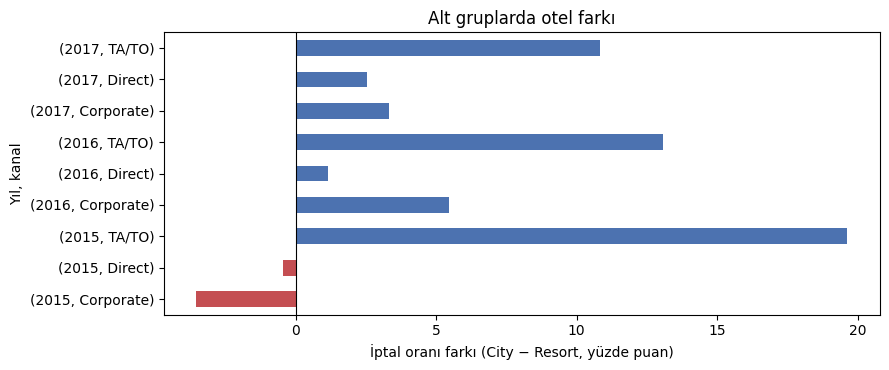

Grafik: Her çubuk bir yıl × kanal grubunda City ile Resort iptal oranı farkı; kırmızılar yönün tersine döndüğü gruplar.


In [19]:
# Olgu: bir rezervasyon. Ölçüler: rezervasyon sayısı ve iptal sayısı (toplanabilir);
# iptal oranı = iptal / rezervasyon (alt grupların oranlarının ortalamasını almıyoruz, sayımlardan hesaplıyoruz).
# Boyutlar: otel türü, varış yılı, dağıtım kanalı.
boyutlar = ["hotel", "arrival_date_year", "distribution_channel"]
olgu = df_eksik[boyutlar + ["is_canceled"]].copy()

def kup(gruplar):
    s = olgu.groupby(gruplar, dropna=False)["is_canceled"].agg(rezervasyon="size", iptal="sum")
    s["iptal_orani_%"] = (100 * s["iptal"] / s["rezervasyon"]).round(2)
    return s

print("Roll-up (en üst düzey): otel türü")
display(kup(["hotel"]))
print("Drill-down: otel → yıl")
display(kup(["hotel", "arrival_date_year"]))
print("Drill-down: City Hotel, 2017 → dağıtım kanalı")
display(kup(boyutlar).loc[("City Hotel", 2017)])

# Simpson kontrolü: genelde City > Resort. Aynı yön, yıl x kanal alt gruplarında da geçerli mi?
# Küçük hücreler yanıltmasın diye iki otelde de en az 100 rezervasyonu olan grupları alıyoruz.
tam = kup(boyutlar)
oran = tam["iptal_orani_%"].unstack("hotel")
sayi = tam["rezervasyon"].unstack("hotel")
alt = oran[sayi.ge(100).all(axis=1)].copy()
alt["Fark (City − Resort)"] = alt["City Hotel"] - alt["Resort Hotel"]
display(alt)
print(f"Yönü tersine dönen alt grup: {(alt['Fark (City − Resort)'] < 0).sum()} / {len(alt)}")

fig, ax = plt.subplots(figsize=(9, 3.8))
alt["Fark (City − Resort)"].plot.barh(ax=ax, color=["#C44E52" if v < 0 else "#4C72B0" for v in alt["Fark (City − Resort)"]])
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="İptal oranı farkı (City − Resort, yüzde puan)", ylabel="Yıl, kanal",
       title="Alt gruplarda otel farkı")
plt.tight_layout(); plt.show()
print("Grafik: Her çubuk bir yıl × kanal grubunda City ile Resort iptal oranı farkı; kırmızılar yönün tersine döndüğü gruplar.")


**Yorum**

**Küp:** Olgu bir rezervasyon; ölçüler rezervasyon sayısı ve iptal sayısı; boyutlar otel türü, varış yılı ve dağıtım kanalı. İptal oranını her düzeyde sayımlardan hesapladık (iptal / rezervasyon); alt grupların oranlarının ortalamasını almadık, çünkü gruplar çok farklı büyüklükte.

**Roll-up ve drill-down:** En üst düzeyde iptal oranı City Hotel'de **%41,73**, Resort Hotel'de **%27,76**. Yıla inince (drill-down) City Hotel her yıl %40–44, Resort Hotel %26–31 arasında; fark her yıl aynı yönde. City Hotel 2017'nin içine kanala göre inince oranın kanala göre çok değiştiğini görüyoruz: TA/TO (seyahat acentesi) **%45,82**, Corporate %27,49, Direct %18,79. Yani City Hotel'in yüksek oranının büyük kısmı acente kanalından geliyor. 2015 ve 2017 yılları verinin kapsadığı aylar nedeniyle eksik yıllar; tam yıl göstergesi olarak okunmamalı.

**Simpson kontrolü:** Genelde City Hotel'in iptal oranı daha yüksek. İki otelde de en az 100 rezervasyonu olan **9 yıl × kanal grubunda** aynı yönün korunup korunmadığına baktık. **2 grupta yön tersine dönüyor:** 2015 Corporate (City %23,41, Resort %26,95) ve 2015 Direct (%17,65'e karşı %18,10). Kalan 7 grupta City Hotel yine yüksek; farkın en büyük olduğu yer TA/TO kanalı (10,8–19,6 puan). Toplamdaki eğilim her alt gruba genellenemiyor; ancak yön grupların çoğunda korunduğu ve tersine dönen farklar küçük olduğu için bunu tam bir Simpson paradoksu olarak yorumlamadık. Sonuç: "City Hotel daha çok iptal ediliyor" demek yerine "City Hotel'e acente kanalından gelen rezervasyonlar daha çok iptal ediliyor" demek daha doğru.

### 3.2 Birliktelik: seçenek ve kurulum
İşlem bilgisi varsa **A**, yoksa **B**. Veri değiştirilmez.

**Seçenek: B.** Veri kümesindeki her satır tek bir rezervasyon; ürün sepeti ya da birden çok öğeyi bir araya getiren bir işlem kimliği yok. Bu yüzden her rezervasyonu "öznitelik = değer" öğelerinden oluşan bir işleme dönüştürdük.

In [20]:
# B seçeneği: her rezervasyon bir "işlem", her "öznitelik=değer" bir öğe.
# Kurallar için 18 girdiden yorumlanabilir beş sütun seçtik (334 kategorili agent hariç); iptal etiketi
# yalnızca kuralların sonuç tarafında kullanacağız. Kaynak tabloyu (df_eksik) değiştirmiyor, kopyası üzerinde çalışıyoruz.
islem = pd.DataFrame(index=df_eksik.index)
islem["hotel"] = df_eksik["hotel"].map({"City Hotel": "City", "Resort Hotel": "Resort"})
islem["distribution_channel"] = df_eksik["distribution_channel"].fillna("Eksik").replace({"TA/TO": "TA_TO"})

# Ayrıklaştırma: sınırları iptal oranına bakmadan, alan bilgisiyle seçtik.
# lead_time: bir hafta / bir ay / üç ay / daha erken; adults: 0, 1, 2, 3+; geçmiş iptal: yok / var.
for sutun, sinirlar, etiketler in [
    ("lead_time", [-np.inf, 7, 30, 90, np.inf], ["0_7", "8_30", "31_90", "91_plus"]),
    ("adults", [-np.inf, 0, 1, 2, np.inf], ["0", "1", "2", "3_plus"]),
    ("previous_cancellations", [-np.inf, 0, np.inf], ["0", "1_plus"])]:
    islem[sutun] = pd.cut(df_eksik[sutun], sinirlar, labels=etiketler).astype(str)
islem["is_canceled"] = df_eksik["is_canceled"].map({0: "hayir", 1: "evet"})

# mlxtend'in istediği biçim: her öğe bir True/False sütunu ("hotel=City" gibi).
ikili = pd.get_dummies(islem, prefix_sep="=", dtype=bool)
print(f"{len(islem):,} işlem, işlem başına {islem.shape[1]} öğe, toplam {ikili.shape[1]} farklı öğe")
display(islem.head())

# Weka için aynı tablo (bütün sütunlar nominal).
with open("bolum3_islemler.arff", "w", encoding="utf-8") as f:
    f.write("@relation otel_iptal_islemler\n\n")
    for s in islem.columns:
        f.write(f"@attribute {s} {{{','.join(sorted(islem[s].unique()))}}}\n")
    f.write("\n@data\n")
    for satir in islem.itertuples(index=False):
        f.write(",".join(satir) + "\n")
print("Weka dosyası yazıldı: bolum3_islemler.arff")


119,390 işlem, işlem başına 6 öğe, toplam 19 farklı öğe


,hotel,distribution_channel,lead_time,adults,previous_cancellations,is_canceled
0,Resort,Direct,91_plus,2,0,hayir
1,Resort,Direct,91_plus,2,0,hayir
2,Resort,Direct,0_7,1,0,hayir
3,Resort,Corporate,8_30,1,0,hayir
4,Resort,TA_TO,8_30,2,0,hayir


Weka dosyası yazıldı: bolum3_islemler.arff


**Yorum**

Her rezervasyonu altı öğeli bir işleme çevirdik: beş girdi ve sonuç. Örneğin bir işlem `hotel=City`, `distribution_channel=TA_TO`, `lead_time=91_plus`, `adults=2`, `previous_cancellations=0`, `is_canceled=hayir` öğelerinden oluşuyor. 119.390 işlemde toplam **19 farklı öğe** var. İptal öğesini 3.3'te yalnızca kuralların sonuç tarafında kullandık. Kaynak tabloyu değiştirmedik; dönüşümü ayrı bir kopyada yaptık.

**Neden bu beş sütunu seçtik?** 18 girdinin hepsi öğe sayısını ve kural sayısını yorumlanamayacak kadar artırırdı; 334 kategorili `agent` tek başına yüzlerce öğe üretirdi. Bu yüzden 2.2'deki ağacın kullandığı (`lead_time`, `previous_cancellations`) ve alan bilgisiyle yorumlanabilir (`hotel`, `distribution_channel`, `adults`) beş sütunu seçtik.

**Ayrıklaştırma:** Sınırları iptal oranına bakmadan, alan bilgisiyle seçtik: `lead_time` için 0–7 gün (bir hafta), 8–30 (bir ay), 31–90 (üç ay) ve 91+ (daha erken); `adults` için 0, 1, 2, 3+; `previous_cancellations` için yok (0) / var (1+). Sınırları hedefe bakarak seçseydik kurallar o veriye özgü kalırdı. Aynı nominal tabloyu Weka için ARFF olarak kaydettik.

### 3.3 Kurallar ve ilgi ölçütleri
**Seçenek B (gerekçesi 3.2'de):** ayrıklaştırma ve "öznitelik = değer" işlemleri; hedefe yönelik kurallar; lift ve Kulczynski; Proje 1 modelinin önemli öznitelikleriyle karşılaştırma; nadir kategorilerde lift ile Kulczynski farkı; üç kuralın alan bilgisiyle yorumu.

In [21]:
# 3.3 · Seçenek B: hedefe yönelik kurallar ve ilgi ölçütleri
# Gösterim: "öncül ⇒ sonuç". Öncül, kuralın koşul tarafındaki öğe kümesidir;
# sonuç her zaman is_canceled=evet (yönerge, B seçeneği: hedefe yönelik kurallar).

# 1) Apriori: en az %1 destek
DESTEK, GUVEN = 0.01, 0.30
sik = apriori(ikili, min_support=DESTEK, use_colnames=True)
destek = dict(zip(sik["itemsets"], sik["support"]))          # küme -> destek
print("Sık öğe kümesi sayısı:", len(sik))

# 2) Hedefe yönelik kurallar: öncül ⇒ is_canceled=evet. Kuralları sık kümelerden elle türetiyoruz:
#    güven      = P(iptal | öncül) = destek(öncül ∪ iptal) / destek(öncül)
#    lift       = güven / P(iptal)
#    Kulczynski = (P(iptal | öncül) + P(öncül | iptal)) / 2
HEDEF = "is_canceled=evet"
p_iptal = destek[frozenset([HEDEF])]
kurallar = []
for kume, d in destek.items():
    if HEDEF in kume and len(kume) > 1:
        oncul = kume - {HEDEF}                               # öğe kümesinden iptal öğesini çıkar, kalanı öncül
        guven = d / destek[oncul]
        if guven >= GUVEN:
            kurallar.append({"Öncül": " & ".join(sorted(oncul)),
                             "Öncül kayıt": round(destek[oncul] * len(ikili)),
                             "Destek": d, "Güven": guven, "Lift": guven / p_iptal,
                             "Kulczynski": (guven + d / p_iptal) / 2})
kurallar = pd.DataFrame(kurallar)

# Neredeyse her kayıtta bulunan öğeler ("yokluk" öğeleri): Kulczynski'yi şişirebilirler #---
cok_yaygin = ikili.mean().loc[lambda s: s > 0.90].round(3)
print("Kayıtların %90'ından fazlasında bulunan öğeler:", cok_yaygin.to_dict())
kurallar["İlişki"] = np.where(kurallar["Lift"] > 1, "pozitif", "negatif")




print(f"Sonucu iptal olan kural sayısı: {len(kurallar)} (genel iptal oranı {p_iptal:.4f})")
for olcut in ["Lift", "Kulczynski"]:
    print(f"\n{olcut} sıralamasında ilk 8 kural:")
    display(kurallar[kurallar["Lift"] > 1].sort_values(olcut, ascending=False).head(8).round(4))   #---

# 3) Tekrar kontrolü: en yüksek lift'li kural tam kopyalar çıkarılınca da geçerli mi?
en_ust = kurallar.sort_values("Lift", ascending=False).iloc[0]
ogeler = en_ust["Öncül"].split(" & ")
kosul = ikili[ogeler].all(axis=1)
tekil = (~df.duplicated()).to_numpy()
print(f"\nEn yüksek lift'li kural: {en_ust['Öncül']}")
for ad, maske in [("Tüm veri", np.ones(len(ikili), bool)), ("Tekil veri", tekil)]:
    k = kosul & maske
    print(f"  {ad:<10}: öncül {k.sum():>6,} kayıt, iptal oranı {ikili.loc[k, HEDEF].mean():.3f}, "
          f"destek {(k & ikili[HEDEF]).sum() / maske.sum():.4f}")

# 4) Proje 1 modeliyle karşılaştırma: 2.5'te seçilen modelin permütasyon önemi (görmediği test kısmında).
egitim, test = bolmeler_2[0]
model_33 = clone(hatlar_2[secilen]).fit(X2.iloc[egitim], y2.iloc[egitim])
perm = permutation_importance(model_33, X2.iloc[test], y2.iloc[test], scoring="f1",
                              n_repeats=5, random_state=SEED, n_jobs=-1)
onem = pd.DataFrame({"F1 düşüşü": perm.importances_mean, "std": perm.importances_std},
                    index=X2.columns).sort_values("F1 düşüşü", ascending=False)
onem["sıra"] = range(1, len(onem) + 1)
onem["kurallarda"] = np.where(onem.index.isin(["hotel", "distribution_channel", "lead_time", "adults",
                                               "previous_cancellations"]), "evet", "")
print(f"\n{secilen}: permütasyon önemi (test kısmı, 5 karıştırma)")
display(onem.round(4))

# 5) Nadir kategoriler: lift ile Kulczynski'nin farkı

NADIR_ESIK = 0.10                           # öğe kayıtların %10'undan azında geçiyorsa "nadir"
n_islem = len(ikili)
iptal_mi = ikili[HEDEF]
n_iptal = int(iptal_mi.sum())

nadir_kurallar = []
for oge in ikili.columns:
    if oge.startswith("is_canceled="):
        continue
    oncul_mi = ikili[oge]
    n_oncul = int(oncul_mi.sum())
    if n_oncul == 0 or n_oncul / n_islem >= NADIR_ESIK:
        continue
    n_ortak = int((oncul_mi & iptal_mi).sum())
    guven = n_ortak / n_oncul
    nadir_kurallar.append({
        "Öncül": oge,
        "Öncül kayıt": n_oncul,
        "Öncül oranı (%)": round(n_oncul / n_islem * 100, 2),
        "Güven": guven,
        "Lift": guven / p_iptal,
        "P(öncül | iptal)": n_ortak / n_iptal,                # iptallerin ne kadarını kapsıyor
        "Kulczynski": (guven + n_ortak / n_iptal) / 2,
        "Apriori'de var mı": "evet" if (n_ortak / n_islem >= DESTEK and guven >= GUVEN) else "hayır",
    })

nadir_kurallar = pd.DataFrame(nadir_kurallar).sort_values("Lift", ascending=False)
nadir_kurallar["Lift sırası"] = nadir_kurallar["Lift"].rank(ascending=False, method="min").astype(int)
nadir_kurallar["Kulczynski sırası"] = nadir_kurallar["Kulczynski"].rank(ascending=False, method="min").astype(int)

print(f"\nNadir öğeli kurallar (öğe kayıtların %{NADIR_ESIK * 100:.0f}'undan azında), öncül ⇒ iptal:")
display(nadir_kurallar.round(4))

# Karşılaştırma için en yaygın öncül: aynı iki ölçütte nerede duruyor?
yaygin = kurallar.loc[kurallar["Öncül"] == "distribution_channel=TA_TO"]
print("\nKarşılaştırma: en yaygın öncül (distribution_channel=TA_TO ⇒ iptal)")
display(yaygin[["Öncül", "Öncül kayıt", "Güven", "Lift", "Kulczynski"]].round(4))
print("Not: 30'dan az kaydı olan öncüllerde güven ve lift çok oynaktır; bu kuralları yorumda kanıt olarak kullanmayın.")

Sık öğe kümesi sayısı: 702
Kayıtların %90'ından fazlasında bulunan öğeler: {'previous_cancellations=0': 0.946}
Sonucu iptal olan kural sayısı: 121 (genel iptal oranı 0.3704)

Lift sıralamasında ilk 8 kural:


,Öncül,Öncül kayıt,Destek,Güven,Lift,Kulczynski,İlişki
118,adults=2 & distribution_channel=TA_TO & hotel=...,3369,0.0282,1.0000,2.6997,0.5381,pozitif
113,adults=2 & distribution_channel=TA_TO & lead_t...,3930,0.0329,1.0000,2.6997,0.5444,pozitif
101,adults=2 & hotel=City & lead_time=91_plus & pr...,3443,0.0288,1.0000,2.6997,0.5389,pozitif
91,distribution_channel=TA_TO & hotel=City & lead...,3799,0.0318,1.0000,2.6997,0.5430,pozitif
73,distribution_channel=TA_TO & lead_time=91_plus...,4391,0.0368,0.9998,2.6991,0.5495,pozitif
82,adults=2 & lead_time=91_plus & previous_cancel...,4133,0.0346,0.9990,2.6971,0.5462,pozitif
54,hotel=City & lead_time=91_plus & previous_canc...,3887,0.0325,0.9974,2.6927,0.5425,pozitif
76,adults=2 & distribution_channel=TA_TO & previo...,4624,0.0385,0.9952,2.6868,0.5497,pozitif



Kulczynski sıralamasında ilk 8 kural:


,Öncül,Öncül kayıt,Destek,Güven,Lift,Kulczynski,İlişki
1,distribution_channel=TA_TO,97870,0.3363,0.4103,1.1076,0.6591,pozitif
4,adults=2,89680,0.2953,0.3932,1.0614,0.5952,pozitif
0,hotel=City,79330,0.2773,0.4173,1.1265,0.5829,pozitif
27,distribution_channel=TA_TO & previous_cancella...,92389,0.2908,0.3758,1.0145,0.5804,pozitif
25,adults=2 & distribution_channel=TA_TO,76987,0.2730,0.4233,1.1427,0.5801,pozitif
8,distribution_channel=TA_TO & hotel=City,68945,0.2600,0.4503,1.2155,0.5761,pozitif
28,distribution_channel=TA_TO & previous_cancella...,5481,0.0455,0.9912,2.6760,0.5570,pozitif
35,lead_time=91_plus & previous_cancellations=1_plus,4670,0.0389,0.9946,2.6852,0.5498,pozitif



En yüksek lift'li kural: adults=2 & distribution_channel=TA_TO & hotel=City & lead_time=91_plus & previous_cancellations=1_plus
  Tüm veri  : öncül  3,369 kayıt, iptal oranı 1.000, destek 0.0282
  Tekil veri: öncül    301 kayıt, iptal oranı 1.000, destek 0.0034

Rastgele orman: permütasyon önemi (test kısmı, 5 karıştırma)


,F1 düşüşü,std,sıra,kurallarda
market_segment,0.1263,0.0022,1,
agent,0.1262,0.0008,2,
lead_time,0.1106,0.0047,3,evet
customer_type,0.1101,0.0016,4,
hotel,0.0796,0.0027,5,evet
previous_cancellations,0.0549,0.0014,6,evet
arrival_date_month,0.0439,0.0014,7,
meal,0.0337,0.0016,8,
reserved_room_type,0.0303,0.0009,9,
stays_in_week_nights,0.0291,0.0016,10,



Nadir öğeli kurallar (öğe kayıtların %10'undan azında), öncül ⇒ iptal:


,Öncül,Öncül kayıt,Öncül oranı (%),Güven,Lift,P(öncül | iptal),Kulczynski,Apriori'de var mı,Lift sırası,Kulczynski sırası
5,previous_cancellations=1_plus,6484,5.43,0.9164,2.4740,0.1344,0.5254,evet,1,1
1,distribution_channel=Eksik,5,0.00,0.8000,2.1597,0.0001,0.4000,hayır,2,2
4,adults=3_plus,6280,5.26,0.3476,0.9384,0.0494,0.1985,evet,3,3
3,adults=0,403,0.34,0.2705,0.7302,0.0025,0.1365,hayır,4,4
0,distribution_channel=Corporate,6677,5.59,0.2208,0.5960,0.0333,0.1270,hayır,5,5
2,distribution_channel=GDS,193,0.16,0.1917,0.5176,0.0008,0.0963,hayır,6,6



Karşılaştırma: en yaygın öncül (distribution_channel=TA_TO ⇒ iptal)


,Öncül,Öncül kayıt,Güven,Lift,Kulczynski
1,distribution_channel=TA_TO,97870,0.4103,1.1076,0.6591


Not: 30'dan az kaydı olan öncüllerde güven ve lift çok oynaktır; bu kuralları yorumda kanıt olarak kullanmayın.


**Yorum**

Apriori'yi %1 en küçük destekle (yaklaşık 1.194 rezervasyon) çalıştırdığımızda 702 sık öğe kümesi bulduk. Bunlardan sonucu `is_canceled=evet` olan ve güveni en az %30 olan 121 kural çıkardık. Genel iptal oranı %37,04 olduğu için %30 güveni geçen her kural iptalle pozitif ilişkili olmuyor, bu yüzden sıralamalarda sadece lift değeri 1'den büyük olan kurallara baktık. Bütün kuralların sonucu aynı olduğu için güven ve lift aynı sıralamayı veriyor. Kulczynski ise P(iptal | öncül) ve P(öncül | iptal) değerlerinin ortalaması olduğu için kuralın iptallerin ne kadarını kapsadığını da hesaba katıyor ve farklı bir sıralama çıkarıyor.

Neredeyse her kayıtta bulunan öğelere de dikkat ettik. `previous_cancellations=0` öğesi kayıtların %94,6'sında var. `previous_cancellations=0 ⇒ iptal` kuralında 112.906 öncülün 38.282'si iptal edilmiş (sayımlar 3.4'teki Weka çıktısında da aynı): güven 0,339, lift 0,92, yani kural aslında iptalle negatif ilişkili. Buna karşılık iptallerin %86,6'sı bu öğeyi taşıdığı için Kulczynski 0,602'ye çıkıyor ve kural, lift > 1 süzgeci olmadan yapılan Kulczynski sıralamasında TA_TO'dan (0,659) sonra ikinci sıraya geliyor. Kulczynski'nin yüksek çıkması, iptal edilen rezervasyonların çoğunun zaten bu öğeyi taşımasından kaynaklanıyor. Bu yüzden bu kuralı yorumumuza katmadık.

Yorumladığımız üç kural:

| # | Kural (öncül ⇒ iptal) | Öncül kayıt | Güven | Lift | Kulczynski |
|---|---|---|---|---|---|
| 1 | 2 yetişkin, TA_TO, City, lead_time 91+, geçmiş iptal var | 3.369 | 1,000 | 2,70 | 0,538 |
| 2 | distribution_channel = TA_TO | 97.870 | 0,410 | 1,11 | 0,659 |
| 3 | TA_TO, City | 68.945 | 0,450 | 1,22 | 0,576 |

1. **En yüksek lift'li kural:** Bu beş koşulu taşıyan 3.369 rezervasyonun hepsi iptal edilmiş. Ama birebir aynı satırları çıkardığımızda kayıt sayısı 301'e, destek de %2,82'den %0,34'e düşüyor (bu kayıtların da hepsi iptal edilmiş). Bu yüzden kuralın, aynı şekilde girilip topluca iptal edilen grup rezervasyonlarını yakaladığını düşünüyoruz. 2.2'deki ağaçta iptal oranı %98,7 olan yaprak da aynı grubu gösteriyordu. %100 güven ilk bakışta sızıntı şüphesi uyandırabilir, ama kurallarda kullandığımız beş sütunun hiçbiri 1.2'deki şüpheli öznitelikler arasında yok; hepsi rezervasyon yapılırken bilinen bilgiler. `reservation_status` gibi kesin sızıntı sütunlarını bilerek dışarıda bıraktık. Bunları ekleseydik `reservation_status=Canceled ⇒ iptal` gibi güveni 1 olan ama bize hiçbir şey öğretmeyen kurallar en üste çıkardı. Bu yüzden %100 güveni yeni bir rezervasyon için kesin bir sonuç gibi yorumlamadık. Kulczynski de bu kuralı orta sıralara koyuyor, çünkü kural iptallerin sadece küçük bir kısmını kapsıyor.

2. **TA_TO ⇒ iptal:** Lift sadece 1,11, yani acente kanalından gelmek iptal olasılığını genel orana göre biraz artırıyor. Buna karşılık bu kural Kulczynski sıralamasında birinci, çünkü iptallerin yaklaşık %91'i bu kanaldan geliyor. Aynı kuralın iki ölçütte bu kadar farklı yerde olması, ölçütlerin farklı şeyleri ölçmesinden kaynaklanıyor: lift ilişkinin ne kadar güçlü olduğunu, Kulczynski ise kuralın iki yönden ne kadar kapsayıcı olduğunu gösteriyor.

3. **TA_TO ve City ⇒ iptal:** Acente kanalına City Hotel koşulunu eklediğimizde güven %41'den %45'e, lift de 1,22'ye çıkıyor. Bu, 3.1'deki küp analizinde bulduğumuzla aynı: City Hotel'in iptal oranının yüksek olmasının önemli bir nedeni acente kanalı. Ancak bu sadece bir birliktelik; kanalın ya da otel türünün iptale neden olduğunu göstermiyor.

**Nadir kategoriler:** %1 destek eşiği çok nadir öğeleri Apriori'nin dışında bıraktığı için kayıtların %10'undan azında geçen öğeleri ayrıca inceledik. En dikkat çekici örnek `previous_cancellations=1_plus`: daha önce iptali olan müşterilere ait 6.484 rezervasyonun (%5,4) %91,6'sı iptal edilmiş ve lift 2,47. Lift'e bakınca bu öğe, TA_TO'dan (1,11) çok daha güçlü bir iptal işareti gibi görünüyor. Ama Kulczynski değeri 0,525 ile TA_TO'nun (0,659) altında kalıyor, çünkü bütün iptallerin sadece %13,4'ü bu gruptan geliyor. Yani iki ölçüt bu iki kuralı ters sırayla diziyor. Bunun nedeni iki ölçütün tanımında: lift yalnızca P(iptal | öncül)'ü genel iptal oranıyla karşılaştırıyor ve öncülün kaç kayıtta geçtiğine bakmıyor; Kulczynski ise P(öncül | iptal) terimi sayesinde iptallerin ne kadarının kapsandığını da hesaba katıyor. Wu vd. (2010) de lift'in kuralla ilgisi olmayan kayıtların sayısından etkilendiğini, Kulczynski'nin ise etkilenmediğini (null-değişmez olduğunu) gösteriyor. Bu yüzden iki ölçütü birlikte raporladık. Bu öğenin yüksek güveninde, yukarıda gördüğümüz kopya grup rezervasyonlarının da payı olabilir.

Diğer nadir öğelerin hepsinde lift 1'in altında: `adults=3_plus` (6.280 kayıt, lift 0,94), `adults=0` (403 kayıt, 0,73), `Corporate` kanalı (6.677 kayıt, 0,60) ve `GDS` kanalı (193 kayıt, 0,52). Bu gruplarda iptal oranı genel ortalamanın altında; özellikle kurumsal ve GDS rezervasyonları daha az iptal ediliyor. Nadir öğelerin kendi aralarında lift ve Kulczynski sıralaması aynı çıktı, çünkü bu öğelerde P(öncül | iptal) çok küçük olduğu için Kulczynski yaklaşık olarak güvenin yarısına eşit oluyor ve güvenle aynı sırayı izliyor. `distribution_channel=Eksik` öğesinin lift'i yüksek (2,16) ama sadece 5 kayda dayanıyor; 30'dan az kayıtlı öğeler çok oynak olduğu için bunu yorumda kullanmadık.

**Model önemiyle karşılaştırma:** Kuralları, 2.5'te seçtiğimiz rastgele ormanın permütasyon önemiyle karşılaştırdık (test verisinde bir sütun karıştırılınca F1'deki düşüş). Kurallarda kullandığımız beş sütundan `lead_time` 3., `hotel` 5., `previous_cancellations` 6. sırada; yani kurallar ve model bu sütunlarda büyük ölçüde aynı sonucu veriyor. Özellikle `previous_cancellations`'ın hem modelde ilk altıda olması hem de nadir öğeler arasında en yüksek lift'i vermesi birbiriyle tutarlı. `distribution_channel` (11.) ve `adults` (13.) modelde daha geride. TA_TO'nun kurallarda çok sık çıkması bu öğenin çok yaygın olmasından kaynaklanıyor; model ise aynı bilgiyi daha ayrıntılı taşıyan `market_segment` (1.) ve `agent` (2.) sütunlarını kullanıyor. Kurallar belirli grupların birlikte görülmesini, permütasyon önemi ise modelin bir sütuna ne kadar dayandığını ölçtüğü için ikisini aynı şey gibi yorumlamadık.

### 3.4 Weka ile kontrol

In [22]:
# 3.4 · Weka ile kontrol
# 1) 3.2'de yazdığımız işlem tablosunu (Weka Explorer'a yükleyeceğimiz dosya) kontrol edip indiriyoruz.
# 2) Aynı dosyayı Weka Apriori'ye komut satırından da verip sonucu Python'daki kurallarla karşılaştırıyoruz.

ARFF = "bolum3_islemler.arff"   # 3.2'de yazıldı

# Dosya kontrolü: öznitelikler ve işlem sayısı Python'daki tabloyla aynı mı?
with open(ARFF, encoding="utf-8") as f:
    arff_satirlari = f.read().splitlines()
oznitelikler = [s.split()[1] for s in arff_satirlari if s.startswith("@attribute")]
islem_sayisi = len(arff_satirlari) - (arff_satirlari.index("@data") + 1)
print(f"{ARFF}: {len(oznitelikler)} öznitelik, {islem_sayisi:,} işlem "
      f"({os.path.getsize(ARFF) / 1e6:.1f} MB)")
print("Öznitelikler:", ", ".join(oznitelikler))
assert oznitelikler == list(islem.columns) and islem_sayisi == len(islem), "ARFF, Python'daki işlem tablosuyla uyuşmuyor."

# Otomatik indirme hücreyi bekletebildiği için dosyayı Dosyalar bölümünden indiriyoruz.
print(f"Weka Explorer dosyası hazır: sol paneldeki Dosyalar bölümünden {ARFF} dosyasını indirin.")

print(f"""
Weka Explorer'da aynı kontrol:
  Preprocess -> Open file... -> {ARFF}
  Associate  -> Choose: Apriori, ayarlar:
      lowerBoundMinSupport = {DESTEK}   upperBoundMinSupport = 1.0   delta = {1 - DESTEK:.2f}
      metricType = Confidence   minMetric = {GUVEN}   numRules = 100000   car = False
  Start -> çıktıda '==> is_canceled=evet' ile biten kuralları Python'daki {len(kurallar)} kuralla karşılaştırın.
""")

# Weka Apriori'yi komut satırından, Python'la aynı eşiklerle çalıştırıyoruz.
weka_cikti = ""
try:
    jar = "weka-stable-3.8.6.jar"
    for ad, yol in [(jar, "weka-stable/3.8.6/" + jar), ("bounce-0.18.jar", "thirdparty/bounce/0.18/bounce-0.18.jar")]:
        if not os.path.exists(ad):
            urllib.request.urlretrieve("https://repo.maven.apache.org/maven2/nz/ac/waikato/cms/weka/" + yol, ad)
    komut = ["java", "-cp", f"{jar}:bounce-0.18.jar", "weka.associations.Apriori",
             "-t", ARFF, "-N", "100000", "-T", "0", "-C", str(GUVEN),
             "-M", str(DESTEK), "-D", str(1 - DESTEK), "-U", "1.0"]
    weka_cikti = subprocess.run(komut, capture_output=True, text=True, check=True, timeout=300).stdout
    open("bolum3_weka_apriori.txt", "w", encoding="utf-8").write(weka_cikti)
except Exception as hata:
    print("Weka bu ortamda çalıştırılamadı:", hata)

# Yalnız sonucu iptal olan kuralları alıp öncül ve ortak sayılarını Python'la karşılaştırıyoruz.
weka_kurallar = {" & ".join(sorted(a.split())): (int(n_a), int(n_ab)) for a, n_a, n_ab in re.findall(
    r"^\s*\d+\.\s+(.+?)\s+(\d+)\s+==>\s+is_canceled=evet\s+(\d+)\s", weka_cikti, re.M)}
python_kurallar = {r["Öncül"]: (r["Öncül kayıt"], round(r["Destek"] * len(ikili)))
                   for _, r in kurallar.iterrows()}
if weka_kurallar:
    ortak = weka_kurallar.keys() & python_kurallar.keys()
    print(f"Weka: {len(weka_kurallar)} kural | Python: {len(python_kurallar)} kural | ortak: {len(ortak)}")
    print("Sayıları birebir aynı olan kural:", sum(weka_kurallar[k] == python_kurallar[k] for k in ortak))
    print("\nWeka çıktısının ilk satırları:")
    print("\n".join([l for l in weka_cikti.splitlines() if "==> is_canceled=evet" in l][:5]))
else:
    print("Karşılaştırma için Weka çıktısı yok; Python tarafında", len(python_kurallar), "kural var.")

bolum3_islemler.arff: 6 öznitelik, 119,390 işlem (3.4 MB)
Öznitelikler: hotel, distribution_channel, lead_time, adults, previous_cancellations, is_canceled
Weka Explorer dosyası hazır: sol paneldeki Dosyalar bölümünden bolum3_islemler.arff dosyasını indirin.

Weka Explorer'da aynı kontrol:
  Preprocess -> Open file... -> bolum3_islemler.arff
  Associate  -> Choose: Apriori, ayarlar:
      lowerBoundMinSupport = 0.01   upperBoundMinSupport = 1.0   delta = 0.99
      metricType = Confidence   minMetric = 0.3   numRules = 100000   car = False
  Start -> çıktıda '==> is_canceled=evet' ile biten kuralları Python'daki 121 kuralla karşılaştırın.

Weka: 121 kural | Python: 121 kural | ortak: 121
Sayıları birebir aynı olan kural: 121

Weka çıktısının ilk satırları:
     9. distribution_channel=TA_TO lead_time=91_plus adults=2 previous_cancellations=1_plus 3930 ==> is_canceled=evet 3930    <conf:(1)> lift:(2.7) lev:(0.02) [2474] conv:(2474.26)
    11. hotel=City distribution_channel=TA_TO lead_t

**Apriori Weka Çıktısı** (Weka 3.8.7 Explorer, aynı ARFF dosyası)

```text
=== Run information ===

Scheme:       weka.associations.Apriori -N 100000 -T 0 -C 0.3 -D 0.99 -U 1.0 -M 0.01 -S -1.0 -c -1
Relation:     otel_iptal_islemler
Instances:    119390
Attributes:   6
              hotel
              distribution_channel
              lead_time
              adults
              previous_cancellations
              is_canceled
=== Associator model (full training set) ===


Apriori
=======

Minimum support: 0.01 (1194 instances)
Minimum metric <confidence>: 0.3
Number of cycles performed: 2

Generated sets of large itemsets:

Size of set of large itemsets L(1): 16

Size of set of large itemsets L(2): 91

Size of set of large itemsets L(3): 217

Size of set of large itemsets L(4): 235

Size of set of large itemsets L(5): 121

Size of set of large itemsets L(6): 22
```


**Kural listesinden seçilmiş satırlar** (Weka 3.8.7 Explorer çıktısından, `3.4_weka_output.txt`; Colab'daki Weka 3.8.6 çıktısında da sayımlar aynı. Toplam 3.908 kural)


```text
Best rules found:

    13. hotel=City distribution_channel=TA_TO lead_time=91_plus adults=2 previous_cancellations=1_plus 3369 ==> is_canceled=evet 3369    <conf:(1)> lift:(2.7) lev:(0.02) [2121] conv:(2121.07)
    26. distribution_channel=TA_TO lead_time=91_plus previous_cancellations=1_plus 4391 ==> is_canceled=evet 4390    <conf:(1)> lift:(2.7) lev:(0.02) [2763] conv:(1382.25)
  2752. hotel=City distribution_channel=TA_TO 68945 ==> is_canceled=evet 31043    <conf:(0.45)> lift:(1.22) lev:(0.05) [5504] conv:(1.15)
  3022. distribution_channel=TA_TO 97870 ==> is_canceled=evet 40152    <conf:(0.41)> lift:(1.11) lev:(0.03) [3899] conv:(1.07)
  3582. previous_cancellations=0 112906 ==> is_canceled=evet 38282    <conf:(0.34)> lift:(0.92) lev:(-0.03) [-3540] conv:(0.95)
```

**Yorum**

Python'da bulduğumuz kuralları Weka'nın Apriori'siyle kontrol ettik. Weka'ya 3.2'de oluşturduğumuz işlem tablosunu (`bolum3_islemler.arff`) verdik ve Python'la aynı eşikleri kullandık: destek ≥ %1, güven ≥ %30. Weka güven değerini iki basamağa yuvarladığı için kuralları güvene göre değil, sayımlara göre karşılaştırdık: her kural için öncülün geçtiği kayıt sayısı ve öncülle iptalin birlikte geçtiği kayıt sayısı. Örneğin `TA_TO, lead_time 91+, geçmiş iptal var ⇒ iptal` kuralında Weka güveni 1 olarak gösteriyor, ama sayımlara bakınca 4.391 öncülün 4.390'ının iptal edildiği, yani güvenin aslında 0,9998 olduğu görülüyor.

Kontrolü iki şekilde yaptık. Önce Colab'da Weka 3.8.6'yı komut satırından çalıştırıp sonucu otomatik olarak Python'la karşılaştırdık. Python 121 kural buldu, Weka da sonucu `is_canceled=evet` olan 121 kural buldu ve 121 kuralın hepsinde öncül ve ortak kayıt sayıları Python'la birebir aynı çıktı.

Sonra aynı ARFF dosyasını kendi bilgisayarımızda Weka 3.8.7 Explorer'da aynı ayarlarla çalıştırdık (`lowerBoundMinSupport = 0.01`, `minMetric = 0.3`, `delta = 0.99`, `numRules = 100000`). Weka en küçük desteği 1.194 kayıt olarak hesapladı ve toplam 702 sık öğe kümesi buldu (L1–L6: 16, 91, 217, 235, 121, 22); bu sayı Python'daki 702 ile aynı. Tekli kümelerin 16 olması da beklediğimiz gibi: işlem tablosundaki 19 öğeden üçü (`distribution_channel=GDS`, `distribution_channel=Eksik` ve `adults=0`) kayıtların %1'inden azında geçtiği için sık küme olamıyor. Weka bütün sonuçlar için toplam 3.908 kural listeledi; bunlardan sonucu `is_canceled=evet` olan 121 kural, Python'daki 121 kuralla aynı. 3.3'te yorumladığımız kurallar Explorer çıktısında da aynı sayımlarla çıktı: 5 öğeli kuralda 3.369 öncülün 3.369'u iptal (lift 2,7), `distribution_channel=TA_TO` kuralında 97.870 öncülün 40.152'si iptal, City ve TA_TO kuralında 68.945 öncülün 31.043'ü iptal. 3.3'te dışarıda bıraktığımız `previous_cancellations=0` kuralı da Weka'da lift 0,92 ile, yani iptalle negatif ilişkili olarak görünüyor. 121 kuraldan 86'sının lift değeri 1'den büyük.

İki farklı Weka sürümü ve Python aynı sık öğe kümelerini ve aynı kuralları bulduğu için, işlem tablosunu oluştururken ve kuralları elle türetirken hata yapmadığımızı düşünüyoruz. Weka'nın Colab'daki tam çıktısı `bolum3_weka_apriori.txt` dosyasına, Explorer çıktısı (`3.4_weka_output.txt`) ve ekran görüntüleri ise proje klasörüne kaydedildi.

*(Not: Colab'da Weka'nın indirilmesi için internet erişimi gerekir. Erişim yoksa hücre bunu bildirir ve defter çalışmaya devam eder; o durumda kontrol yukarıdaki Explorer ayarlarıyla yapılabilir.)*

# Ek paket 1 · Topluluk yöntemleri ve öznitelik önemi *(4 ve 5 kişilik gruplar)*

### E1.1 Budama eğrisi
Karar ağacında `ccp_alpha` taraması; ağaç boyutu ile eğitim ve test başarımı aynı grafikte.

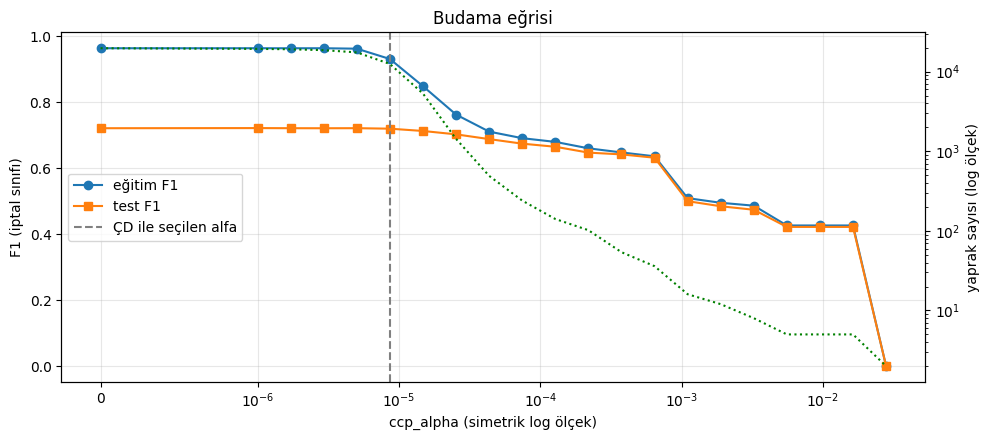

Grafik: Alfa büyüdükçe ağaç küçülür (yeşil); eğitim ve test F1'i aynı eksende.


,alfa,yaprak,eğitim F1,test F1
0,0.00e+00,19720,0.9632,0.7208
1,1.00e-06,19345,0.9632,0.7212
2,1.71e-06,19127,0.9631,0.7209
3,2.94e-06,18646,0.9632,0.7207
4,5.04e-06,17483,0.9619,0.7209
5,8.63e-06,12506,0.9305,0.7194
6,1.48e-05,5306,0.8481,0.7125
7,2.54e-05,1431,0.7621,0.7022
8,4.35e-05,491,0.7105,0.6878
9,7.45e-05,240,0.6906,0.6740


Çapraz doğrulama ile seçilen alfa = 8.63e-06: 12,506 yaprak, eğitim F1 = 0.9305, test F1 = 0.7194


In [23]:
uyarilari_sustur()   # sürüm uyumsuzluğundan gelen, sonuçları etkilemeyen uyarıları gizle (3. hücre)
# Üç deneyde de 2.1'in ilk bölmesini kullanıyoruz (%80 eğitim / %20 test). Ön işlemeyi yalnızca eğitimden öğreniyoruz;
# dönüşümü bir kez yapıp aynı tabloları bütün deneylerde kullanıyoruz.
egitim, test = bolmeler_2[0]
on_e = on_isleme_2().fit(X2.iloc[egitim])
Z_eg, Z_te = on_e.transform(X2.iloc[egitim]), on_e.transform(X2.iloc[test])
y_eg, y_te = y2.iloc[egitim], y2.iloc[test]

# Maliyet-karmaşıklık budama yolu: alfa büyüdükçe en az katkı veren dallar kesilir.
yol = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(Z_eg, y_eg)
alfalar = np.r_[0, np.geomspace(1e-6, yol.ccp_alphas[-2], 20)]   # binlerce alfa yerine 21 değer
satirlar = []
for alfa in alfalar:
    a = DecisionTreeClassifier(ccp_alpha=alfa, random_state=SEED).fit(Z_eg, y_eg)
    satirlar.append({"alfa": alfa, "yaprak": a.get_n_leaves(),
                     "eğitim F1": f1_score(y_eg, a.predict(Z_eg)), "test F1": f1_score(y_te, a.predict(Z_te))})
budama = pd.DataFrame(satirlar)

# Alfayı test kısmına bakarak değil, eğitim kısmında 3 katlı çapraz doğrulama ile seçiyoruz.
secim = GridSearchCV(DecisionTreeClassifier(random_state=SEED), {"ccp_alpha": list(alfalar)}, scoring="f1",
                     cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), n_jobs=-1).fit(Z_eg, y_eg)
alfa_secilen = secim.best_params_["ccp_alpha"]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(budama["alfa"], budama["eğitim F1"], "o-", label="eğitim F1")
ax.plot(budama["alfa"], budama["test F1"], "s-", label="test F1")
ax.axvline(alfa_secilen, color="gray", ls="--", label="ÇD ile seçilen alfa")
ax.set_xscale("symlog", linthresh=1e-6)
ax.set(xlabel="ccp_alpha (simetrik log ölçek)", ylabel="F1 (iptal sınıfı)", title="Budama eğrisi")
ax2 = ax.twinx()
ax2.plot(budama["alfa"], budama["yaprak"], ":", color="green", label="yaprak sayısı")
ax2.set_yscale("log"); ax2.set_ylabel("yaprak sayısı (log ölçek)")
ax.legend(loc="center left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("Grafik: Alfa büyüdükçe ağaç küçülür (yeşil); eğitim ve test F1'i aynı eksende.")
display(budama.round(4).assign(alfa=budama["alfa"].map("{:.2e}".format)))
secilen_satir = budama.loc[budama["alfa"] == alfa_secilen].iloc[0]
print(f"Çapraz doğrulama ile seçilen alfa = {alfa_secilen:.2e}: {int(secilen_satir['yaprak']):,} yaprak, "
      f"eğitim F1 = {secilen_satir['eğitim F1']:.4f}, test F1 = {secilen_satir['test F1']:.4f}")


**Yorum**
Bu deneyde 2.1'deki ilk bölmeyi kullandık (%80 eğitim, %20 test). Karar ağacında 21 farklı ccp_alpha değeri denedik. Her biri için yaprak sayısını, eğitim F1'ini ve test F1'ini aynı grafikte gösterdik. Alfayı test verisine bakarak değil, eğitim kısmında 3 katlı çapraz doğrulamayla seçtik.

Budama yapmadığımızda ağaç 19.720 yapraklı oldu. Eğitimde F1 0,963 çıkarken testte 0,721'de kaldı. Aradaki 0,24'lük fark ağacın eğitim verisini ezberlediğini gösteriyor. Alfayı artırdıkça ağaç küçüldü ve eğitim F1'i hızla düştü, ama test F1'i yükselmedi; yaklaşık 5.000 yaprağa kadar 0,71–0,72 arasında kaldı. Çapraz doğrulamanın seçtiği alfa (8,6·10⁻⁶) 12.506 yapraklı bir ağaç verdi ve test F1'i 0,719 oldu.

Budama test başarısını artırmadı, çünkü test verisindeki bazı satırların aynısı eğitimde de var (1.6). Ağacın ezberlemesi bu yüzden testte de işe yarıyor. Çapraz doğrulamanın büyük bir ağaç seçmesinin nedeninin de bu olduğunu düşünüyoruz, çünkü aynı tekrarlar doğrulama katlarında da bulunuyor.

Raporladığımız sonuç çapraz doğrulamanın seçtiği alfa (8,6·10⁻⁶; 12.506 yaprak; test F1 0,719). Bu ağaç yorumlanamayacak kadar büyük olduğu için, ağacı küçültünce başarının ne kadar düştüğünü görmek amacıyla tablodaki 1.431 yapraklı ağaca (alfa 2,5·10⁻⁵) da baktık. Bu noktayı test eğrisine bakarak bulduğumuz için onun test F1'ini (0,702) modelin başarısı olarak raporlamıyoruz; aynı test kısmını hem seçimde hem ölçümde kullanmış oluruz (2.3'teki iyimser yanlılık). Bu ağaç çapraz doğrulamanın seçtiği ağaçtan yaklaşık 9 kat küçük, test F1'i ise yalnızca 0,017 daha düşük. Eğitim ile test arasındaki fark 0,21'den 0,06'ya iniyor, yani ağaç çok daha az ezberliyor. Daha fazla budadığımızda başarı düşmeye devam ediyor: 491 yaprakta test F1'i 0,688, 54 yaprakta 0,64 oluyor. 36 yaprağın altında ise hızla çöküyor; 16 yaprakta F1 0,500'e, 2 yaprakta 0'a iniyor, çünkü ağaç artık hiç iptal tahmin etmiyor.

### E1.2 Doyum eğrisi
Rastgele ormanda ağaç sayısı 1–500; OOB ve test hatası.

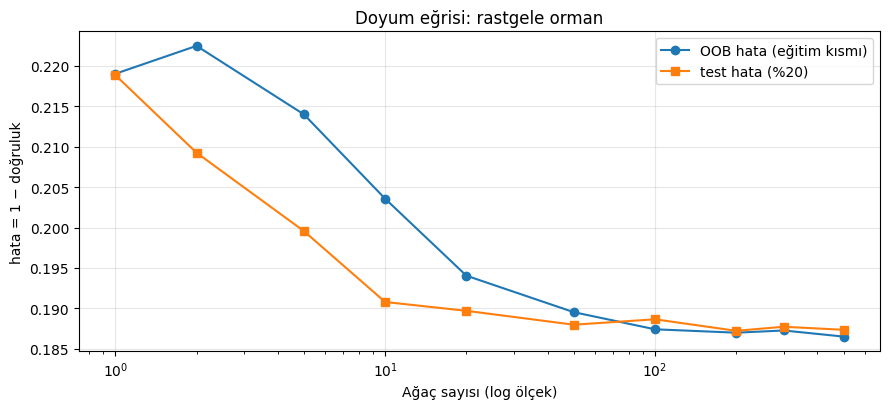

Grafik: Ağaç sayısına (log ölçek) göre OOB hatası ve %20'lik test kısmındaki hata (1 − doğruluk); iki eğri yaklaşık 100 ağaçtan sonra düzleşiyor.


,Ağaç,OOB'si olan kayıt %,OOB hata,test hata
0,1,36.7388,0.2190,0.2188
1,2,59.7946,0.2224,0.2092
2,5,89.9332,0.2140,0.1996
3,10,98.9562,0.2036,0.1908
4,20,99.9822,0.1941,0.1897
5,50,100.0000,0.1895,0.1880
6,100,100.0000,0.1874,0.1887
7,200,100.0000,0.1870,0.1872
8,300,100.0000,0.1873,0.1877
9,500,100.0000,0.1865,0.1874


In [24]:
uyarilari_sustur()   # sürüm uyumsuzluğundan gelen, sonuçları etkilemeyen uyarıları gizle (3. hücre)
# Ormana ağaç ekledikçe hata nasıl değişiyor?
agac_sayilari = [1, 2, 5, 10, 20, 50, 100, 200, 300, 500]
orman = RandomForestClassifier(n_estimators=1, min_samples_leaf=2, oob_score=True, warm_start=True, # warm_start: her adımda yalnız yeni ağaçlar eklenir
                               random_state=SEED, n_jobs=-1)
satirlar = []
for n in agac_sayilari:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")          # az ağaçta bazı kayıtların OOB tahmini olmaz; uyarıyı gizliyoruz
        orman.set_params(n_estimators=n).fit(Z_eg, y_eg)
    oob_var = orman.oob_decision_function_.sum(axis=1) > 0     # OOB tahmini olan kayıtlar
    oob_tahmin = orman.oob_decision_function_.argmax(axis=1)
    satirlar.append({"Ağaç": n, "OOB'si olan kayıt %": 100 * oob_var.mean(),
                     "OOB hata": 1 - (oob_tahmin[oob_var] == y_eg.to_numpy()[oob_var]).mean(),
                     "test hata": 1 - (orman.predict(Z_te) == y_te.to_numpy()).mean()})
doyum = pd.DataFrame(satirlar)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(doyum["Ağaç"], doyum["OOB hata"], "o-", label="OOB hata (eğitim kısmı)")
ax.plot(doyum["Ağaç"], doyum["test hata"], "s-", label="test hata (%20)")
ax.set_xscale("log")
ax.set(xlabel="Ağaç sayısı (log ölçek)", ylabel="hata = 1 − doğruluk", title="Doyum eğrisi: rastgele orman")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("Grafik: Ağaç sayısına (log ölçek) göre OOB hatası ve %20'lik test kısmındaki hata (1 − doğruluk); iki eğri yaklaşık 100 ağaçtan sonra düzleşiyor.")
display(doyum.round(4))


**Yorum**

**Ne yaptık?** Rastgele ormana 1'den 500'e kadar ağaç ekledik (`warm_start=True`: her adımda yalnız yeni ağaçlar eklenir) ve her adımda iki hatayı ölçtük: **OOB hatası** ve %20'lik test kısmındaki hata.

Grafik: Ağaç sayısına (log ölçek) göre OOB hatası ve %20'lik test kısmındaki hata (1 − doğruluk); iki eğri yaklaşık 100 ağaçtan sonra düzleşiyor.

**Ne bulduk?**

| Ağaç | 1 | 5 | 10 | 20 | 50 | 100 | 200 | 500 |
|---|---|---|---|---|---|---|---|---|
| OOB hatası | 0,219 | 0,214 | 0,204 | 0,194 | 0,190 | 0,187 | 0,187 | 0,187 |
| Test hatası | 0,219 | 0,200 | 0,191 | 0,190 | 0,188 | 0,189 | 0,187 | 0,187 |

- Hata ilk 20–50 ağaçta hızla düşüyor ve **yaklaşık 100 ağaçta doyuyor**; 100'den 500'e çıkınca OOB hatası 0,0009, test hatası 0,0013 azalıyor; yani değişim binde bir civarında. Ağaç eklemek aşırı öğrenmeye yol açmıyor, hata yalnızca sabitleniyor; daha fazla ağaç yalnızca hesap süresini artırıyor. 2.1'de 100 ağaç seçmemiz bu yüzden yeterli.
- Tek ağaçta kayıtların yalnızca **%36,7**'sinin OOB tahmini var. 20 ağaçta neredeyse bütün kayıtlar en az bir ağacın dışında kalıyor.
- Az ağaçta OOB hatası test hatasından yüksek, çünkü her kaydın OOB tahmini ağaçların yalnızca üçte biriyle yapılıyor. Ağaç sayısı arttıkça iki eğri birleşiyor: 100 ağaçta OOB 0,187, test 0,189. Yani OOB, ayrı bir test kümesine ya da ek bir çapraz doğrulamaya gerek kalmadan test hatasıyla uyumlu bir hata tahmini veriyor. Ancak kopya satırlar OOB tahminini de test hatası gibi iyimser yapabilir: bir kaydın kopyası ağacın eğitim örnekleminde olabilir (2.1 a).

### E1.3 Öznitelik önemi
Rastgele bir sütun ekleyin; Gini önemi ve permütasyon önemi sıralamalarını karşılaştırın.

,Gini,Permütasyon (F1 düşüşü),Permütasyon std,Gini sırası,Permütasyon sırası
lead_time,0.2053,0.1011,0.0031,1,4
agent,0.1583,0.1257,0.0016,2,1
market_segment,0.0944,0.1206,0.0031,3,2
rastgele_gurultu,0.0911,0.0025,0.0008,4,17
customer_type,0.0878,0.1116,0.0013,5,3
previous_cancellations,0.0805,0.0507,0.0016,6,6
arrival_date_month,0.0636,0.0394,0.0011,7,7
stays_in_week_nights,0.0475,0.0289,0.0011,8,9
stays_in_weekend_nights,0.0279,0.0176,0.0021,9,12
distribution_channel,0.0267,0.0249,0.0014,10,11


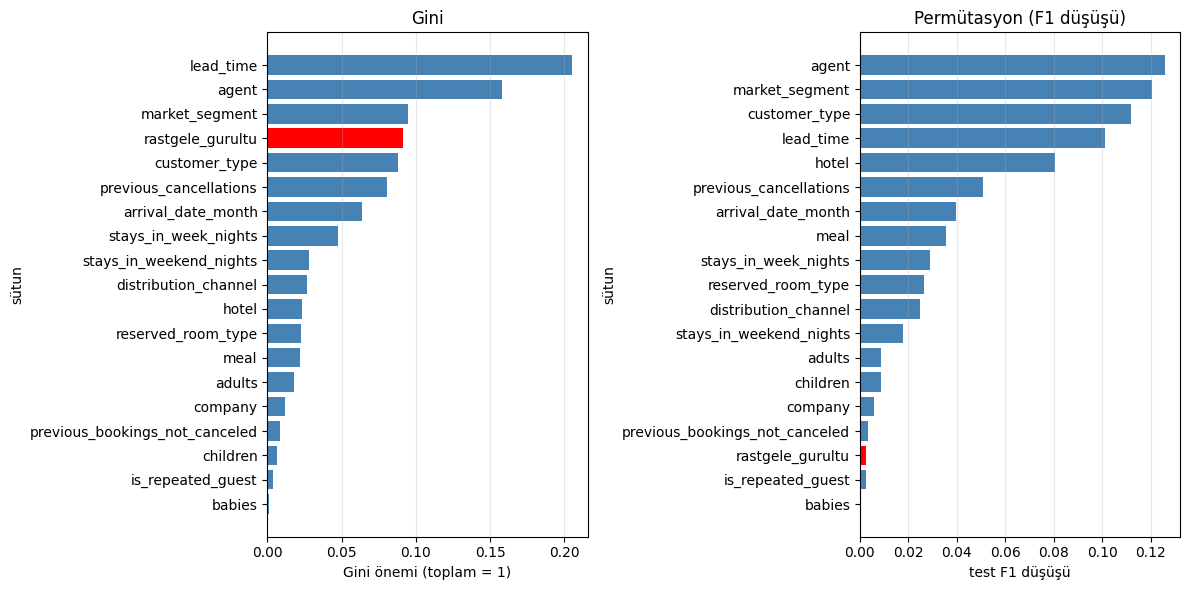

Grafik: Kırmızı çubuk rastgele sütun; Gini onu 4. sıraya, permütasyon 17. sıraya koyuyor (19 sütun arasında).


In [25]:
# rastgele_gurultu: hedefle ilgisi olmayan N(0, 1) sayılar; önem ölçütlerini sınamak için kontrol sütunu.
# Bu sütunu ekleyip aynı ormanı yeniden kuruyoruz.

X3 = X2.assign(rastgele_gurultu=np.random.default_rng(SEED).normal(size=len(X2)))
on_3 = ColumnTransformer([
    ("kategorik", Pipeline([("doldur", SimpleImputer(strategy="constant", fill_value="Eksik")),
                            ("kodla", OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist",
                                                    sparse_output=False))]), kategorik_2),
    ("sayisal", SimpleImputer(strategy="median"), sayisal_2 + ["rastgele_gurultu"])])
orman_3 = Pipeline([("on_isleme", on_3), ("model", RandomForestClassifier(
    n_estimators=100, min_samples_leaf=2, random_state=SEED, n_jobs=-1))])
orman_3.fit(X3.iloc[egitim], y_eg)

# (1) Gini önemi: eğitim verisinde bölmelerin sağladığı saflık artışı.
#     One-Hot sütunlarının önemini ait oldukları ham sütunda topluyoruz.
adlar = orman_3.named_steps["on_isleme"].get_feature_names_out()
ham_ad = [next(s for s in X3.columns if a.split("__", 1)[1] == s or a.split("__", 1)[1].startswith(s + "_"))
          for a in adlar]
gini = pd.Series(orman_3.named_steps["model"].feature_importances_).groupby(ham_ad).sum()

# (2) Permütasyon önemi: test kısmında bir sütun karıştırılınca F1 ne kadar düşüyor?
perm = permutation_importance(orman_3, X3.iloc[test], y_te, scoring="f1", n_repeats=5,
                              random_state=SEED, n_jobs=-1)
onem_3 = pd.DataFrame({"Gini": gini, "Permütasyon (F1 düşüşü)": pd.Series(perm.importances_mean, X3.columns),
                       "Permütasyon std": pd.Series(perm.importances_std, X3.columns)})
onem_3["Gini sırası"] = onem_3["Gini"].rank(ascending=False, method="min").astype(int)
onem_3["Permütasyon sırası"] = onem_3["Permütasyon (F1 düşüşü)"].rank(ascending=False, method="min").astype(int)
display(onem_3.sort_values("Gini sırası").round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, sutun, birim in zip(ax, ["Gini", "Permütasyon (F1 düşüşü)"],
                           ["Gini önemi (toplam = 1)", "test F1 düşüşü"]):
    s = onem_3[sutun].sort_values()
    a.barh(s.index, s.values, color=["red" if i == "rastgele_gurultu" else "steelblue" for i in s.index])
    a.set(title=sutun, xlabel=birim, ylabel="sütun"); a.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()
print(f"Grafik: Kırmızı çubuk rastgele sütun; Gini onu {onem_3.loc['rastgele_gurultu', 'Gini sırası']}. sıraya, "
      f"permütasyon {onem_3.loc['rastgele_gurultu', 'Permütasyon sırası']}. sıraya koyuyor "
      f"({len(onem_3)} sütun arasında).")

**Yorum**

Bu deneyde 18 sütunun yanına, hedefle hiçbir ilgisi olmayan ve normal dağılımdan üretilmiş `rastgele_gurultu` adlı bir sütun ekledik. Aynı rastgele ormanı eğitim verisiyle yeniden kurduk ve iki önem ölçüsünü karşılaştırdık. Gini önemini eğitim verisinden hesapladık; bire-bir kodlanan sütunların önemlerini ait oldukları sütun altında topladık. Permütasyon önemini ise test verisinde her sütunu 5 kez karıştırıp F1'in ne kadar düştüğüne bakarak hesapladık.

Gini önemi rastgele sütunu 19 sütun arasında 4. sıraya koydu (0,091). Yani hiçbir bilgi taşımayan bir sütun customer_type, previous_cancellations ve hotel gibi gerçekten işe yarayan sütunların önüne geçti. Permütasyon öneminde ise aynı sütun 17. sırada ve F1'i yalnızca 0,0025 düşürüyor, yani etkisi neredeyse sıfır. Bunun nedeni, Gini öneminin eğitim verisinden hesaplanması ve çok farklı değer alan sürekli sütunları kayırması. Ağaçlar böyle bir sütunda eğitim verisindeki gürültüye uyan birçok bölme bulabiliyor, ama bu bölmeler test verisinde işe yaramıyor.

Benzer bir farkı gerçek sütunlarda da gördük. Sürekli bir sütun olan lead_time Gini'de 1. sırada, permütasyonda ise 4. sırada. Buna karşılık bazı kategorik sütunlar permütasyonda yukarı çıktı: hotel 11. sıradan 5. sıraya, meal 13. sıradan 8. sıraya, customer_type 5. sıradan 3. sıraya. Bu sütunlar az sayıda değer aldığı için ağaçta az sayıda bölmede kullanılıyor ve Gini'de küçük görünüyor, ama model tahmin yaparken onlara gerçekten dayanıyor.

Bu yüzden öznitelik önemi için permütasyon önemini esas aldık; 3.3'teki karşılaştırmada da onu kullandık. Yine de iki yöntem de agent, market_segment, customer_type ve lead_time sütunlarını ilk beşte gösteriyor. Bu dört sütunun önemli olduğu sonucu kullandığımız yönteme bağlı değil.

## Varsayım defteri
Bu projede verdiğimiz kararlar ve gerekçeleri. Makaleye dayanan kararlar **[makale]** ile işaretli.

**Genel**
- **Karar:** Tahmin anı = rezervasyonun ilk oluşturulduğu an. **Gerekçe:** Otelin önlem alabileceği en erken an; sütun seçimi bu ana göre yapıldı **[makale: Kaufman vd., 2012]**.
- **Karar:** Ana karşılaştırmalarda (1.3–1.6, 2.1) katmanlı 5 kat × 5 tekrar ve tohum 42 kullandık (`cv_olustur`). Bazı deneylerde yöntemin gerektirdiği düzeni kullandık: 1.7'de Weka ile aynı olsun diye 10 kat, 2.1 ek kontrollerde süre kısalsın diye tek tekrarlı 5 kat, 2.3'te iç içe ÇD (5 dış / 3 iç kat), 2.4'te 5×2 ÇD, Ek paket 1'de 2.1'in ilk bölmesi. **Gerekçe:** Ana sonuçlar aynı 25 bölmede ölçüldüğü için bölümler arasında karşılaştırılabiliyor.
- **Karar:** Öğrenen her adımı (doldurma, kodlama, ölçekleme, seçim, hedef kodlama) `Pipeline` içinde tuttuk. Tek istisna, sızıntının etkisini görmek için bilerek yanlış kurduğumuz iki deney: 1.4'te bütün veride yapılan hedef kodlama ve 1.5'te bütün veride yapılan ön işleme + öznitelik seçimi. Bu iki deneyin skorlarını hiçbir kararda kullanmadık. **Gerekçe:** Test bilgisinin eğitime karışmaması **[makale: Kaufman vd., 2012]**; 1.4 ve 1.5'teki karşılaştırmalar.

**Bölüm 1**
- **Karar:** Hedef `is_canceled` (1 = iptal veya No-Show). **Gerekçe:** Veri böyle kodlanmış; hedef bir vekil olarak raporlandı.
- **Karar:** `reservation_status`, `reservation_status_date` modelden çıkarıldı. **Gerekçe:** Sonucu taşıyorlar (kesin sızıntı) **[makale: Antonio vd., 2019; Kaufman vd., 2012]**.
- **Karar:** `booking_changes`, `assigned_room_type`, `days_in_waiting_list` çıkarıldı. **Gerekçe:** Rezervasyondan sonra oluşuyor ya da değişiyorlar **[makale: Antonio vd., 2019, Tablo 1]**.
- **Karar:** `deposit_type` ve `country` başlangıç modeline alınmadı; etkileri 2.1 (b)'de ölçüldü. **Gerekçe:** Depozito varış/iptale kadar yapılan ödemelerden hesaplanıyor, ülke çoğu zaman check-in'de netleşiyor **[makale: Antonio vd., 2019]**.
- **Karar:** `adults`, `children`, `babies`, `stays_in_*`, `meal` tutuldu. **Gerekçe:** Müşteri bunları rezervasyon sırasında beyan ediyor, yani tahmin anında değerleri var. Makaleye göre değerler varıştan bir gün önceki kayıttan alındığı için check-in'de yapılan düzeltmelerin bu sütunlara yansımaması beklenir **[makale: Antonio vd., 2019]**. `country`'den farkı da bu: ülke rezervasyonda çoğu zaman girilmeden varsayılan değerde kalabiliyor. Varıştan önceki bir güncellemenin bu değerleri hedefe bağlı hâle getirme riskini dışlayamıyoruz; bunu sınırlılık olarak yazdık (1.2).
- **Karar:** `total_of_special_requests`, `required_car_parking_spaces`, `adr` başlangıç modeline alınmadı. **Gerekçe:** Kayıt zamanları makalede açık değil.
- **Karar:** `arrival_date_year`, `arrival_date_week_number` ve `arrival_date_day_of_month` modele alınmadı; mevsim bilgisini `arrival_date_month` ile verdik. **Gerekçe:** Bu sütunlarda sızıntı riski yok. Ama yıl yalnızca 2015–2017 değerlerini alıyor, yeni bir yıl için bir şey söylemiyor; hafta numarası ayla neredeyse aynı bilgiyi taşıyor; ayın gününün iptali etkilemesi için bir neden göremedik.
- **Karar:** Tam kopya satırlar (31.994) silinmedi; etkileri 1.6 ve 2.1 (a)'da ölçüldü. **Gerekçe:** Kimlik sütunu yok, gerçek mükerrer olduklarını kanıtlayamıyoruz.
- **Karar:** Sıfır misafirli 180 kayıt ve negatif `adr`'li 1 kayıt silinmedi. **Gerekçe:** Doğrulanamıyor; oranı çok küçük.
- **Karar:** `agent`/`company` `NULL` → `Acente_yok` / `Sirket_yok`. **Gerekçe:** "Uygulanamaz" anlamında **[makale: Antonio vd., 2019, s. 45]**; TA/TO kanalındaki 3.167 istisna sınırlılık olarak yazıldı.
- **Karar:** `meal`'da `Undefined` → `SC`; `market_segment` ve `distribution_channel`'da `Undefined` → eksik. **Gerekçe:** Makaleye göre ilki "yemek paketi yok"; ötekilerinin anlamı açıklanmamış.
- **Karar:** Gerçek eksikler hat içinde dolduruldu: kategorik sütunlarda sabit "Eksik" kategorisi, sayısal sütunlarda medyan (1.3'teki gösterge deneyinde kategorikler için en sık değeri kullandık); `add_indicator` kullanılmadı. **Gerekçe:** Eksik oranı %0,4; 1.3'te göstergenin katkısı görülmedi (eşli F1 farkı +0,00008 ± 0,00041; 25 katın 15'inde daha iyi).
- **Karar:** İlk modelde `agent` için standart One-Hot. **Gerekçe:** 1.4'te geçerli yöntemler içinde en yüksek ortalama F1; nadir One-Hot'tan 25 katın 25'inde daha yüksek.

**Bölüm 2**
- **Karar:** Ana ölçüt iptal sınıfı F1; ek olarak precision, recall ve ROC-AUC. **Gerekçe:** Sınıflar dengesiz, doğruluk yanıltıcı; F1 eşiğe bağlı olduğu için eşikten bağımsız ROC-AUC de raporlandı. Hata maliyetleri bilinmediği için eşik 0,5'te bırakıldı.
- **Karar:** Bölüm 2'de nadir One-Hot (eşik 50). **Gerekçe:** k-NN ve gradyan artırma yoğun tablo istiyor; sütun sayısı üçte bire iniyor, 1.4'teki F1 kaybı yaklaşık 0,003 (0,6275'ten 0,6243'e).
- **Karar:** Bölüm 2'deki model ayarlarını karşılaştırmadan önce sabitledik; Bölüm 2'deki tek ayar araması 2.3'te, iç içe ÇD ile yapıldı (E1.1'deki alfa taraması ayrı bir deney). **Gerekçe:** Ayar seçimini değerlendirmeden ayırmak.
- **Karar:** McNemar ve F1 ile 5×2 ÇD t-testi birlikte. **Gerekçe:** McNemar modeller bir kez eğitildiğinde, 5×2 testi eğitim kümesi oynaklığını da hesaba katar **[makale: Dietterich, 1998]**.
- **Karar:** Seçim kuralını testlerden önce yazdık: 2.1'de F1'i en yüksek model seçilir; iki testten en az biri farkı desteklemezse eğitimi ve tahmini birlikte daha kısa süren model seçilir. **Gerekçe:** Sonuca bakıp kural değiştirmemek. Süreye tahmini de kattık, çünkü k-NN hızlı eğitiliyor ama tahmin yaparken yavaş.

**Bölüm 3**
- **Karar:** Küp boyutları otel, varış yılı, kanal; Simpson kontrolünde iki otelde de en az 100 kayıt. **Gerekçe:** Küçük hücrelerde oranlar yanıltıcı.
- **Karar:** B seçeneği; beş yorumlanabilir sütun; sınırlar hedefe bakmadan. **Gerekçe:** Her satır tek olay; tüm girdiler kural sayısını yorumlanamaz hâle getirirdi.
- **Karar:** Destek %1, güven %30, yalnız iptal sonuçlu kurallar; lift ve Kulczynski birlikte. **Gerekçe:** Tek bir ölçüte dayanmamak; Kulczynski null-değişmez **[makale: Wu, Chen ve Han, 2010]**.

**Ek paket 1**
- **Karar:** Üç deneyi de 2.1'in ilk bölmesinde yaptık (%80 eğitim, %20 test). **Gerekçe:** Eğitim ve test eğrilerini aynı kayıtlar üzerinde karşılaştırabilmek için.
- **Karar:** Budama için alfayı eğitim kısmında 3 katlı ÇD ile seçtik. 1.431 yapraklı ağaca ise sadece ağacı küçültünce başarının ne kadar düştüğünü görmek için baktık. **Gerekçe:** Alfayı test sonucuna bakarak seçseydik skor olduğundan iyi görünürdü (2.3'te gördüğümüz gibi). 1.431 yapraklı ağacı test eğrisine bakarak bulduğumuz için onun skorunu modelin başarısı olarak raporlamadık.
- **Karar:** Hangi sütunun önemli olduğuna permütasyon önemine bakarak karar verdik. **Gerekçe:** Kendimiz eklediğimiz, hiçbir anlamı olmayan rastgele sütunu Gini önemi 19 sütun içinde 4. sıraya koydu. Permütasyon öneminde aynı sütun 17. sırada kaldı (E1.3). Bu yüzden Gini önemine güvenmedik.

## Katkı beyanı (zorunlu)

Projenin bütün aşamalarını dört kişi birlikte yürüttük: kodları birlikte yazıp düzelttik, çıktıları birlikte inceledik, sızıntı, ölçüt ve model seçimi gibi kararları ortak toplantılarda verdik ve yorumları birlikte gözden geçirdik. Bu yüzden her bölümde birden fazla üyenin emeği var. Aşağıdaki tablo, her üyenin **ana sorumluluğunu üstlendiği** alt başlıkları (o bölümün kodunu ve yorumunu son hâline getirme, çıktıları kontrol etme) ve sunumda anlatacağı kısmı gösteriyor. Sunumu da bu dağılıma göre paylaştık.

| Grup üyesi | Ana sorumlu olduğu bölümler | Gerçekleştirdiği somut işler | Sunumda anlatacağı bölüm |
|---|---|---|---|
| **Melike Duygu YILDIRIM** | 1.1, 1.2, 1.3 | Veri künyesini hazırlama ve kaynak makaleyle karşılaştırma (kayıt sayıları, tarih aralığı, hedefin No-Show'u da kapsaması); keşifsel analiz kodu ve öznitelik künye tablosu (tip, ölçek, eksik oranı, farklı değer, sıfır oranı); yinelenen satırların ve olağan dışı değerlerin tespiti; tahmin anının belirlenmesi ve sızıntı riski olan sütunların sınıflandırılması; ham dosyadaki eksik kodlarının sayılması, eksiklik deseni grafikleri, MCAR/MAR/MNAR değerlendirmesi ve add_indicator deneyi; bu bölümlerin yorumları | 1.1, 1.2, 1.3 |
| **Vildan ÇAP** | 1.4, 1.5, 1.6, 1.7 | `agent` için dört kodlama yönteminin (standart One-Hot, nadir One-Hot, kat dışı hedef kodlama, bilerek yanlış hedef kodlama) aynı 25 bölmede karşılaştırılması; sızıntı deneyinin doğru (Pipeline içinde) ve yanlış (bütün veride) kurulumları ve hata çubuklu grafik; Dummy baseline'lar ve lojistik regresyonla ilk model, kopya satır kontrolü; Weka için ARFF dosyasının hazırlanması, Weka'da ZeroR ve J48'in 10 kat ÇD ile çalıştırılması ve Python'daki karar ağacıyla karşılaştırılması; bu bölümlerin yorumları | 1.4, 1.5, 1.6, 1.7 |
| **Melisa LOTFIAZAR** | 2.1, 2.2, 2.3, 2.4, 2.5 | Beş modelin (baseline, karar ağacı, k-NN, rastgele orman, gradyan artırma) aynı 25 bölmede karşılaştırılması, ortalama ± std tablosu ve kutu grafikleri, ölçüt seçiminin gerekçesi; kopya satır ve şüpheli sütun ek kontrolleri; karar ağacının `export_text` ile yorumu; `GridSearchCV.best_score_` ile iç içe ÇD karşılaştırması; McNemar ve 5×2 ÇD t-testi; seçim kuralının yazılması, seçilen modelin ve Proje 2 dosyalarının (`p1_hat.joblib`, `p1_protokol.json`) hazırlanması; bu bölümlerin yorumları | 2.1, 2.2, 2.3, 2.4, 2.5 |
| **WAIL ABDULRAQEB MOHAMMED NOMAN** | 3.1, 3.2, 3.3, 3.4, E1.1, E1.2, E1.3 | Veri küpünün kurulması (roll-up, drill-down) ve Simpson paradoksu kontrolü; B seçeneğinin gerekçesi, sayısal sütunların ayrıklaştırılması ve işlem tablosunun ARFF olarak kaydedilmesi; Apriori ile hedefe yönelik kuralların çıkarılması, güven/lift/Kulczynski karşılaştırması, nadir kategori analizi ve model önemiyle karşılaştırma; Weka Apriori ile kontrol; `ccp_alpha` budama eğrisi, rastgele ormanda doyum eğrisi (OOB ve test hatası), rastgele sütunla Gini ve permütasyon öneminin karşılaştırılması; bu bölümlerin yorumları | 3.1–3.4, E1.1–E1.3 |

*Not: Tablodaki bölümler yalnızca iş bölümünü ve sunum paylaşımını gösteriyor; bütün bölümlerde dört üye de kod, analiz ve yorum aşamalarına katkıda bulundu. Katkılarımız GitHub commit geçmişimizle tutarlıdır.*

## Yapay zekâ kullanım beyanı

Projenin hazırlanmasında **ChatGPT (OpenAI)** ve **Claude (Anthropic)** araçlarından destek aldık. Bölüm 1'de kod taslaklarını düzenlemek, yöntemleri ders notları ve yönergeyle karşılaştırmak ve açıklamaları daha anlaşılır yazmak için; Bölüm 2, Bölüm 3 ve Ek paket 1'de kodun ilk taslağını hazırlamak, defteri hatalara karşı gözden geçirmek ve sunum için çalışma rehberini oluşturmak için kullandık.

Yöntem seçimleri ve kararlar (tahmin anı, sızıntı riski olan sütunlar, ölçüt, model seçim kuralı) grup olarak bizim kararlarımızdır. Defteri kendimiz baştan sona çalıştırdık; yorumlardaki sayıları hücre çıktılarıyla karşılaştırdık ve Weka sonuçlarını kendimiz ürettik.

## Kaynaklar
- Antonio, N., de Almeida, A. ve Nunes, L. (2019). *Hotel booking demand datasets*. Data in Brief, 22, 41–49. https://doi.org/10.1016/j.dib.2018.11.126
- Kaufman, S., Rosset, S., Perlich, C. ve Stitelman, O. (2012). *Leakage in data mining: Formulation, detection, and avoidance*. ACM Transactions on Knowledge Discovery from Data, 6(4), Article 15. https://doi.org/10.1145/2382577.2382579
- Dietterich, T. G. (1998). *Approximate statistical tests for comparing supervised classification learning algorithms*. Neural Computation, 10(7), 1895–1923. https://doi.org/10.1162/089976698300017197
- Wu, T., Chen, Y. ve Han, J. (2010). *Re-examination of interestingness measures in pattern mining: A unified framework*. Data Mining and Knowledge Discovery, 21, 371–397. https://doi.org/10.1007/s10618-009-0161-2
- TidyTuesday (2020-02-11). *Hotels* veri dosyası (Antonio vd. verisinin H1 + H2 birleşik kopyası). https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-02-11
- Frank, E., Hall, M. A. ve Witten, I. H. (2016). *The WEKA Workbench*. Online Appendix for "Data Mining: Practical Machine Learning Tools and Techniques" (4. baskı). Morgan Kaufmann.
- Pedregosa, F. vd. (2011). *Scikit-learn: Machine learning in Python*. Journal of Machine Learning Research, 12, 2825–2830.
- Raschka, S. (2018). *MLxtend: Providing machine learning and data science utilities and extensions to Python's scientific computing stack*. Journal of Open Source Software, 3(24), 638. https://doi.org/10.21105/joss.00638